# Landscape Epidemiology

**Prreparado por:** Luis Gabriel Bautista Montealegre


## Contexto general
Landscape epidemiology o epidemiología del paisaje permite estudiar cómo la distribución de las enfermedades se relaciona con el ambiente, el uso del suelo, la composición, estructura y conectividad del entorno, las rutas de dispersión y la configuración espacial de los sistemas productivos (Delatouche, 2023; Meentemeyer et al., 2012; Plantegenest, 2007). Combina principios de la ecología del paisaje con la fitopatología tradicional para superar limitantes del enfoque centrado únicamente en el pátogeno (Plantegenest, 2007; Gilligan, 2008; Meentemeyer et al., 2012). A su vez incorpora modelos espaciales que permiten determinar patrones de dependencia que no quedan claramente explicados por predictores ambientales cuando se utilizan modelos clásicos (Cressie & Wikle, 2011). 

Para cuantificar los procesos a macroescala, la disciplina implementa técnicas estadísticas avanzadas orientadas a estimar parámetros epidemiológicos y evaluar el riesgo espacial bajo condiciones de datos incompletos o censurados (Adrakey, 2023; Meentemeyer et al., 2011; Madden, 2006). Algunos de los modelos implementados en Landscape Epidemiology inluyen (Vehtari et al., 2021; Wang et al., 2024):

# Regresión logística convencional

Corresponde a una regresión logística binomial sin efecto espacial explícito. Se utiliza como modelo de referencia para evaluar la asociación entre la presencia de organismos y variables predictoras de clima, edáficas y fisiológicas (contenido de nutrientes foliares en plantas).

$$ \operatorname{logit}(p_i) = \beta_0 + \sum_{j=1}^{p} \beta_j X_{ij} $$

**Donde:**

* $p_i$: probabilidad de presencia del Moko en la observación ($i$).
* $\beta_0$: intercepto del modelo.
* $\beta_j$: coeficiente de regresión asociado con la variable predictora ($j$).
* $X_{ij}$: valor estandarizado de la variable predictora ($j$) en la observación ($i$).
* $p$: número total de variables predictoras.
* $i$: índice de la observación.
* $j$: índice de la variable predictora.

**Aplicación:** un GLM convencional permite identificar cuáles factores del entorno ejercen presión sobre el sistema epidemiológico, sirviendo como un modelo de referencia base, aunque no incorpora por sí mismo la dependencia o estructura espacial explícita de los datos.

## Modelos lineales generalizados (GLM):

Los modelos lineales generalizados (*Generalized Linear Models*, GLM) permiten relacionar una variable respuesta con variables explicativas mediante una distribución probabilística y una función de enlace. La distribución se selecciona según la naturaleza de los datos: binomial para proporciones o resultados binarios, Poisson para conteos y normal para respuestas continuas. Su expresión matemática es:

$$
Y_i \sim \mathcal{F}(\mu_i,\phi)
$$

$$
g(\mu_i)=\eta_i=\beta_0+\sum_{j=1}^{p}\beta_jX_{ij}
$$

**Dónde:**

* $Y_i$: variable respuesta de la observación ($i$).
* $\mu_i = E(Y_i)$: valor esperado de la respuesta.
* $\mathcal{F}$: distribución probabilística de la respuesta.
* $g(\cdot)$: función de enlace que conecta la media con el predictor lineal.
* $\eta_i$: predictor lineal.
* $\beta_0$: intercepto.
* $\beta_j$: coeficiente asociado al predictor ($X_{ij}$).
* $X_{ij}$: valor del predictor ($j$) en la observación ($i$).

Para una respuesta binaria, como presencia o ausencia de enfermedad, puede utilizarse una regresión logística:

$$
Y_i\sim\operatorname{Bernoulli}(p_i)
$$

$$
\log\left(\frac{p_i}{1-p_i}\right)
=\beta_0+\sum_{j=1}^{p}\beta_jX_{ij}
$$

Aquí, $p_i$ es la probabilidad de presencia de enfermedad. Un coeficiente $beta_j$ representa el cambio en el logaritmo de las probabilidades relativas (*log-odds*) por cada unidad adicional del predictor, manteniendo constantes los demás predictores. Su exponencial, $e^{\beta_j}$, corresponde a la razón de probabilidades relativas (*odds ratio*).

**Aplicación:** evaluar la asociación entre variables climáticas, topográficas o de manejo y la probabilidad de enfermedad. Un GLM convencional no incorpora por sí mismo la dependencia espacial o temporal.

## Modelos lineales generalizados mixtos (GLMM) espacio-temporales:

Los GLMM amplían los GLM mediante efectos aleatorios, que permiten representar heterogeneidad no explicada, agrupamiento y dependencia entre observaciones. En su versión espacio-temporal, incorporan efectos asociados a la ubicación geográfica y al tiempo. Su formula general es:

$$
g(\mu_{it})=
\beta_0+\mathbf{X}_{it}^{\mathsf T}\boldsymbol{\beta}
+u_i+v_t+\delta_{it}
$$

**Donde:**

* $i$: unidad espacial, como municipio, parcela o región.
* $t$: periodo de observación.
* $\mathbf{X}_{it}$: vector de predictores ambientales y epidemiológicos.
* $\boldsymbol{\beta}$: vector de coeficientes fijos.
* $u_i$: efecto espacial de la unidad ($i$).
* $v_t$: efecto temporal del periodo ($t$).
* $\delta_{it}$: interacción espacio-temporal.
* $g(\cdot)$: función de enlace.

Los efectos aleatorios pueden definirse con diferentes estructuras de dependencia. Por ejemplo, $u_i$ puede incorporar autocorrelación espacial y $v_t$ puede seguir una estructura temporal autorregresiva.

**Aplicación:** analizar cómo varía la enfermedad entre municipios o parcelas y a lo largo del tiempo, considerando que las observaciones de una misma ubicación o de ubicaciones vecinas pueden no ser independientes.

## Modelos CAR (*Conditional Autoregressive*):

Los modelos CAR son distribuciones espaciales utilizadas para representar la dependencia entre áreas geográficas vecinas. Se especifica la distribución condicional del efecto espacial de cada área dado el efecto de las demás áreas. Se expresa como:

$$
u_i\mid\mathbf{u}_{-i}
\sim
N\left(
\frac{\sum_{j\ne i}w_{ij}u_j}{\sum_{j\ne i}w_{ij}},
\frac{\sigma_u^2}{\sum_{j\ne i}w_{ij}}
\right)
$$

**Donde:**

* $u_i$: efecto espacial de la unidad ($i$).
* $\mathbf{u}_{-i}$: efectos espaciales de las demás unidades.
* $w_{ij}$: peso que representa la relación espacial entre las unidades ($i$) y ($j$).
* $\sum_{j \ne i} w_{ij}$: suma de los pesos de las unidades vecinas.
* $\sigma_u^2$: parámetro de variabilidad espacial.

En una matriz de vecindad binaria, $w_{ij}=1$ indica que dos áreas son vecinas y $w_{ij}=0$ indica que no lo son. La estructura exacta depende de la especificación CAR utilizada. Las áreas vecinas tienden a compartir parte de su estructura de riesgo no observada. El modelo permite suavizar las estimaciones espaciales y representar autocorrelación.

**Aplicación:** construir mapas de riesgo relativo ajustado que consideren la configuración de las unidades geográficas y sus relaciones de vecindad.

## Modelo BYM (*Besag–York–Mollié*):

El modelo BYM combina dos componentes espaciales: uno estructurado, que representa la dependencia entre áreas vecinas, y otro no estructurado, que representa heterogeneidad espacial independiente. Una formulación clásica para el riesgo relativo es:

$$
Y_i\sim\operatorname{Poisson}(E_i\theta_i)
$$

$$
\log(\theta_i)=
\beta_0+\mathbf{X}_i^{\mathsf T}\boldsymbol{\beta}
+u_i+v_i
$$

**Donde:**

* $Y_i$: número de casos observados en el área ($i$).
* $E_i$: número esperado de casos, utilizado como exposición u offset.
* $\theta_i$: riesgo relativo del área ($i$).
* $\beta_0$: intercepto.
* $\mathbf{X}_i$: vector de covariables.
* $\boldsymbol{\beta}$: coeficientes de regresión.
* $u_i$: efecto espacial estructurado, habitualmente especificado mediante un prior CAR.
* $v_i$: efecto espacial no estructurado, normalmente independiente entre áreas.

El riesgo relativo se expresa como:

$$
\theta_i=\exp\left(
\beta_0+\mathbf{X}_i^{\mathsf T}\boldsymbol{\beta}
+u_i+v_i
\right)
$$

Un valor de *$\theta_i$* indica un riesgo superior al esperado según la referencia utilizada, mientras que $theta_i<1$ indica un riesgo inferior.

**Aplicación:** estimar y cartografiar el riesgo relativo de enfermedades cuando se dispone de conteos y poblaciones o exposiciones esperadas por área. Para respuestas como severidad porcentual o presencia/ausencia, debe adaptarse la distribución de la respuesta; la formulación Poisson no se aplica automáticamente.

## Regresión logística bayesiana con presión explícita del paisaje

La regresión logística bayesiana con presión explícita del paisaje permite evaluar la asociación entre la incidencia de la enfermedad y las condiciones ambientales, topográficas y nutricionales, incorporando una covariable que representa la presión epidemiológica observada en el entorno geográfico de cada sitio. A diferencia de los modelos CAR, este enfoque incorpora la conectividad espacial mediante una variable explicativa calculada a partir de la proximidad geográfica y la incidencia observada en los sitios vecinos. La respuesta binaria se representa mediante una distribución de Bernoulli:

$$
Y_i \sim \operatorname{Bernoulli}(p_i)
$$

La probabilidad de incidencia se modela mediante una función logística:

$$
\operatorname{logit}(p_i)
=
\beta_0
+
\sum_{k=1}^{p}\beta_k X_{ik}
+
\gamma L_i
$$

**Donde:**

**Donde:**

* $Y_i$: respuesta binaria del sitio ($i$), donde 1 indica presencia de incidencia y 0 indica ausencia.
* $p_i$: probabilidad de incidencia en el sitio ($i$).
* $\beta_0$: intercepto del modelo.
* $X_{ik}$: valor del predictor ambiental, topográfico o nutricional ($k$) en el sitio ($i$).
* $\beta_k$: coeficiente asociado al predictor ($k$).
* $L_i$: presión epidemiológica del paisaje alrededor del sitio ($i$).
* $\gamma$: coeficiente asociado a la presión epidemiológica del paisaje.
* $p$: número de predictores incluidos en el modelo.

**Construcción de la presión del paisaje.** La conectividad espacial se representa mediante una matriz de adyacencia $A\$, definida a partir de las distancias geográficas entre los sitios. Sus elementos indican si dos sitios cumplen el criterio de proximidad establecido:

$$
A_{ij} =
\begin{cases}
1, & \text{si los sitios } i \text{ y } j
\text{ cumplen el criterio de proximidad},\\
0, & \text{en caso contrario}.
\end{cases}
$$

A partir de esta matriz, la presión del paisaje puede expresarse como la proporción de sitios vecinos con incidencia observada:

$$
L_i =
\frac{\sum_{j\ne i} A_{ij}Y_j}
{\sum_{j\ne i} A_{ij}}
$$

Esta expresión se aplica cuando el sitio tiene vecinos identificados; los sitios aislados requieren un tratamiento específico para evitar la división por cero, de acuerdo con la implementación computacional.

**Aplicación:** Este enfoque permite evaluar si una mayor incidencia en el entorno geográfico se asocia con una mayor probabilidad de incidencia en cada sitio, considerando simultáneamente otros predictores.

## Modelo de máxima entropía (MaxEnt):

MaxEnt (*Maximum Entropy*) estima la distribución potencial de una especie u organismo a partir de registros de presencia y variables ambientales. Busca la distribución de probabilidad de máxima entropía que satisface las restricciones derivadas de las condiciones ambientales observadas. Se expresa como:

$$
p_{\lambda}(x)=
\frac{\exp\left(\sum_{j=1}^{p}\lambda_j f_j(x)\right)}
{Z(\lambda)}
$$

**Dónde:**

* $p_\lambda(x)$: probabilidad relativa asignada a la ubicación ($x$).
* $f_j(x)$: característica ambiental ($j$).
* $\lambda_j$: coeficiente asociado a cada característica.
* $Z(\lambda)$: constante de normalización.
* $p$: número de características ambientales.

**Parámetros principales y aplicación:**

- **Multiplicador de regularización:** controla la complejidad del modelo y reduce el sobreajuste.
- **Clases de características:** determinan las relaciones ambientales que puede representar el modelo, como lineales, cuadráticas e interacciones.
- **Variables ambientales:** representan las condiciones climáticas, topográficas o edáficas asociadas con la distribución.
- **Registros de presencia:** identifican las ubicaciones conocidas del organismo y permiten ajustar el modelo.
- **Datos de fondo:** representan las condiciones ambientales disponibles en el área de estudio y permiten contrastar las ubicaciones de presencia.

## Random Forest (RF):

Random Forest es un algoritmo de aprendizaje automático que construye múltiples árboles de decisión mediante muestras aleatorias de los datos y subconjuntos de variables. Combina sus predicciones para clasificar la presencia o ausencia de un organismo o estimar una respuesta continua. Viene dada por la ecuación:

$$
\hat{y}(x)=
\operatorname{Moda}\{T_1(x),T_2(x),\ldots,T_B(x)\}
$$

Su fórmula para regresión es:

$$
\hat{y}(x)=\frac{1}{B}\sum_{b=1}^{B}T_b(x)
$$

**Dónde:**

* $\hat{y}(x)$: predicción para la ubicación ($x$).
* $T_b(x)$: predicción del árbol ($b$).
* $B$: número total de árboles.
* $x$: conjunto de variables ambientales y geográficas.

**Parámetros principales y aplicación:**

- **Número de árboles (*ntree*):** determina cuántos árboles se construyen para estabilizar las predicciones.
- **Variables candidatas por división (*mtry*):** controla cuántas variables se consideran en cada división del árbol.
- **Tamaño mínimo de los nodos (*nodesize*):** regula el nivel de detalle de los árboles y puede ayudar a controlar el sobreajuste.
- **Profundidad máxima (*max_depth*):** limita la complejidad de los árboles cuando la implementación permite establecerla.
- **Muestreo de datos:** define cómo se seleccionan las observaciones para construir cada árbol.
- **Importancia de variables:** permite identificar qué predictores contribuyen más a las predicciones.

## Modelos de ensamble (*Ensemble Models*):

Los modelos de ensamble combinan las predicciones de varios algoritmos para mejorar la robustez y, potencialmente, la capacidad predictiva. Estos modelos pueden integrar resultados de MaxEnt, GLM, GAM y Random Forest. Se expresa como:

$$
\hat{y}(x)=\sum_{m=1}^{M}w_m\hat{y}_m(x)
$$

Sujeto a:

$$
\sum_{m=1}^{M}w_m=1,\qquad w_m\geq 0
$$

**Dónde:**

* $\hat{y}(x)$: predicción combinada.
* $\hat{y}_m(x)$: predicción del modelo ($m$).
* $w_m$: peso asignado al modelo ($m$).
* $M$: número de modelos incluidos.

**Parámetros principales y aplicación:**

- **Modelos candidatos:** define los algoritmos que se combinarán para representar diferentes relaciones entre la distribución y el ambiente.
- **Métrica de evaluación:** permite comparar el desempeño predictivo, mediante AUC, TSS, RMSE u otras métricas apropiadas al tipo de respuesta.
- **Umbral de desempeño:** establece qué modelos cumplen los criterios mínimos para ser incluidos.
- **Método de ponderación:** asigna pesos según el desempeño predictivo o utiliza ponderaciones iguales.
- **Método de combinación:** determina si se emplea promedio ponderado, promedio simple, votación o apilamiento (*stacking*).
- **Validación independiente:** evalúa si las predicciones combinadas se generalizan a datos no utilizados durante el ajuste.

## Métricas predictivas

Las métricas predictivas cuantifican la diferencia entre valores observados y predichos. Deben calcularse, preferiblemente, sobre observaciones no utilizadas para ajustar el modelo, mediante validación cruzada o un conjunto de prueba.

Sean $y_i$ el valor observado, $hat{y}_i$ la predicción y $n$ el número de observaciones evaluadas.

**Coeficiente de determinación $R^2$:** En esta definición, un valor próximo a 1 indica buen ajuste relativo a la referencia basada en la media. $R^2$ puede ser negativo en predicciones deficientes fuera de muestra y no mide por sí solo la calibración ni la calidad probabilística. Donde $bar{y}$ es la media de los valores observados.

$$
R^2=
1-
\frac{\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}
{\sum_{i=1}^{n}(y_i-\bar{y})^2}
$$

**Coeficiente de determinación ajustado $R^2_{\mathrm{aj}}$:** Es una modificación de $R^2$ que considera el número de predictores incluidos en el modelo y penaliza la incorporación de variables que no mejoran suficientemente el ajuste. A diferencia de $R^2$, el $R^2$ ajustado puede aumentar o disminuir al añadir predictores y, generalmente, es igual o inferior a $R^2$. Un valor próximo a 1 indica un buen ajuste, considerando el número de predictores.

$$
R^2_{\mathrm{aj}}
=
1-(1-R^2)\frac{n-1}{n-p-1}
$$

**Pseudo-$R^2$ de McFadden:** Es una medida que permite evaluar la mejora del ajuste de un modelo, generalmente de regresión logística, respecto a un modelo de referencia que solo incluye el intercepto. Existen diferentes versiones, como las de McFadden, Cox–Snell y Nagelkerke, cuyas fórmulas e interpretaciones varían. En el pseudo-\(R^2\) de McFadden, un valor mayor indica una mejora relativa del ajuste frente al modelo de referencia. Sin embargo, no debe interpretarse directamente como el porcentaje de variabilidad explicada, como ocurre habitualmente con el $R^2$ de la regresión lineal. Un valor mayor indica una mejora relativa del ajuste respecto al modelo nulo. Este indicador no representa directamente el porcentaje de variabilidad explicada y su interpretación depende del tipo de modelo y de los datos analizados.

$$
R^2_{\mathrm{McFadden}}
=
1-\frac{\ln(\hat{L}_{\mathrm{modelo}})}
{\ln(\hat{L}_{\mathrm{nulo}})}
$$

**Error cuadrático medio de raíz (RMSE):** Penaliza especialmente los errores grandes. Un RMSE menor indica mayor precisión, y su unidad es la misma de la variable respuesta

$$
RMSE=
\sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}
$$

**Error absoluto medio (MAE):** Representa el error absoluto promedio. Es menos sensible a errores extremos que RMSE. Un MAE menor indica mejores predicciones.

$$
MAE=
\frac{1}{n}\sum_{i=1}^{n}|y_i-\hat{y}_i|
$$

**Criterio de información de Akaike (AIC):** Es una medida que permite comparar modelos considerando simultáneamente su ajuste a los datos y su complejidad. El AIC no tiene un valor mínimo universal ni mide directamente la precisión predictiva. Además, no debe compararse directamente entre modelos ajustados con diferentes conjuntos de observaciones o distintas definiciones de la respuesta.

$$
AIC = 2k - 2\ln(\hat{L})
$$

**Sesgo medio (*Bias*):** Un sesgo positivo indica sobreestimación promedio y un sesgo negativo indica subestimación promedio, según esta convención. Un valor cercano a cero indica poco sesgo medio, pero no garantiza errores pequeños.

$$
Bias=
\frac{1}{n}\sum_{i=1}^{n}(\hat{y}_i-y_i)
$$

**Pérdida logarítmica (*Log score*):** Un valor menor indica mejores predicciones probabilísticas. La fórmula utiliza la distribución predictiva condicionada a los datos de entrenamiento, no solo una predicción puntual. Para una respuesta probabilística, se evalúa la probabilidad que el modelo asigna al resultado observado.

$$
LS=
-\frac{1}{n}\sum_{i=1}^{n}
\log p(y_i\mid\mathbf{y}_{\mathrm{train}})
$$

**Calibración probabilística:** La calibración evalúa si las probabilidades predichas corresponden a las frecuencias observadas. Por ejemplo, entre los casos a los que se asigna una probabilidad de enfermedad cercana a 0.70, aproximadamente el 70 % debería presentar la enfermedad en un conjunto suficientemente grande y comparable. Para evaluar la calibración pueden utilizarse gráficos de calibración, puntuación de Brier para resultados binarios y diagnósticos de distribución predictiva. Un modelo puede tener buen RMSE o AUC y aun así presentar probabilidades mal calibradas.

**Integración de los métodos:**

Los componentes anteriores cumplen funciones diferentes y pueden combinarse en un mismo análisis de acuerdo con la estructura de los datos a analizar:

1. **GLM convencional:** identifica factores del entorno ejercen presión sobre el sistema epidemiológico aunque no incorpora la dependencia o estructura espacial explícita de los datos.
2. **GLM:** estima asociaciones entre la respuesta y los predictores observados.
3. **GLMM espacio-temporal:** incorpora heterogeneidad y dependencia mediante efectos aleatorios espaciales, temporales e interacciones.
4. **CAR:** define una estructura de dependencia espacial entre áreas vecinas.
5. **BYM:** combina heterogeneidad espacial estructurada y no estructurada para estimar riesgos relativos.
6. **Regresión logística bayesiana con presión explícita del paisaje:** evalua la asociación entre la incidencia y condiciones ambientales, biológicas, incorporando una covariable de presión observada en el entorno geográfico de cada sitio.
7. **MaxEnt:** estima distribución potencial a partir de registros de presencia y variables ambientales. 
8. **RF:** combina sus predicciones para clasificar la presencia o ausencia de un organismo o estimar una respuesta continua. 
9. **Ensemble Models:** combinan predicciones de varios algoritmos para mejorar la robustez y capacidad predictiva.
10. **Métricas predictivas:** evalúan el error, el sesgo, la precisión y la calidad de las predicciones.

Para una investigación de epidemiología vegetal, la elección depende de la respuesta analizada, la escala espacial, la frecuencia temporal, la cantidad de datos y la estructura de dependencia. Si el objetivo es estudiar la influencia del paisaje, deben incorporarse además variables explícitas de uso y cobertura del suelo, distribución de cultivos, conectividad entre áreas y barreras geográficas. La autocorrelación espacial, por sí sola, no demuestra un mecanismo de propagación ni equivale a un análisis completo de *Landscape Epidemiology*.

## Objetivo general del código

Annalizar la asociación entre la incidencia de Moko (*Ralstonia solanacearum* Raza 2) y un conjunto de variables geográficas, climáticas, edáficas y nutricionales de plantas de musáceas del departamento del Quindío, Colombia. Se comparará una regresión logística convencional con un modelo de regresión logística espacial bayesiana que incorpora un proceso gaussiano para representar la dependencia espacial residual y un modelo Modelo de máxima entropía (MaxEnt). Los datos utilizados para llevar a cabo el ejercicio fueron obtenidos de: *Bautista-Montealegre, LG, Bolaños-Benavides, MM, Abaunza-González, CA, Arguelles-Cárdenas, JH, & Forero-Camacho, CA (2017). Moko de plátano y su relación con propiedades físicas y químicas en suelos del departamento de Quindío Colombia. Revista Colombiana De Ciencias Hortícolas , 10 (2), 273-283. https://revistas.uptc.edu.co/index.php/ciencias_horticolas/article/view/5066*

### 1. Cargar paquetes y configurarar el entorno

Se emplearán paquetes especializados para la manipulación de datos, la visualización, el análisis estadístico, la cartografía, el cálculo de distancias espaciales y la inferencia bayesiana.

- `pandas` y `numpy`: manipulación de datos y operaciones numéricas.
- `matplotlib`: visualización gráfica de resultados.
- `geopandas` y `shapely`: manejo de datos geográficos, geometrías y operaciones espaciales.
- `scipy`: cálculo de distancias entre ubicaciones mediante `cdist`.
- `statsmodels`: ajuste de modelos estadísticos y diagnóstico de multicolinealidad mediante el factor de inflación de la varianza (VIF).
- `pymc` y `pytensor`: especificación de modelos bayesianos, operaciones tensoriales y álgebra lineal.
- `arviz`: análisis de distribuciones posteriores y diagnóstico de convergencia de los modelos bayesianos.
- `scikit-learn`: estandarización de predictores y evaluación de modelos de clasificación mediante AUC, Brier, log-loss y matriz de confusión.
- `libpysal` y `esda`: construcción de vecindades mediante K vecinos más cercanos (KNN) y cálculo del índice global de Moran para evaluar la autocorrelación espacial.
- `requests`: solicitudes HTTP para acceder a recursos externos.
- `pathlib` y `os`: gestión de rutas y operaciones del sistema de archivos.
- `json`: lectura y escritura de datos en formato JSON.
- `warnings`: gestión de advertencias durante la ejecución.
- `IPython.display`: visualización de tablas y resultados directamente en JupyterLab.
- `elapid`: implementación en Python de métodos de modelado de distribución de especies, incluido MaxEnt, para estimar la idoneidad ambiental a partir de registros de presencia y datos de fondo.
- `openpyxl`: lectura y escritura de archivos de Excel (`.xlsx`), utilizado por `pandas` para importar la base de datos del proyecto.

In [1]:
from pathlib import Path
import warnings
import json

import elapid
import openpyxl

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import geopandas as gpd
import os
import pytensor
import pymc as pm
import pytensor.tensor as pt  # <-- IMPORTACIÓN CLÍTICA PARA ÁLGEBRA LINEAL
from scipy.spatial.distance import cdist

from IPython.display import display
from shapely.geometry import Point

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_auc_score,
    brier_score_loss,
    log_loss,
    confusion_matrix,
    classification_report
)

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

import pymc as pm
import arviz as az

from libpysal.weights import KNN
from esda.moran import Moran

SEED = 2026
np.random.seed(SEED)

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 180)

print("Librerías cargadas correctamente.")
print("Versión de pandas:", pd.__version__)
print("Versión de GeoPandas:", gpd.__version__)
print("Versión de PyMC:", pm.__version__)
print("Versión de ArviZ:", az.__version__)

Librerías cargadas correctamente.
Versión de pandas: 3.0.6
Versión de GeoPandas: 1.2.0
Versión de PyMC: 5.28.5
Versión de ArviZ: 0.23.4


**1.1. Cargar data**

In [2]:
## Comprobar ruta del archivo ##

from pathlib import Path

print("Carpeta actual:")
print(Path.cwd())

print("\nArchivos Excel en esta carpeta:")
for archivo in Path.cwd().glob("*.xls*"):
    print(archivo.name)

Carpeta actual:
C:\Users\Luis G Bautista M\Documents\Doctorado\Análisis_Epidemiológico\Seminarios\Landscape Epidemiology

Archivos Excel en esta carpeta:
Data Proyecto Moko Quindio.xlsx


In [3]:
# Ruta según ubicación de la data.
ARCHIVO_DATOS = Path("Data Proyecto Moko Quindio.xlsx")

# Variable respuesta y coordenadas
RESPUESTA = "Incidencia"
LATITUD = "Latitud"
LONGITUD = "Longitud"

# Variables climáticas y de altitud
VARIABLES_CLIMA = [
    "Altitud",
    "PPT dic 2011",
    "T dic 2011",
    "HR dic 2011",
    "PPT oct nov 2011",
    "T oct nov 2011",
    "HR oct nov 2011",
    "PPT jun a Nov 2011",
    "T jun a Nov 2011",
    "HR jun a Nov 2011",
    "PPT 2011",
    "T 2011",
    "HR 2011",
]

# Propiedades del suelo y nutrientes
VARIABLES_SUELO = [
    "pH", "MO", "P", "S", "Al+H", "Al", "Ca", "Mg", "K", "Na",
    "CICE", "CE", "Fe", "Cu", "Mn", "Zn", "B",
    "Ca/Mg", "Mg/K", "Ca/K", "Ca+Mg/K", "Da", "Dr", "CH",
]

# Nutrientes foliares
VARIABLES_FOLIARES = [
    "N foliar", "P foliar", "K foliar", "Ca foliar", "Mg foliar",
    "Na foliar", "S foliar", "Fe foliar", "Cu foliar", "Mn foliar",
    "Zn foliar", "B foliar",
]

VARIABLES_PREDICTORAS = VARIABLES_CLIMA + VARIABLES_SUELO + VARIABLES_FOLIARES

# Deja aquí los nombres exactos de las variables que NO deseas incluir.
# Ejemplo: EXCLUIR = ["PPT dic 2011", "T dic 2011"]
EXCLUIR = []

# Límites computacionales para el modelo espacial gaussiano exacto.
# Este modelo requiere una matriz de covarianza n x n y puede ser costoso.
MAX_SITIOS_GP_RECOMENDADO = 500

# Directorio de resultados
CARPETA_RESULTADOS = Path("resultados_moko_quindio")
CARPETA_RESULTADOS.mkdir(parents=True, exist_ok=True)

VARIABLES_PREDICTORAS = [
    v for v in VARIABLES_PREDICTORAS if v not in EXCLUIR
]

print("Número de predictores seleccionados:", len(VARIABLES_PREDICTORAS))
print("Archivo de entrada:", ARCHIVO_DATOS.resolve())
print("Carpeta de resultados:", CARPETA_RESULTADOS.resolve())

Número de predictores seleccionados: 49
Archivo de entrada: C:\Users\Luis G Bautista M\Documents\Doctorado\Análisis_Epidemiológico\Seminarios\Landscape Epidemiology\Data Proyecto Moko Quindio.xlsx
Carpeta de resultados: C:\Users\Luis G Bautista M\Documents\Doctorado\Análisis_Epidemiológico\Seminarios\Landscape Epidemiology\resultados_moko_quindio


In [4]:
# cargar el archivo de excel
datos_originales = pd.read_excel(
    ARCHIVO_DATOS,
    engine="openpyxl"
)

# limpiar espacios sobrantes en los nombres de las columnas
datos_originales.columns = (
    datos_originales.columns.astype(str).str.strip()
)

print("Dimensiones originales:", datos_originales.shape)
display(datos_originales.head())

# identificar las variables predictoras que realmente existen
# en la base de datos
VARIABLES_PREDICTORAS_DISPONIBLES = [
    v for v in VARIABLES_PREDICTORAS
    if v in datos_originales.columns
]

VARIABLES_FALTANTES = [
    v for v in VARIABLES_PREDICTORAS
    if v not in datos_originales.columns
]

if VARIABLES_FALTANTES:
    print("\nVariables predictoras no encontradas:")
    for v in VARIABLES_FALTANTES:
        print(" -", repr(v))

# actualizar la lista para trabajar con las variables disponibles
VARIABLES_PREDICTORAS = VARIABLES_PREDICTORAS_DISPONIBLES

print(
    "\nNúmero de predictores disponibles:",
    len(VARIABLES_PREDICTORAS)
)
print("Predictores seleccionados:", VARIABLES_PREDICTORAS)

# comprobar que las variables principales existan
columnas_base = [RESPUESTA, LATITUD, LONGITUD]
faltantes_base = [
    c for c in columnas_base
    if c not in datos_originales.columns
]

if faltantes_base:
    raise ValueError(
        f"Faltan columnas esenciales: {faltantes_base}"
    )

if not VARIABLES_PREDICTORAS:
    raise ValueError(
        "No se encontró ninguna variable predictora. "
        "Revisa los nombres de las columnas."
    )

# definir las columnas necesarias para el análisis
columnas_analisis = [
    RESPUESTA,
    LATITUD,
    LONGITUD,
    *VARIABLES_PREDICTORAS
]

# convertir las variables seleccionadas a formato numérico
for col in columnas_analisis:
    datos_originales[col] = pd.to_numeric(
        datos_originales[col],
        errors="coerce"
    )

# revisar la distribución de la variable respuesta
print("\nValores observados en la variable respuesta:")
display(
    datos_originales[RESPUESTA]
    .value_counts(dropna=False)
    .sort_index()
)

valores_respuesta = sorted(
    datos_originales[RESPUESTA].dropna().unique().tolist()
)

print("Valores únicos de Incidencia:", valores_respuesta)

# preparar la base de análisis
datos = datos_originales[columnas_analisis].copy()

n_original = len(datos)

# eliminar filas con valores faltantes en las variables seleccionadas
datos = datos.dropna(subset=columnas_analisis).copy()
n_completo = len(datos)

# conservar coordenadas geográficas válidas
datos = datos[
    datos[LATITUD].between(-90, 90)
    & datos[LONGITUD].between(-180, 180)
].copy()

print(f"\nFilas iniciales: {n_original}")
print(f"Filas completas: {n_completo}")
print(f"Filas retenidas tras validar coordenadas: {len(datos)}")
print(f"Filas excluidas en total: {n_original - len(datos)}")

if len(datos) < 10:
    raise ValueError(
        "Hay menos de 10 observaciones completas. "
        "Revisa los datos faltantes y las variables seleccionadas."
    )

# verificar si la respuesta es binaria
if set(valores_respuesta).issubset({0, 1}):
    datos[RESPUESTA] = datos[RESPUESTA].astype(int)

    conteo_respuesta = (
        datos[RESPUESTA].value_counts().sort_index()
    )

    display(
        conteo_respuesta.rename(
            index={0: "Ausencia (0)", 1: "Incidencia (1)"}
        )
    )

    if datos[RESPUESTA].nunique() != 2:
        raise ValueError(
            "Después del filtrado deben permanecer las dos clases: "
            "0 y 1. Revisa la distribución de Incidencia."
        )
else:
    print(
        "\nADVERTENCIA: Incidencia no está codificada únicamente "
        "como 0 y 1. No se convirtió a entero ni se asumió "
        "que fuera una respuesta binaria."
    )
    print(
        "Antes de modelar, define si Incidencia representa "
        "presencia/ausencia, porcentaje, proporción o conteo."
    )

print("\nBase preparada para la revisión exploratoria:", datos.shape)


Dimensiones originales: (269, 53)


,ID,Incidencia,Latitud,Longitud,Altitud,PPT dic 2011,T dic 2011,HR dic 2011,PPT oct nov 2011,T oct nov 2011,HR oct nov 2011,PPT jun a Nov 2011,T jun a Nov 2011,HR jun a Nov 2011,PPT 2011,T 2011,HR 2011,pH,MO,P,S,Al+H,Al,Ca,Mg,K,Na,CICE,CE,Fe,Cu,Mn,Zn,B,Ca/Mg,Mg/K,Ca/K,Ca+Mg/K,Da,Dr,CH,N foliar,P foliar,K foliar,Ca foliar,Mg foliar,Na foliar,S foliar,Fe foliar,Cu foliar,Mn foliar,Zn foliar,B foliar
0,1,1,4.504500,-75.772722,1219,298.364958,17.342897,93.63841,802.524555,17.405709,91.713202,1169.659445,17.723844,90.406428,2438.89388,17.600229,91.22491,6.12,12.458997,86.292294,9.010991,0.000000,0.000000,8.98560,1.29528,0.5728,0.06528,10.918960,0.265125,79.3,12.0,4.9,11.2,0.250667,6.937187,2.261313,15.687151,17.948464,0.920046,2.512690,13.362445,3.288096,0.220113,2.563,2.640,0.363,0.034,0.192140,332.0,8.0,253.0,27.0,17.920621
1,2,1,4.511528,-75.724000,1320,298.364958,17.342897,93.63841,802.524555,17.405709,91.713202,1169.659445,17.723844,90.406428,2438.89388,17.600229,91.22491,5.23,10.739558,171.335739,9.909409,0.721474,0.600912,2.45232,0.42148,0.3776,0.10336,4.076234,0.141400,209.0,5.9,3.7,5.9,0.250667,5.818354,1.116208,6.494492,7.610699,0.913058,2.462687,19.197178,2.822400,0.204524,2.244,1.507,0.143,0.017,0.175418,256.0,5.0,996.0,41.0,9.810181
2,3,1,4.516750,-75.731417,1297,298.364958,17.342897,93.63841,802.524555,17.405709,91.713202,1169.659445,17.723844,90.406428,2438.89388,17.600229,91.22491,5.81,9.435156,69.783144,8.262308,0.000000,0.000000,5.42880,0.74016,0.6368,0.04352,6.849280,0.184325,70.6,2.4,3.9,3.5,0.250667,7.334630,1.162312,8.525126,9.687437,1.030411,2.500000,22.069197,3.048192,0.231804,2.277,0.825,0.363,0.014,0.148662,152.0,5.0,144.0,15.0,14.814495
3,4,1,4.534444,-75.761139,1222,298.364958,17.342897,93.63841,802.524555,17.405709,91.713202,1169.659445,17.723844,90.406428,2438.89388,17.600229,91.22491,5.64,8.308626,87.324116,9.759673,0.000000,0.000000,3.55680,1.11024,1.0752,0.04896,5.791200,0.255025,214.0,9.6,4.8,7.5,0.404775,3.203632,1.032589,3.308036,4.340625,0.862243,2.450495,22.371515,2.229696,0.138275,2.145,0.561,0.209,0.023,0.153679,186.0,4.0,60.0,50.0,4.978430
4,5,1,4.514694,-75.729250,1312,298.364958,17.342897,93.63841,802.524555,17.405709,91.713202,1169.659445,17.723844,90.406428,2438.89388,17.600229,91.22491,5.72,6.529896,17.804258,12.754402,0.000000,0.000000,4.60512,0.54484,0.3200,0.07072,5.540680,0.078275,76.1,5.9,3.2,3.0,0.206636,8.452243,1.702625,14.391000,16.093625,0.915533,2.438424,15.418206,2.328480,0.210370,4.095,3.850,0.297,0.011,0.177090,505.0,5.0,275.0,65.0,9.810181



Número de predictores disponibles: 49
Predictores seleccionados: ['Altitud', 'PPT dic 2011', 'T dic 2011', 'HR dic 2011', 'PPT oct nov 2011', 'T oct nov 2011', 'HR oct nov 2011', 'PPT jun a Nov 2011', 'T jun a Nov 2011', 'HR jun a Nov 2011', 'PPT 2011', 'T 2011', 'HR 2011', 'pH', 'MO', 'P', 'S', 'Al+H', 'Al', 'Ca', 'Mg', 'K', 'Na', 'CICE', 'CE', 'Fe', 'Cu', 'Mn', 'Zn', 'B', 'Ca/Mg', 'Mg/K', 'Ca/K', 'Ca+Mg/K', 'Da', 'Dr', 'CH', 'N foliar', 'P foliar', 'K foliar', 'Ca foliar', 'Mg foliar', 'Na foliar', 'S foliar', 'Fe foliar', 'Cu foliar', 'Mn foliar', 'Zn foliar', 'B foliar']

Valores observados en la variable respuesta:


Incidencia
0    130
1    139
Name: count, dtype: int64

Valores únicos de Incidencia: [0, 1]

Filas iniciales: 269
Filas completas: 269
Filas retenidas tras validar coordenadas: 269
Filas excluidas en total: 0


Incidencia
Ausencia (0)      130
Incidencia (1)    139
Name: count, dtype: int64


Base preparada para la revisión exploratoria: (269, 52)


## 2. Calidad de datos y balance de clases

Se cuantificará la proporción de datos faltantes en la base original y se revisará el balance entre observaciones con y sin incidencia.

La regresión logística puede presentar separación completa o cuasicompleta cuando algunos predictores distinguen perfectamente las clases. Esto puede generar coeficientes muy grandes o errores estándar inestables. La cantidad de casos con incidencia debe considerarse al decidir cuántos predictores conservar (Agresti, 2013).

La eliminación de filas incompletas puede introducir sesgo si los datos faltan de manera sistemática. Por eso se conservará una tabla con el patrón de datos faltantes para evaluar posteriormente si se requiere imputación u otra estrategia.

In [5]:
# resumen de la data

# Use the prepared dataset
df = datos.copy()

RESPUESTA = "Incidencia"

PREDICTORES = [
    "Altitud",
    "PPT dic 2011", "T dic 2011", "HR dic 2011",
    "PPT oct nov 2011", "T oct nov 2011", "HR oct nov 2011",
    "PPT jun a Nov 2011", "T jun a Nov 2011", "HR jun a Nov 2011",
    "PPT 2011", "T 2011", "HR 2011",
    "pH", "MO", "P", "S", "Al+H", "Al", "Ca", "Mg", "K", "Na",
    "CICE", "CE", "Fe", "Cu", "Mn", "Zn", "B",
    "Ca/Mg", "Mg/K", "Ca/K", "Ca+Mg/K",
    "Da", "Dr", "CH",
    "N foliar", "P foliar", "K foliar", "Ca foliar", "Mg foliar",
    "Na foliar", "S foliar", "Fe foliar", "Cu foliar",
    "Mn foliar", "Zn foliar", "B foliar"
]

# verificar que las columnas requeridas existan

columnas_requeridas = [RESPUESTA] + PREDICTORES

columnas_no_disponibles = [
    col for col in columnas_requeridas if col not in df.columns
]

if columnas_no_disponibles:
    raise ValueError(
        f"Estas columnas no existen en df: {columnas_no_disponibles}"
    )

# información general

print("=== información general ===")
print(f"observaciones: {df.shape[0]:,}")
print(f"variables: {df.shape[1]}")
print(f"variable respuesta: {RESPUESTA}")
print(f"número de predictores seleccionados: {len(PREDICTORES)}")

print("\n=== tipos de datos ===")
display(df.dtypes.to_frame("tipo de dato"))

# valores faltantes

print("\n=== valores faltantes ===")

faltantes = (
    df[columnas_requeridas]
    .isna()
    .sum()
    .rename("n_faltantes")
    .to_frame()
)

faltantes = faltantes[faltantes["n_faltantes"] > 0]

if faltantes.empty:
    print("no hay valores faltantes en la respuesta ni en los predictores.")
else:
    display(faltantes.sort_values("n_faltantes", ascending=False))

print(
    "\ntotal de valores faltantes en respuesta y predictores:",
    int(df[columnas_requeridas].isna().sum().sum())
)

# distribución de la variable respuesta

print("\n=== distribución de incidencia ===")

display(
    df[RESPUESTA]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("incidencia")
    .to_frame("frecuencia")
    .assign(
        porcentaje=lambda x: (
            x["frecuencia"] / len(df) * 100
        ).round(2)
    )
)

print("\nvalores únicos de incidencia:")
print(sorted(df[RESPUESTA].dropna().unique()))

# resumen descriptivo de los predictores

print("\n=== resumen descriptivo de los predictores ===")

display(
    df[PREDICTORES]
    .describe()
    .T
    .round(3)
)

# validación de observaciones completas

print("\n=== validación de observaciones completas ===")

filas_completas = df[columnas_requeridas].notna().all(axis=1).sum()

print(f"filas iniciales: {len(df):,}")
print(f"filas completas en respuesta y predictores: {filas_completas:,}")
print(
    f"filas con al menos un valor faltante: "
    f"{len(df) - filas_completas:,}"
)

# primeras observaciones

print("\n=== primeras observaciones ===")
display(df.head())

print("\n✓ resumen completado")


=== información general ===
observaciones: 269
variables: 52
variable respuesta: Incidencia
número de predictores seleccionados: 49

=== tipos de datos ===


,tipo de dato
Incidencia,int64
Latitud,float64
Longitud,float64
Altitud,int64
PPT dic 2011,float64
T dic 2011,float64
HR dic 2011,float64
PPT oct nov 2011,float64
T oct nov 2011,float64
HR oct nov 2011,float64



=== valores faltantes ===
no hay valores faltantes en la respuesta ni en los predictores.

total de valores faltantes en respuesta y predictores: 0

=== distribución de incidencia ===


,frecuencia,porcentaje
incidencia,,
0,130,48.33
1,139,51.67



valores únicos de incidencia:
[np.int64(0), np.int64(1)]

=== resumen descriptivo de los predictores ===


,count,mean,std,min,25%,50%,75%,max
Altitud,269.0,1346.639,147.701,1064.000,1242.000,1292.000,1412.000,1819.000
PPT dic 2011,269.0,290.828,29.293,174.515,276.842,298.365,308.103,351.917
T dic 2011,269.0,17.623,0.744,15.156,17.343,17.343,17.895,20.345
HR dic 2011,269.0,93.586,0.379,90.985,93.579,93.638,93.782,93.903
PPT oct nov 2011,269.0,776.579,39.855,587.494,764.074,778.044,802.525,925.830
T oct nov 2011,269.0,17.711,0.750,15.195,17.406,17.406,18.030,20.401
HR oct nov 2011,269.0,91.666,0.341,89.366,91.647,91.713,91.821,92.068
PPT jun a Nov 2011,269.0,1121.187,60.081,903.760,1068.272,1093.290,1169.659,1332.562
T jun a Nov 2011,269.0,18.014,0.749,15.271,17.724,17.724,18.223,20.731
HR jun a Nov 2011,269.0,90.400,0.397,87.919,90.385,90.406,90.568,91.246



=== validación de observaciones completas ===
filas iniciales: 269
filas completas en respuesta y predictores: 269
filas con al menos un valor faltante: 0

=== primeras observaciones ===


,Incidencia,Latitud,Longitud,Altitud,PPT dic 2011,T dic 2011,HR dic 2011,PPT oct nov 2011,T oct nov 2011,HR oct nov 2011,PPT jun a Nov 2011,T jun a Nov 2011,HR jun a Nov 2011,PPT 2011,T 2011,HR 2011,pH,MO,P,S,Al+H,Al,Ca,Mg,K,Na,CICE,CE,Fe,Cu,Mn,Zn,B,Ca/Mg,Mg/K,Ca/K,Ca+Mg/K,Da,Dr,CH,N foliar,P foliar,K foliar,Ca foliar,Mg foliar,Na foliar,S foliar,Fe foliar,Cu foliar,Mn foliar,Zn foliar,B foliar
0,1,4.504500,-75.772722,1219,298.364958,17.342897,93.63841,802.524555,17.405709,91.713202,1169.659445,17.723844,90.406428,2438.89388,17.600229,91.22491,6.12,12.458997,86.292294,9.010991,0.000000,0.000000,8.98560,1.29528,0.5728,0.06528,10.918960,0.265125,79.3,12.0,4.9,11.2,0.250667,6.937187,2.261313,15.687151,17.948464,0.920046,2.512690,13.362445,3.288096,0.220113,2.563,2.640,0.363,0.034,0.192140,332.0,8.0,253.0,27.0,17.920621
1,1,4.511528,-75.724000,1320,298.364958,17.342897,93.63841,802.524555,17.405709,91.713202,1169.659445,17.723844,90.406428,2438.89388,17.600229,91.22491,5.23,10.739558,171.335739,9.909409,0.721474,0.600912,2.45232,0.42148,0.3776,0.10336,4.076234,0.141400,209.0,5.9,3.7,5.9,0.250667,5.818354,1.116208,6.494492,7.610699,0.913058,2.462687,19.197178,2.822400,0.204524,2.244,1.507,0.143,0.017,0.175418,256.0,5.0,996.0,41.0,9.810181
2,1,4.516750,-75.731417,1297,298.364958,17.342897,93.63841,802.524555,17.405709,91.713202,1169.659445,17.723844,90.406428,2438.89388,17.600229,91.22491,5.81,9.435156,69.783144,8.262308,0.000000,0.000000,5.42880,0.74016,0.6368,0.04352,6.849280,0.184325,70.6,2.4,3.9,3.5,0.250667,7.334630,1.162312,8.525126,9.687437,1.030411,2.500000,22.069197,3.048192,0.231804,2.277,0.825,0.363,0.014,0.148662,152.0,5.0,144.0,15.0,14.814495
3,1,4.534444,-75.761139,1222,298.364958,17.342897,93.63841,802.524555,17.405709,91.713202,1169.659445,17.723844,90.406428,2438.89388,17.600229,91.22491,5.64,8.308626,87.324116,9.759673,0.000000,0.000000,3.55680,1.11024,1.0752,0.04896,5.791200,0.255025,214.0,9.6,4.8,7.5,0.404775,3.203632,1.032589,3.308036,4.340625,0.862243,2.450495,22.371515,2.229696,0.138275,2.145,0.561,0.209,0.023,0.153679,186.0,4.0,60.0,50.0,4.978430
4,1,4.514694,-75.729250,1312,298.364958,17.342897,93.63841,802.524555,17.405709,91.713202,1169.659445,17.723844,90.406428,2438.89388,17.600229,91.22491,5.72,6.529896,17.804258,12.754402,0.000000,0.000000,4.60512,0.54484,0.3200,0.07072,5.540680,0.078275,76.1,5.9,3.2,3.0,0.206636,8.452243,1.702625,14.391000,16.093625,0.915533,2.438424,15.418206,2.328480,0.210370,4.095,3.850,0.297,0.011,0.177090,505.0,5.0,275.0,65.0,9.810181



✓ resumen completado


## 3 Colinealidad entre variables explicativas

Las variables climáticas correspondientes a periodos temporales cercanos pueden estar altamente correlacionadas. Algo similar puede ocurrir con los nutrientes del suelo y las relaciones entre cationes. La colinealidad dificulta separar las asociaciones individuales de predictores relacionados.

Se calculará la correlación de Spearman entre los predictores y se identificarán pares con correlación absoluta igual o superior a 0,80. Este umbral es una señal exploratoria, no una regla automática para eliminar variables. La selección debe considerar también la hipótesis epidemiológica, la calidad de medición y la redundancia conceptual.

Los modelos bayesianos pueden estabilizar estimaciones mediante distribuciones previas, pero no eliminan la falta de información causada por predictores redundantes. La elección de variables debe estar guiada por el diseño del estudio y el conocimiento del sistema productivo (Agresti, 2013; Banerjee et al., 2014).

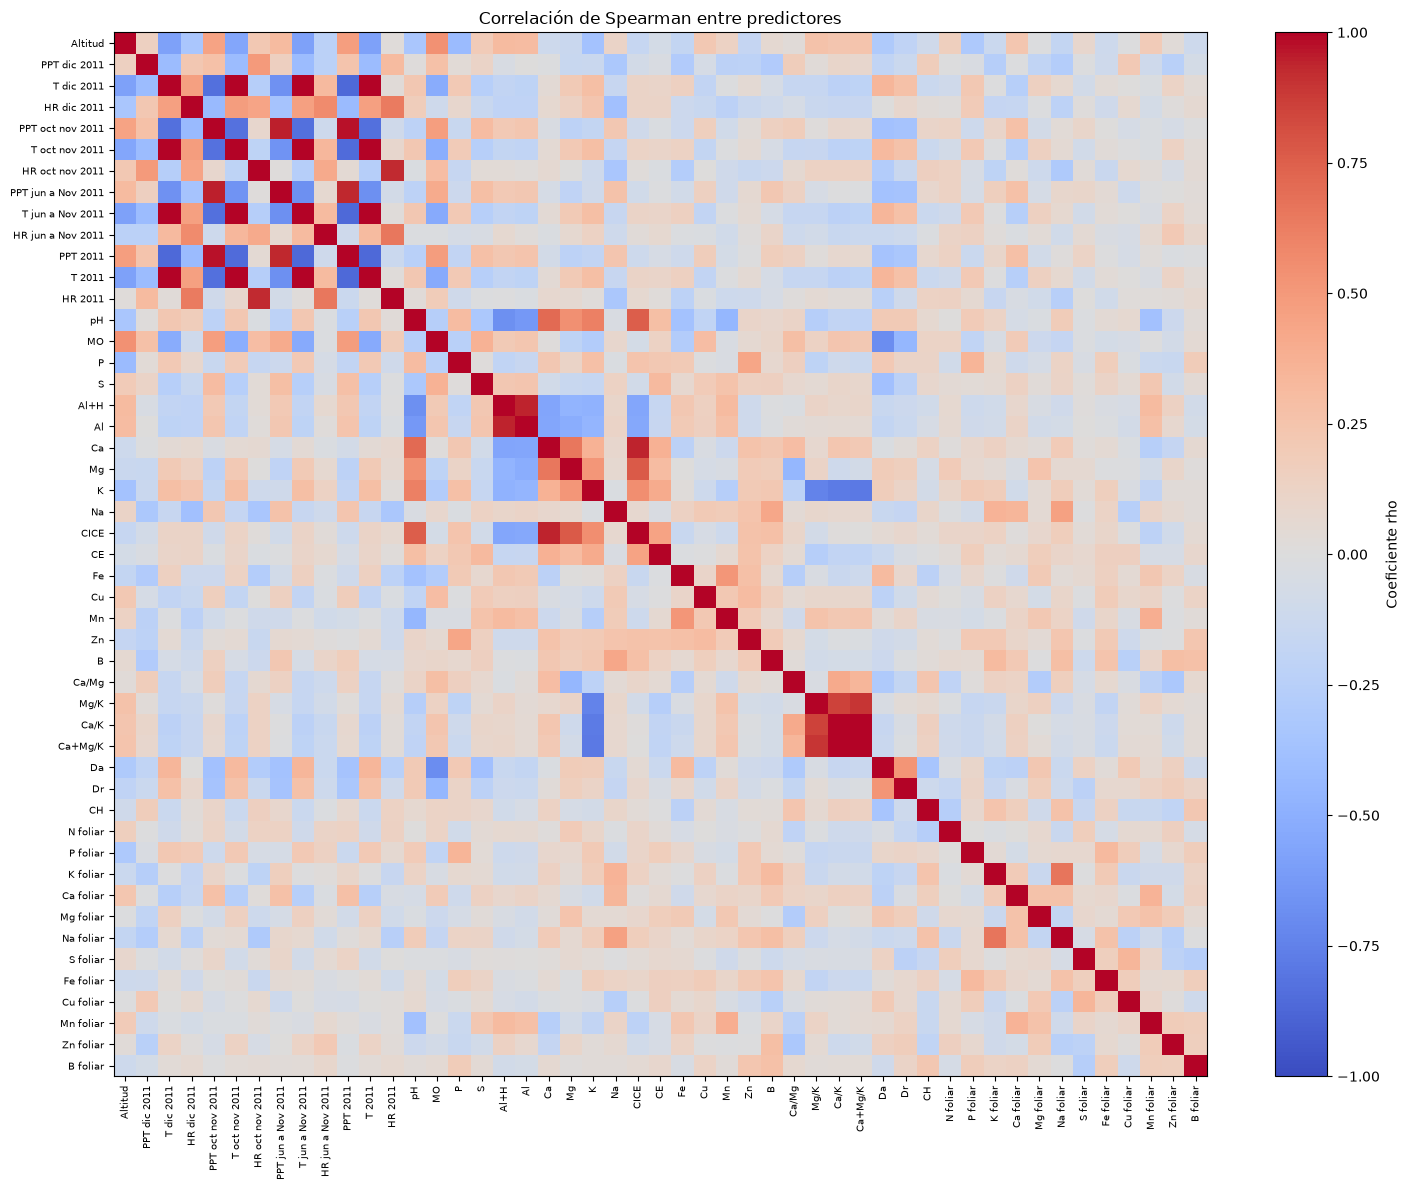

,Variable_1,Variable_2,Rho_Spearman,Correlacion_absoluta,Decision
0,T jun a Nov 2011,T 2011,1.000,1.000,Revisar para posible exclusion
1,T dic 2011,T 2011,1.000,1.000,Revisar para posible exclusion
2,T dic 2011,T jun a Nov 2011,1.000,1.000,Revisar para posible exclusion
3,Ca/K,Ca+Mg/K,0.996,0.996,Revisar para posible exclusion
4,T dic 2011,T oct nov 2011,0.995,0.995,Revisar para posible exclusion
5,T oct nov 2011,T 2011,0.995,0.995,Revisar para posible exclusion
6,T oct nov 2011,T jun a Nov 2011,0.995,0.995,Revisar para posible exclusion
7,PPT oct nov 2011,PPT 2011,0.969,0.969,Revisar para posible exclusion
8,PPT oct nov 2011,PPT jun a Nov 2011,0.947,0.947,Revisar para posible exclusion
9,Ca,CICE,0.944,0.944,Revisar para posible exclusion


In [6]:
# CORRELACIÓN DE SPEARMAN Y TABLA DE CORRELACIONES A REVISAR

correlaciones = datos[VARIABLES_PREDICTORAS].corr(method="spearman")

# MATRIZ DE CORRELACIÓN

fig, ax = plt.subplots(figsize=(15, 12))

imagen = ax.imshow(
    correlaciones,
    aspect="auto",
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

ax.set_xticks(range(len(correlaciones.columns)))
ax.set_yticks(range(len(correlaciones.index)))

ax.set_xticklabels(
    correlaciones.columns,
    rotation=90,
    fontsize=7
)

ax.set_yticklabels(
    correlaciones.index,
    fontsize=7
)

ax.set_title("Correlación de Spearman entre predictores")

fig.colorbar(imagen, ax=ax, label="Coeficiente rho")
plt.tight_layout()
plt.show()

# IDENTIFICAR PARES CON CORRELACIÓN ALTA

UMBRAL_CORRELACION = 0.80
pares_correlacion = []

columnas_corr = correlaciones.columns.tolist()

for i in range(len(columnas_corr)):
    for j in range(i + 1, len(columnas_corr)):

        rho = correlaciones.iloc[i, j]

        if pd.notna(rho) and abs(rho) >= UMBRAL_CORRELACION:
            pares_correlacion.append({
                "Variable_1": columnas_corr[i],
                "Variable_2": columnas_corr[j],
                "Rho_Spearman": rho,
                "Correlacion_absoluta": abs(rho),
                "Decision": "Revisar para posible exclusion"
            })

tabla_pares = pd.DataFrame(
    pares_correlacion,
    columns=[
        "Variable_1",
        "Variable_2",
        "Rho_Spearman",
        "Correlacion_absoluta",
        "Decision"
    ]
)

# MOSTRAR TABLA ORDENADA

if tabla_pares.empty:
    print("No se encontraron pares con |rho| >= 0.80.")
else:
    tabla_pares = tabla_pares.sort_values(
        "Correlacion_absoluta",
        ascending=False
    ).reset_index(drop=True)

    display(
        tabla_pares.style.format({
            "Rho_Spearman": "{:.3f}",
            "Correlacion_absoluta": "{:.3f}"
        }).background_gradient(
            subset=["Correlacion_absoluta"],
            cmap="YlOrRd"
        )
    )

## 3. Selección de predictores para el modelo

La lista inicial de predictores representa el conjunto de variables disponibles, pero no necesariamente debe entrar completa al modelo final. Incluir todos los predictores puede generar sobreajuste, dificultades de convergencia y estimaciones poco precisas.

Antes del ajuste, revisa los pares altamente correlacionados y conserva un conjunto de variables con justificación epidemiológica. Por ejemplo, puede ser preferible seleccionar una medida climática representativa de un periodo biológicamente relevante, en vez de introducir varias medidas redundantes de temperatura, precipitación y humedad relativa.

La selección debe quedar documentada en el protocolo de análisis. No se recomienda escoger variables únicamente por sus valores p en una secuencia de pruebas.

In [7]:
# =============================================================================
# SELECCIÓN DE PREDICTORES DESPUÉS DEL ANÁLISIS DE CORRELACIÓN
# =============================================================================

# Variables excluidas tras revisar la matriz de correlación de Spearman.
# Esta selección es preliminar y puede modificarse según el criterio científico.

VARIABLES_EXCLUIR_CORRELACION = [
    # Temperatura: conservar T 2011 como variable representativa
    "T jun a Nov 2011",
    "T dic 2011",
    "T oct nov 2011",

    # Precipitación: conservar PPT 2011 como variable representativa
    "PPT oct nov 2011",
    "PPT jun a Nov 2011",

    # Humedad relativa: conservar HR 2011 como variable representativa
    "HR oct nov 2011",

    # Variables químicas: evitar redundancia entre indicadores relacionados
    "Ca+Mg/K",
    "Ca",
    "Al+H",
    "Mg/K"
]

# Verificar que las variables indicadas existan entre los predictores
VARIABLES_EXCLUIR_CORRELACION = [
    c for c in VARIABLES_EXCLUIR_CORRELACION
    if c in VARIABLES_PREDICTORAS
]

# Construir la lista de predictores del modelo
FACTORES_MODELO = [
    c for c in VARIABLES_PREDICTORAS
    if c not in VARIABLES_EXCLUIR_CORRELACION
]

print("Variables excluidas por correlación:")
for nombre in VARIABLES_EXCLUIR_CORRELACION:
    print(" -", nombre)

# =============================================================================
# VERIFICAR VARIABLES CONSTANTES
# =============================================================================

variables_constantes = [
    c for c in FACTORES_MODELO
    if datos[c].nunique(dropna=True) <= 1
]

if variables_constantes:
    warnings.warn(
        f"Se excluirán variables constantes: {variables_constantes}"
    )

    FACTORES_MODELO = [
        c for c in FACTORES_MODELO
        if c not in variables_constantes
    ]

if len(FACTORES_MODELO) == 0:
    raise ValueError("No quedan predictores variables para modelar.")

# =============================================================================
# PREPARAR MATRICES DEL MODELO
# =============================================================================

# Verify missing values before standardization
if datos[FACTORES_MODELO].isna().any().any():
    raise ValueError(
        "Hay valores faltantes en los predictores seleccionados. "
        "Resuélvelos antes de estandarizar."
    )

if datos[RESPUESTA].isna().any():
    raise ValueError(
        "La variable respuesta contiene valores faltantes."
    )

# Standardize predictors
escalador = StandardScaler()
X = escalador.fit_transform(datos[FACTORES_MODELO])

X = np.asarray(X, dtype=float)
y = datos[RESPUESTA].to_numpy(dtype=int)

print("\nMatriz X:", X.shape)
print("Vector y:", y.shape)

print("\nPredictores incluidos:")
for nombre in FACTORES_MODELO:
    print(" -", nombre)

print("\nTotal de predictores incluidos:", len(FACTORES_MODELO))
print("Total de predictores excluidos por correlación:",
      len(VARIABLES_EXCLUIR_CORRELACION))
print("Total de variables constantes excluidas:",
      len(variables_constantes))

# =============================================================================
# COMPROBAR RELACIÓN ENTRE TAMAÑO MUESTRAL Y NÚMERO DE PREDICTORES
# =============================================================================

if len(datos) <= len(FACTORES_MODELO) + 1:
    raise ValueError(
        "Hay demasiados predictores en relación con el tamaño de la muestra. "
        "Reduce FACTORES_MODELO antes de ajustar los modelos."
    )


Variables excluidas por correlación:
 - T jun a Nov 2011
 - T dic 2011
 - T oct nov 2011
 - PPT oct nov 2011
 - PPT jun a Nov 2011
 - HR oct nov 2011
 - Ca+Mg/K
 - Ca
 - Al+H
 - Mg/K

Matriz X: (269, 39)
Vector y: (269,)

Predictores incluidos:
 - Altitud
 - PPT dic 2011
 - HR dic 2011
 - HR jun a Nov 2011
 - PPT 2011
 - T 2011
 - HR 2011
 - pH
 - MO
 - P
 - S
 - Al
 - Mg
 - K
 - Na
 - CICE
 - CE
 - Fe
 - Cu
 - Mn
 - Zn
 - B
 - Ca/Mg
 - Ca/K
 - Da
 - Dr
 - CH
 - N foliar
 - P foliar
 - K foliar
 - Ca foliar
 - Mg foliar
 - Na foliar
 - S foliar
 - Fe foliar
 - Cu foliar
 - Mn foliar
 - Zn foliar
 - B foliar

Total de predictores incluidos: 39
Total de predictores excluidos por correlación: 10
Total de variables constantes excluidas: 0


## 4. Cartografía de referencia

Se utilizará la cartografía municipal de Colombia, almacenada en el archivo `municipios_colombia.gpkg`, como fuente de referencia para delimitar el área de estudio correspondiente al departamento del Quindío y representar espacialmente sus municipios. Los polígonos administrativos se obtienen del archivo cartográfico local, cuya procedencia y versión deberán verificarse mediante sus metadatos.

La capa municipal se cargará en GeoPandas y se reproyectará al sistema de coordenadas MAGNA-SIRGAS / Origen-Nacional (EPSG:9377). A partir del código departamental se seleccionarán los municipios del Quindío y, cuando sea necesario, se construirá el polígono departamental mediante la disolución de sus límites municipales.

La cartografía permitirá verificar la localización de las observaciones, contextualizar los resultados epidemiológicos y generar representaciones espaciales a escala municipal. Los límites administrativos se utilizarán como referencia geográfica y no como evidencia de que el proceso epidemiológico presenta un comportamiento homogéneo dentro de cada municipio.

Antes de realizar los análisis espaciales, se comprobarán el sistema de referencia de coordenadas (CRS), la compatibilidad entre las coordenadas de las observaciones y la cartografía, y la validez de las geometrías. Asimismo, se documentarán las limitaciones derivadas de la resolución y la versión de los polígonos utilizados.

In [8]:
# =============================================================================
# LOAD DEPARTMENTS AND MUNICIPALITIES FROM THE ORIGINAL GEOPACKAGE
# =============================================================================

import geopandas as gpd
from pathlib import Path
from IPython.display import display

# Set the data folder used in the original workshop notebook
root_folder = Path(
    r"C:\Users\Luis G Bautista M\Documents\Doctorado\Geoprocesamiento\Taller1"
)

ruta_municipios = root_folder / "municipios_colombia.gpkg"

# Check that the GeoPackage exists
if not ruta_municipios.exists():
    raise FileNotFoundError(
        f"GeoPackage not found: {ruta_municipios}\n"
        "Check the file location before continuing."
    )

# Load the national municipalities layer
municipios = gpd.read_file(ruta_municipios)

if municipios.empty:
    raise ValueError("The municipalities GeoPackage contains no records.")

if municipios.crs is None:
    raise ValueError("The municipalities layer has no defined CRS.")

print("Initial CRS:", municipios.crs)
print("Municipalities loaded:", len(municipios))
print("Available fields:", municipios.columns.tolist())

# Reproject to EPSG:9377, following the original workshop
municipios = municipios.to_crs(epsg=9377)

# Identify the department code field
campo_departamento = next(
    (
        campo for campo in ["DPTO_CCDGO", "dpto_ccdgo"]
        if campo in municipios.columns
    ),
    None
)

if campo_departamento is None:
    raise KeyError(
        "The department code field was not found. "
        "Check the available fields printed above."
    )

# Identify the department name field, if available
campo_nombre_departamento = next(
    (
        campo for campo in ["DPTO_CNMBR", "dpto_cnmbr"]
        if campo in municipios.columns
    ),
    None
)

# Build department polygons by dissolving municipal boundaries
departamentos = municipios.dissolve(
    by=campo_departamento,
    aggfunc="first"
).reset_index()

# Report results
print("\nDepartments created:", len(departamentos))
print("Municipalities loaded:", len(municipios))
print("CRS departments:", departamentos.crs)
print("CRS municipalities:", municipios.crs)

Initial CRS: EPSG:3116
Municipalities loaded: 1122
Available fields: ['DPTO_CCDGO', 'MPIO_CCDGO', 'MPIO_CNMBR', 'MPIO_CDPMP', 'VERSION', 'AREA', 'LATITUD', 'LONGITUD', 'STCTNENCUE', 'STP3_1_SI', 'STP3_2_NO', 'STP3A_RI', 'STP3B_TCN', 'STP4_1_SI', 'STP4_2_NO', 'STP9_1_USO', 'STP9_2_USO', 'STP9_3_USO', 'STP9_4_USO', 'STP9_2_1_M', 'STP9_2_2_M', 'STP9_2_3_M', 'STP9_2_4_M', 'STP9_2_9_M', 'STP9_3_1_N', 'STP9_3_2_N', 'STP9_3_3_N', 'STP9_3_4_N', 'STP9_3_5_N', 'STP9_3_6_N', 'STP9_3_7_N', 'STP9_3_8_N', 'STP9_3_9_N', 'STP9_3_10', 'STP9_3_99', 'STVIVIENDA', 'STP14_1_TI', 'STP14_2_TI', 'STP14_3_TI', 'STP14_4_TI', 'STP14_5_TI', 'STP14_6_TI', 'STP15_1_OC', 'STP15_2_OC', 'STP15_3_OC', 'STP15_4_OC', 'TSP16_HOG', 'STP19_EC_1', 'STP19_ES_2', 'STP19_EE_1', 'STP19_EE_2', 'STP19_EE_3', 'STP19_EE_4', 'STP19_EE_5', 'STP19_EE_6', 'STP19_EE_9', 'STP19_ACU1', 'STP19_ACU2', 'STP19_ALC1', 'STP19_ALC2', 'STP19_GAS1', 'STP19_GAS2', 'STP19_GAS9', 'STP19_REC1', 'STP19_REC2', 'STP19_INT1', 'STP19_INT2', 'STP19_INT9', 'S

Department: Quindío
Department polygons: 1
Municipalities: 12
CRS: EPSG:9377


,DPTO_CCDGO,MPIO_CCDGO,MPIO_CNMBR
0,63,001,ARMENIA
1,63,111,BUENAVISTA
2,63,130,CALARCÁ
3,63,190,CIRCASIA
4,63,212,CÓRDOBA
5,63,272,FILANDIA
6,63,302,GÉNOVA
7,63,401,LA TEBAIDA
8,63,470,MONTENEGRO
9,63,548,PIJAO


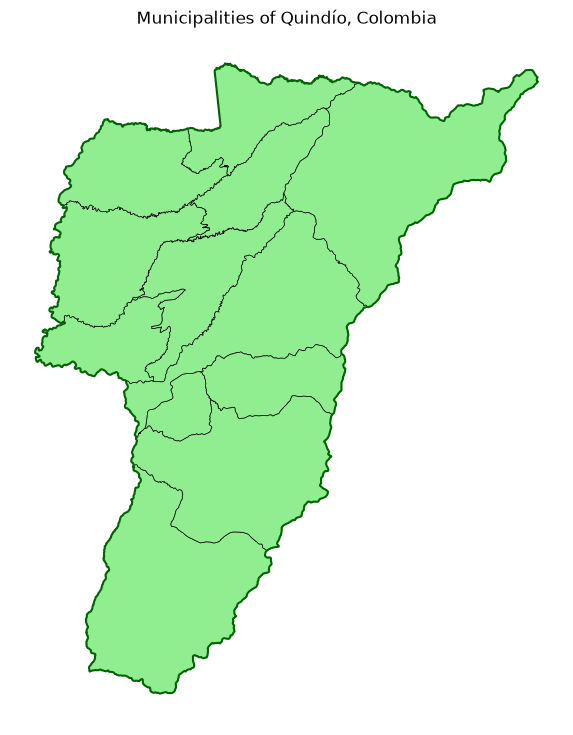

In [9]:
# =============================================================================
# SELECT QUINDÍO
# =============================================================================

# Define the correct field names
campo_departamento = "DPTO_CCDGO"
campo_nombre_municipio = "MPIO_CNMBR"

# Filter Quindío by its official department code (63)
quindio = departamentos[
    departamentos[campo_departamento].astype(str).str.strip().str.zfill(2) == "63"
].copy()

municipios_quindio = municipios[
    municipios[campo_departamento].astype(str).str.strip().str.zfill(2) == "63"
].copy()

if quindio.empty:
    raise ValueError(
        "Quindío was not found. Check the department code field and values."
    )

if municipios_quindio.empty:
    raise ValueError(
        "No municipalities were found for Quindío. Check the department codes."
    )

print("Department: Quindío")
print("Department polygons:", len(quindio))
print("Municipalities:", len(municipios_quindio))
print("CRS:", municipios_quindio.crs)

# Display municipality attributes
display(
    municipios_quindio[
        [
            campo_departamento,
            "MPIO_CCDGO",
            campo_nombre_municipio
        ]
    ].sort_values(campo_nombre_municipio).reset_index(drop=True)
)

# Plot Quindío and its municipalities
ax = municipios_quindio.plot(
    figsize=(9, 9),
    edgecolor="black",
    linewidth=0.5,
    color="lightgreen"
)

# Outline the department boundary
quindio.boundary.plot(
    ax=ax,
    color="darkgreen",
    linewidth=1.5
)

ax.set_title("Municipalities of Quindío, Colombia")
ax.set_axis_off()

In [10]:
# Create the unified geometry of Quindío in WGS 84
geometria_quindio = quindio.geometry.union_all()

## 5. Construcción de la capa de sitios observados

Cada observación se convertirá en un punto geográfico a partir de sus coordenadas. Los puntos se mantendrán en EPSG:4326 para visualización y se transformarán a EPSG:32618 para el cálculo de distancias euclidianas en kilómetros.

La estructura espacial del modelo se construirá a partir de estas distancias. La función de covarianza Matérn 3/2 representa una dependencia espacial cuya intensidad disminuye a medida que aumenta la separación entre los sitios (Banerjee et al., 2014; Cressie & Wikle, 2011).

Se comprobará si los puntos caen dentro del límite departamental. Un punto fuera del polígono no implica necesariamente que la observación sea errónea, pero debe verificarse su coordenada, el sistema de referencia y la unidad espacial de registro.

In [11]:
# =============================================================================
# POINTS, PROJECTION AND SPATIAL VALIDATION
# =============================================================================

# Create observation points in WGS 84
puntos = gpd.GeoDataFrame(
    datos.reset_index(drop=True).copy(),
    geometry=gpd.points_from_xy(
        datos[LONGITUD].to_numpy(),
        datos[LATITUD].to_numpy()
    ),
    crs="EPSG:4326"
)

puntos["id_observacion"] = np.arange(1, len(puntos) + 1)

# Reproject all observations and boundaries to MAGNA-SIRGAS / Origen-Nacional
puntos_utm = puntos.to_crs("EPSG:9377")
quindio_utm = quindio.to_crs("EPSG:9377")
municipios_utm = municipios_quindio.to_crs("EPSG:9377")

# Create metric coordinates in kilometers for the Gaussian process
coords_km = np.column_stack([
    puntos_utm.geometry.x.to_numpy() / 1000.0,
    puntos_utm.geometry.y.to_numpy() / 1000.0
])

print("Total observations:", len(puntos))
print("Total coordinates:", len(coords_km))

print("\nProjected coordinate extent (km):")
print("X:", coords_km[:, 0].min(), "to", coords_km[:, 0].max())
print("Y:", coords_km[:, 1].min(), "to", coords_km[:, 1].max())

# Validate observations against the Quindío boundary in WGS 84
geometria_quindio = quindio.to_crs("EPSG:4326").geometry.union_all()

puntos["dentro_quindio"] = puntos.geometry.within(
    geometria_quindio
)

print("\nObservations inside the department boundary:")
print(puntos["dentro_quindio"].value_counts(dropna=False))

# Report observations outside Quindío without removing them
if (~puntos["dentro_quindio"]).any():
    display(
        puntos.loc[
            ~puntos["dentro_quindio"],
            ["id_observacion", LATITUD, LONGITUD, RESPUESTA]
        ]
    )

    warnings.warn(
        "Some observations fall outside Quindío. "
        "They have been retained in the dataset."
    )

# Export all observations, including those outside Quindío
puntos.to_file(
    CARPETA_RESULTADOS / "sitios_observados.geojson",
    driver="GeoJSON"
)

puntos_utm.to_file(
    CARPETA_RESULTADOS / "sitios_observados_utm.geojson",
    driver="GeoJSON"
)


Total observations: 269
Total coordinates: 269

Projected coordinate extent (km):
X: 4676.508823243532 to 4709.30211561913
Y: 2020.7444902567734 to 2072.4453363419825

Observations inside the department boundary:
dentro_quindio
True     268
False      1
Name: count, dtype: int64


,id_observacion,Latitud,Longitud,Incidencia
122,123,4.533361,-75.916111,1


C:\Users\Luis G Bautista M\AppData\Local\Temp\ipykernel_5276\2785348746.py:54: UserWarning: Some observations fall outside Quindío. They have been retained in the dataset.
  warnings.warn(


## 6. Mapa de incidencia observada

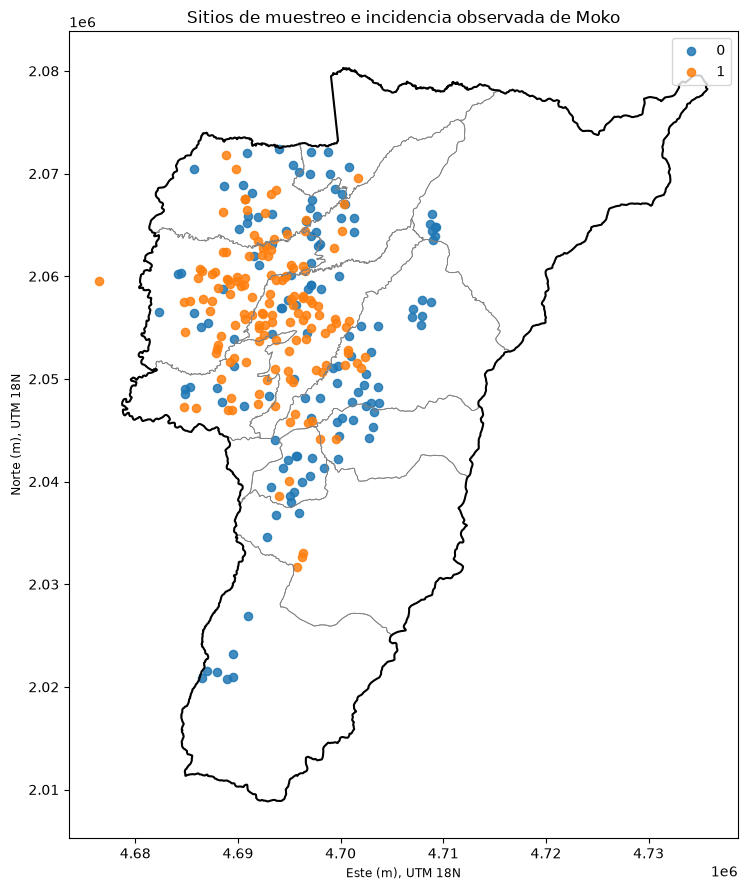

In [12]:
fig, ax = plt.subplots(figsize=(9, 9))

municipios_utm.boundary.plot(
    ax=ax, linewidth=0.6, color="gray"
)
quindio_utm.boundary.plot(
    ax=ax, linewidth=1.5, color="black"
)

puntos_utm.plot(
    ax=ax,
    column=RESPUESTA,
    categorical=True,
    legend=True,
    markersize=35,
    alpha=0.85
)

ax.set_title("Sitios de muestreo e incidencia observada de Moko")
ax.set_xlabel("Este (m), UTM 18N")
ax.set_ylabel("Norte (m), UTM 18N")
ax.set_aspect("equal")
plt.tight_layout()
plt.savefig(
    CARPETA_RESULTADOS / "mapa_incidencia_observada.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 7. Ajuste de la regresión logística convencional

Este modelo no representa explícitamente la autocorrelación espacial. Por ello, si las observaciones cercanas presentan respuestas similares, la independencia entre observaciones podría incumplirse y la incertidumbre de los coeficientes podría estimarse incorrectamente. Asimismo, el ajuste puede verse afectado por tamaños muestrales limitados, separación y colinealidad entre predictores. La comparación con un modelo que incorpore la estructura espacial permitirá evaluar si considerar dicha estructura mejora la explicación o la predicción de la presencia del Moko (Agresti, 2013).

In [13]:
X_logit = sm.add_constant(X, has_constant="add")

modelo_logistico = sm.GLM(
    y,
    X_logit,
    family=sm.families.Binomial()
)

resultado_logistico = modelo_logistico.fit(maxiter=300)

print(resultado_logistico.summary())

nombres_parametros = ["Intercepto"] + FACTORES_MODELO

coef = np.asarray(resultado_logistico.params)
errores = np.asarray(resultado_logistico.bse)
estadisticos = np.asarray(resultado_logistico.tvalues)
valores_p = np.asarray(resultado_logistico.pvalues)
intervalos = np.asarray(resultado_logistico.conf_int())

tabla_logistica = pd.DataFrame({
    "variable": nombres_parametros,
    "coeficiente": coef,
    "error_estandar": errores,
    "estadistico_z": estadisticos,
    "valor_p": valores_p,
    "IC95_inferior": intervalos[:, 0],
    "IC95_superior": intervalos[:, 1],
})

tabla_logistica["OR"] = np.exp(tabla_logistica["coeficiente"])
tabla_logistica["OR_IC95_inferior"] = np.exp(
    tabla_logistica["IC95_inferior"]
)
tabla_logistica["OR_IC95_superior"] = np.exp(
    tabla_logistica["IC95_superior"]
)

display(tabla_logistica)

tabla_logistica.to_csv(
    CARPETA_RESULTADOS / "coeficientes_regresion_logistica.csv",
    index=False,
    encoding="utf-8-sig"
)

print("AIC:", resultado_logistico.aic)
print("BIC:", resultado_logistico.bic)
print("Log-verosimilitud:", resultado_logistico.llf)

                 Generalized Linear Model Regression Results                  
Dep. Variable:                      y   No. Observations:                  269
Model:                            GLM   Df Residuals:                      229
Model Family:                Binomial   Df Model:                           39
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -121.17
Date:                Tue, 13 Oct 2026   Deviance:                       242.35
Time:                        10:28:56   Pearson chi2:                     350.
No. Iterations:                     6   Pseudo R-squ. (CS):             0.3838
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0640      0.183      0.350      0.7

,variable,coeficiente,error_estandar,estadistico_z,valor_p,IC95_inferior,IC95_superior,OR,OR_IC95_inferior,OR_IC95_superior
0,Intercepto,0.063975,0.182703,0.350160,0.726218,-0.294116,0.422066,1.066066,0.745190,1.525109
1,Altitud,-1.260246,0.351741,-3.582884,0.000340,-1.949645,-0.570847,0.283584,0.142325,0.565047
2,PPT dic 2011,-0.205040,0.459742,-0.445990,0.655605,-1.106118,0.696037,0.814615,0.330841,2.005789
3,HR dic 2011,1.431883,0.851158,1.682276,0.092515,-0.236357,3.100122,4.186574,0.789499,22.200664
4,HR jun a Nov 2011,-0.298992,0.859373,-0.347919,0.727901,-1.983332,1.385347,0.741565,0.137610,3.996214
5,PPT 2011,-0.105367,0.471531,-0.223457,0.823180,-1.029550,0.818816,0.899994,0.357168,2.267814
6,T 2011,-0.169259,0.438013,-0.386424,0.699183,-1.027748,0.689230,0.844290,0.357812,1.992182
7,HR 2011,-1.069134,0.898993,-1.189258,0.234338,-2.831127,0.692859,0.343306,0.058946,1.999424
8,pH,0.651523,0.433811,1.501859,0.133134,-0.198731,1.501778,1.918461,0.819770,4.489663
9,MO,-0.021155,0.349471,-0.060534,0.951730,-0.706106,0.663796,0.979067,0.493562,1.942151


AIC: 322.34535209652853
BIC: 466.1338072806021
Log-verosimilitud: -121.17267604826426


**Ecuación del modelo con parámetros significativos:** incluye únicamente los predictores cuyos coeficientes presentan significación estadística, según el criterio establecido anteriromente.

In [14]:
# =============================================================================
# LOGISTIC REGRESSION EQUATION - SIGNIFICANT PREDICTORS ONLY
# =============================================================================

import numpy as np

# Extract estimated coefficients and p-values
coeficientes = np.asarray(resultado_logistico.params).flatten()
valores_p = np.asarray(resultado_logistico.pvalues).flatten()

nombres = ["Intercepto"] + list(FACTORES_MODELO)

# Select significant predictors (p < 0.05), always retaining the intercept
indices_significativos = [
    i for i, p_valor in enumerate(valores_p)
    if i == 0 or p_valor < 0.05
]

# Build the equation
terminos = []

for i in indices_significativos:
    variable = nombres[i]
    beta = coeficientes[i]

    if i == 0:
        terminos.append(f"({beta:.6f})")
    else:
        signo = "+" if beta >= 0 else "-"
        terminos.append(
            f" {signo} {abs(beta):.6f}*({variable})"
        )

ecuacion_logit = "logit(p) = " + "".join(terminos)

print("LOGISTIC REGRESSION EQUATION - SIGNIFICANT PREDICTORS")
print(ecuacion_logit)

print("\nPROBABILITY EQUATION")
print("p = 1 / (1 + exp(-eta))")

print("\nSignificant predictors:")
for i in indices_significativos:
    if i != 0:
        print(f"{nombres[i]}: p = {valores_p[i]:.6f}")

LOGISTIC REGRESSION EQUATION - SIGNIFICANT PREDICTORS
logit(p) = (0.063975) - 1.260246*(Altitud) + 1.840275*(S) + 0.561728*(Fe) - 0.779756*(Cu) + 0.631955*(CH) + 0.410158*(N foliar) - 0.544285*(Na foliar)

PROBABILITY EQUATION
p = 1 / (1 + exp(-eta))

Significant predictors:
Altitud: p = 0.000340
S: p = 0.003430
Fe: p = 0.030488
Cu: p = 0.020165
CH: p = 0.028211
N foliar: p = 0.026419
Na foliar: p = 0.010259


**Estadisticas del modelo:** evaluación del ajuste y la capacidad de clasificación del modelo mediante indicadores como AIC, BIC, sensibilidad, especificidad, exactitud y AUC-ROC, complementados con la curva ROC.

Observaciones: 269
Presencias: 139
Ausencias: 130


,Metrica,Valor
0,Observaciones,269.0000
1,Numero de parametros,40.0000
2,Log-verosimilitud,-121.1727
3,Devianza,242.3454
4,AIC,322.3454
5,BIC,466.1338
6,R2 tradicional,NaN
7,R2 ajustado tradicional,NaN
8,Pseudo-R2 de McFadden,0.3496
9,Pseudo-R2 ajustado de McFadden,0.1349


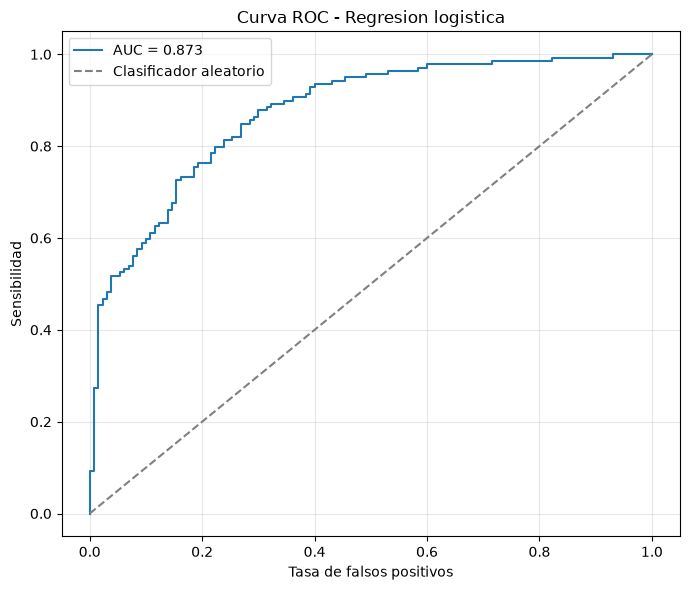

,Predicho 0,Predicho 1
Observado 0,95,35
Observado 1,22,117



Metricas calculadas correctamente.
Resultados guardados en: C:\Users\Luis G Bautista M\Documents\Doctorado\Análisis_Epidemiológico\Seminarios\Landscape Epidemiology\resultados_moko_quindio


In [45]:

# =============================================================================
# MODEL 1. LOGISTIC REGRESSION - EVALUATION METRICS
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error
)

# -------------------------------------------------------------------------
# 1. OBSERVED VALUES AND PREDICTED PROBABILITIES
# -------------------------------------------------------------------------

y_m1 = np.asarray(
    resultado_logistico.model.endog,
    dtype=int
).ravel()

p_m1 = np.asarray(
    resultado_logistico.predict(),
    dtype=float
).ravel()

if len(y_m1) != len(p_m1):
    raise ValueError(
        f"Las dimensiones no coinciden: {len(y_m1)} observaciones y "
        f"{len(p_m1)} predicciones."
    )

if not np.isin(y_m1, [0, 1]).all():
    raise ValueError("La respuesta debe contener únicamente 0 y 1.")

if not np.isfinite(p_m1).all():
    raise ValueError("Las predicciones contienen valores no finitos.")

if len(np.unique(y_m1)) != 2:
    raise ValueError("La respuesta debe contener presencias y ausencias.")

p_m1 = np.clip(p_m1, 0, 1)

print("Observaciones:", len(y_m1))
print("Presencias:", int(np.sum(y_m1 == 1)))
print("Ausencias:", int(np.sum(y_m1 == 0)))

# -------------------------------------------------------------------------
# 2. CLASSIFICATION METRICS
# -------------------------------------------------------------------------

umbral_m1 = 0.50
clase_m1 = (p_m1 >= umbral_m1).astype(int)

vn, fp, fn, vp = confusion_matrix(
    y_m1,
    clase_m1,
    labels=[0, 1]
).ravel()

sensibilidad_m1 = vp / (vp + fn) if (vp + fn) else np.nan
especificidad_m1 = vn / (vn + fp) if (vn + fp) else np.nan
exactitud_m1 = (vp + vn) / len(y_m1)

# -------------------------------------------------------------------------
# 3. PREDICTIVE METRICS
# -------------------------------------------------------------------------

mae_m1 = mean_absolute_error(y_m1, p_m1)
mse_m1 = mean_squared_error(y_m1, p_m1)
bias_m1 = np.mean(p_m1 - y_m1)
auc_m1 = roc_auc_score(y_m1, p_m1)

# -------------------------------------------------------------------------
# 4. MODEL FIT METRICS
# -------------------------------------------------------------------------

n_m1 = len(y_m1)
k_m1 = len(resultado_logistico.params)

ll_m1 = float(resultado_logistico.llf)
aic_m1 = float(resultado_logistico.aic)
bic_m1 = float(resultado_logistico.bic_llf)
devianza_m1 = float(resultado_logistico.deviance)

# McFadden pseudo-R2
prevalencia_m1 = np.clip(
    np.mean(y_m1),
    1e-15,
    1 - 1e-15
)

ll_nulo_m1 = np.sum(
    y_m1 * np.log(prevalencia_m1)
    + (1 - y_m1) * np.log(1 - prevalencia_m1)
)

pseudo_r2_m1 = 1 - ll_m1 / ll_nulo_m1

# Adjusted McFadden pseudo-R2
pseudo_r2_ajustado_m1 = (
    1 - (ll_m1 - k_m1) / ll_nulo_m1
)

# -------------------------------------------------------------------------
# 5. METRICS TABLE
# -------------------------------------------------------------------------

metricas_m1 = pd.DataFrame({
    "Metrica": [
        "Observaciones",
        "Numero de parametros",
        "Log-verosimilitud",
        "Devianza",
        "AIC",
        "BIC",
        "R2 tradicional",
        "R2 ajustado tradicional",
        "Pseudo-R2 de McFadden",
        "Pseudo-R2 ajustado de McFadden",
        "MAE",
        "MSE (Brier)",
        "Sesgo medio (predicho - observado)",
        "AUC-ROC",
        "Umbral de clasificacion",
        "Sensibilidad",
        "Especificidad",
        "Exactitud",
        "Verdaderos negativos",
        "Falsos positivos",
        "Falsos negativos",
        "Verdaderos positivos"
    ],
    "Valor": [
        n_m1,
        k_m1,
        ll_m1,
        devianza_m1,
        aic_m1,
        bic_m1,
        np.nan,
        np.nan,
        pseudo_r2_m1,
        pseudo_r2_ajustado_m1,
        mae_m1,
        mse_m1,
        bias_m1,
        auc_m1,
        umbral_m1,
        sensibilidad_m1,
        especificidad_m1,
        exactitud_m1,
        vn,
        fp,
        fn,
        vp
    ]
})

display(metricas_m1.round(4))

# -------------------------------------------------------------------------
# 6. ROC CURVE
# -------------------------------------------------------------------------

fpr_m1, tpr_m1, _ = roc_curve(y_m1, p_m1)

plt.figure(figsize=(7, 6))
plt.plot(fpr_m1, tpr_m1, label=f"AUC = {auc_m1:.3f}")
plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Clasificador aleatorio"
)
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Sensibilidad")
plt.title("Curva ROC - Regresion logistica")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    CARPETA_RESULTADOS / "modelo1_curva_roc.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# -------------------------------------------------------------------------
# 7. CONFUSION MATRIX
# -------------------------------------------------------------------------

matriz_confusion_m1 = pd.DataFrame(
    [[vn, fp], [fn, vp]],
    index=["Observado 0", "Observado 1"],
    columns=["Predicho 0", "Predicho 1"]
)

display(matriz_confusion_m1)

# -------------------------------------------------------------------------
# 8. EXPORT RESULTS
# -------------------------------------------------------------------------

metricas_m1.to_csv(
    CARPETA_RESULTADOS / "modelo1_metricas.csv",
    index=False,
    encoding="utf-8-sig"
)

matriz_confusion_m1.to_csv(
    CARPETA_RESULTADOS / "modelo1_matriz_confusion.csv",
    encoding="utf-8-sig"
)

with pd.ExcelWriter(
    CARPETA_RESULTADOS / "modelo1_resultados.xlsx"
) as writer:
    metricas_m1.to_excel(
        writer,
        sheet_name="Metricas",
        index=False
    )
    matriz_confusion_m1.to_excel(
        writer,
        sheet_name="Matriz_confusion"
    )

print("\nMetricas calculadas correctamente.")
print("Resultados guardados en:", CARPETA_RESULTADOS.resolve())


### 8. Regresión logística bayesiana con presión explícita del paisaje

Se estima la probabilidad de presencia de Moko mediante una regresión logística bayesiana que incorpora siete variables explicativas y una covariable explícita de presión del paisaje. Se utilizan distribuciones previas normales y una verosimilitud Bernoulli. Las distancias euclidianas entre los 269 registros permiten identificar coincidencias espaciales, detectándose un par de observaciones con coordenadas idénticas de muestreo. El modelo incorpora la presión del paisaje como covariable, pero no incluye un efecto aleatorio CAR ni un proceso gaussiano espacial. Los resultados actuales son preliminares debido a los bajos tamaños efectivos de muestra y al uso de una sola cadena de muestreo.

**Distancias entre sitios:** se calculan las distancias euclidianas entre los 269 registros y se construye una matriz binaria de vecindad con un umbral de 20 km.

In [17]:

from scipy.spatial.distance import cdist

n = len(datos)

# calcular distancias euclidianas entre sitios, en kilómetros
distancias_km = cdist(coords_km, coords_km, metric="euclidean")

print("Matriz de distancias:", distancias_km.shape)
print("Distancia máxima (km):", float(distancias_km.max()))

distancias_positivas = distancias_km[distancias_km > 0]
print(
    "Distancia mínima positiva (km):",
    float(distancias_positivas.min())
)

# identificar pares de observaciones con coordenadas idénticas
n_pares_misma_ubicacion = int(
    np.sum(np.triu(distancias_km == 0, k=1))
)

print(
    "Pares de observaciones con coordenadas idénticas:",
    n_pares_misma_ubicacion
)

if n_pares_misma_ubicacion > 0:
    warnings.warn(
        "Hay coordenadas idénticas. Verifica si corresponden "
        "a mediciones repetidas o a registros diferentes."
    )

# construir la matriz binaria de vecindad con un umbral de 20 km
UMBRAL_VECINDAD_KM = 20.0

W_fincas = (
    (distancias_km > 0) &
    (distancias_km <= UMBRAL_VECINDAD_KM)
).astype(float)

# excluir la diagonal
np.fill_diagonal(W_fincas, 0)

print("Dimensiones de W_fincas:", W_fincas.shape)
print("Pares vecinos:", int(W_fincas.sum() / 2))
print(
    "Observaciones sin vecinos:",
    int((W_fincas.sum(axis=1) == 0).sum())
)


Matriz de distancias: (269, 269)
Distancia máxima (km): 52.75359412370093
Distancia mínima positiva (km): 0.04140529378217313
Pares de observaciones con coordenadas idénticas: 1
Dimensiones de W_fincas: (269, 269)
Pares vecinos: 29148
Observaciones sin vecinos: 0


C:\Users\Luis G Bautista M\AppData\Local\Temp\ipykernel_5276\1915226855.py:28: UserWarning: Hay coordenadas idénticas. Verifica si corresponden a mediciones repetidas o a registros diferentes.
  warnings.warn(


**Construir la matriz binaria de vecindad:** matriz que indica con 1 si dos sitios son vecinos según el umbral de distancia establecido y con 0 si no lo son. La diagonal se fija en 0.

In [18]:
# construir la matriz binaria de vecindad de 20 km
W_fincas = (
    (distancias_km > 0) &
    (distancias_km <= 20)
).astype(float)

# excluir la diagonal: ninguna observación es vecina de sí misma
np.fill_diagonal(W_fincas, 0)

print("Dimensiones de W_fincas:", W_fincas.shape)
print("Número de pares vecinos:", int(W_fincas.sum() / 2))
print("Observaciones sin vecinos:", int((W_fincas.sum(axis=1) == 0).sum()))

Dimensiones de W_fincas: (269, 269)
Número de pares vecinos: 29148
Observaciones sin vecinos: 0


**Especificación y muestreo bayesiano:** Ajuste de una regresión logística bayesiana con un efecto de presión del paisaje, mediante una cadena de muestreo, para estimar los efectos de los predictores, las probabilidades del evento y la incertidumbre de las estimaciones. Esta configuración se utiliza para reducir el tiempo de ejecución y el consumo de recursos computacionales, por lo que los resultados deben interpretarse con cautela.

In [19]:
# =============================================================================
# MODELO LOGÍSTICO BAYESIANO CON EFECTO DE PRESIÓN DEL PAISAJE
# =============================================================================

import pymc as pm
import pytensor
import numpy as np
import pandas as pd

# -------------------------------------------------------------------------
# 1. calcular la presión del paisaje
# -------------------------------------------------------------------------

incidencia_observada = df["Incidencia"].to_numpy(dtype=float)

if W_fincas.shape != (len(df), len(df)):
    raise ValueError(
        f"W_fincas tiene dimensiones {W_fincas.shape}, "
        f"pero se esperaban {(len(df), len(df))}."
    )

if not np.isin(incidencia_observada, [0, 1]).all():
    raise ValueError(
        "La variable Incidencia debe contener únicamente valores 0 y 1."
    )

incidencia_vecinos = W_fincas @ incidencia_observada
total_vecinos = np.sum(W_fincas, axis=1)

total_vecinos_seguro = np.where(total_vecinos == 0, 1, total_vecinos)

efecto_paisaje_observacion = (
    incidencia_vecinos / total_vecinos_seguro
)

print("Observaciones:", len(df))
print("Casos con presencia:", int(incidencia_observada.sum()))
print("Casos sin presencia:", int(len(incidencia_observada) - incidencia_observada.sum()))

# -------------------------------------------------------------------------
# 2. configurar el muestreo
# -------------------------------------------------------------------------

DRAWS = 1000
TUNE = 500
CHAINS = 1
CORES = 1

# -------------------------------------------------------------------------
# 3. seleccionar y estandarizar los predictores
# -------------------------------------------------------------------------

FACTORES_MODELO = [
    "Altitud",
    "S",
    "Fe",
    "Cu",
    "CH",
    "N foliar",
    "Na foliar"
]

FACTORES_MODELO_REALES = [
    f if f in df.columns else f.replace(" ", "_")
    for f in FACTORES_MODELO
]

variables_faltantes = [
    f for f in FACTORES_MODELO_REALES
    if f not in df.columns
]

if variables_faltantes:
    raise ValueError(
        f"Faltan predictores en df: {variables_faltantes}"
    )

X_modelo = df[FACTORES_MODELO_REALES].to_numpy(dtype=float)

if not np.isfinite(X_modelo).all():
    raise ValueError(
        "Los predictores contienen valores NaN o infinitos. "
        "Debes corregirlos antes del ajuste."
    )

medias = X_modelo.mean(axis=0)
desviaciones = X_modelo.std(axis=0)

variables_constantes = [
    FACTORES_MODELO_REALES[i]
    for i, desviacion in enumerate(desviaciones)
    if desviacion == 0
]

if variables_constantes:
    raise ValueError(
        f"Hay predictores sin variación: {variables_constantes}"
    )

X_estandarizado = (X_modelo - medias) / desviaciones

coords_modelo = {
    "predictor": FACTORES_MODELO_REALES,
    "observacion": np.arange(len(df))
}

# -------------------------------------------------------------------------
# 4. definir el modelo logístico bayesiano
# -------------------------------------------------------------------------

with pm.Model(coords=coords_modelo) as modelo_espacial_rapido:

    X_data = pm.Data(
        "X_data",
        X_estandarizado,
        dims=("observacion", "predictor")
    )

    y_obs_data = pm.Data(
        "y_obs_data",
        incidencia_observada.astype("int32"),
        dims="observacion"
    )

    paisaje_data = pm.Data(
        "paisaje_data",
        efecto_paisaje_observacion,
        dims="observacion"
    )

    intercepto = pm.Normal(
        "intercepto",
        mu=0,
        sigma=2
    )

    beta = pm.Normal(
        "beta",
        mu=0,
        sigma=1,
        dims="predictor"
    )

    beta_espacial = pm.Normal(
        "beta_espacial",
        mu=0,
        sigma=2
    )

    eta = (
        intercepto
        + pm.math.dot(X_data, beta)
        + beta_espacial * paisaje_data
    )

    p_espacial = pm.Deterministic(
        "p",
        pm.math.sigmoid(eta),
        dims="observacion"
    )

    y_obs = pm.Bernoulli(
        "y_obs",
        p=p_espacial,
        observed=y_obs_data,
        dims="observacion"
    )

# -------------------------------------------------------------------------
# 5. muestrear sin utilizar la compilación problemática de C++
# -------------------------------------------------------------------------

with pytensor.config.change_flags(cxx=""):
    with modelo_espacial_rapido:
        step_method = pm.Metropolis()

        idata = pm.sample(
            draws=DRAWS,
            tune=TUNE,
            chains=CHAINS,
            cores=CORES,
            step=step_method,
            progressbar=True,
            random_seed=42,
            return_inferencedata=True
        )

# -------------------------------------------------------------------------
# 6. confirmar la finalización
# -------------------------------------------------------------------------

print("\nMUESTREO BAYESIANO FINALIZADO")
print("Resultados disponibles:", "idata" in globals())
print("Predictores incluidos:", FACTORES_MODELO_REALES)

Observaciones: 269
Casos con presencia: 139
Casos sin presencia: 130


Sequential sampling (1 chains in 1 job)
CompoundStep
>Metropolis: [intercepto]
>Metropolis: [beta]
>Metropolis: [beta_espacial]


Output()

Sampling 1 chain for 500 tune and 1_000 draw iterations (500 + 1_000 draws total) took 416 seconds.
Only one chain was sampled, this makes it impossible to run some convergence checks



MUESTREO BAYESIANO FINALIZADO
Resultados disponibles: True
Predictores incluidos: ['Altitud', 'S', 'Fe', 'Cu', 'CH', 'N foliar', 'Na foliar']


In [20]:
import arviz as az

# 1. Generar la tabla resumen ajustada al nuevo modelo de presión del paisaje
resumen = pm.summary(idata, var_names=["intercepto", "beta", "beta_espacial"])

# 2. Configurar la lista exacta de nombres de filas (1 Intercepto + 7 Predictores + 1 Efecto Espacial)
nombres_variables = ["Intercepto"] + FACTORES_MODELO_REALES + ["Presión del Paisaje (Beta Espacial)"]
resumen.index = nombres_variables

print("=====================================================================")
print("     RESULTADOS FINALES DE LA REGRESIÓN LOGÍSTICA ESPACIAL           ")
print("=====================================================================")
display(resumen)

arviz - WARNING - Shape validation failed: input_shape: (1, 1000), minimum_shape: (chains=2, draws=4)


     RESULTADOS FINALES DE LA REGRESIÓN LOGÍSTICA ESPACIAL           


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercepto,2.262,0.621,1.049,3.313,0.187,0.087,12.0,16.0,NaN
Altitud,-1.536,0.220,-2.026,-1.230,0.024,0.014,84.0,118.0,NaN
S,0.641,0.323,0.048,1.247,0.026,0.016,161.0,187.0,NaN
Fe,0.182,0.157,-0.099,0.437,0.013,0.009,139.0,129.0,NaN
Cu,-0.703,0.289,-1.206,-0.174,0.022,0.016,168.0,180.0,NaN
CH,0.452,0.186,0.117,0.818,0.017,0.013,113.0,153.0,NaN
N foliar,0.260,0.151,-0.052,0.499,0.014,0.009,119.0,112.0,NaN
Na foliar,-0.278,0.139,-0.524,-0.010,0.013,0.009,118.0,96.0,NaN
Presión del Paisaje (Beta Espacial),-4.158,1.153,-6.210,-2.030,0.346,0.157,12.0,26.0,NaN


In [51]:
# =============================================================================
# ECUACION DEL MODELO BAYESIANO Y EVIDENCIA DE LOS PARAMETROS SELECCIONADOS
# =============================================================================

import numpy as np
from pathlib import Path

# 1. Identificar los limites del intervalo creible del 95 %
columnas_hdi = [c for c in resumen.columns if c.startswith("hdi_")]

columna_inferior = min(
    columnas_hdi,
    key=lambda c: float(c.replace("hdi_", "").replace("%", ""))
)
columna_superior = max(
    columnas_hdi,
    key=lambda c: float(c.replace("hdi_", "").replace("%", ""))
)

# 2. Seleccionar parametros cuyo intervalo creible excluye cero
variables_seleccionadas = ["Intercepto"]

for variable in resumen.index:
    if variable == "Intercepto":
        continue

    inferior = resumen.loc[variable, columna_inferior]
    superior = resumen.loc[variable, columna_superior]

    if inferior > 0 or superior < 0:
        variables_seleccionadas.append(variable)

# 3. Construir la ecuacion con las medias posteriores
terminos = [f"{resumen.loc['Intercepto', 'mean']:.4f}"]

for variable in variables_seleccionadas[1:]:
    beta = resumen.loc[variable, "mean"]

    if variable == "Presion_paisaje":
        nombre = "Presion_paisaje"
    else:
        nombre = f"X_{variable.replace(' ', '_')}"

    signo = "+" if beta >= 0 else "-"
    terminos.append(f" {signo} {abs(beta):.4f}*{nombre}")

ecuacion = "logit(p) = " + "".join(terminos)

# 4. Mostrar la ecuacion
print("=" * 75)
print("ECUACION DEL MODELO BAYESIANO")
print("=" * 75)
print(ecuacion)

print("\nPARAMETROS CON HDI DEL 95 % QUE EXCLUYE CERO")
print("-" * 75)

# 5. Mostrar coeficientes, intervalos y probabilidad posterior
for variable in variables_seleccionadas:
    if variable == "Intercepto":
        continue

    media = resumen.loc[variable, "mean"]
    inferior = resumen.loc[variable, columna_inferior]
    superior = resumen.loc[variable, columna_superior]

    if variable == "Presion_paisaje":
        muestras = idata.posterior["beta_espacial"].values.flatten()
    else:
        nombre_predictor = variable.replace("_", " ")
        if nombre_predictor not in FACTORES_MODELO_REALES:
            nombre_predictor = variable

        muestras = (
            idata.posterior["beta"]
            .sel(predictor=nombre_predictor)
            .values.flatten()
        )

    prob_direccion = max(
        np.mean(muestras > 0),
        np.mean(muestras < 0)
    )

    direccion = "positivo" if media > 0 else "negativo"

    print(f"\nParametro: {variable}")
    print(f"  Coeficiente medio: {media:.4f}")
    print(f"  HDI 95 %: [{inferior:.4f}, {superior:.4f}]")
    print(f"  Direccion estimada: efecto {direccion}")
    print(f"  Probabilidad posterior de esa direccion: {prob_direccion:.4f}")

print("\nNota: estas probabilidades posteriores no son p-values.")

# 6. Guardar la ecuacion y los resultados de los parametros seleccionados
CARPETA_RESULTADOS = Path(CARPETA_RESULTADOS)
CARPETA_RESULTADOS.mkdir(parents=True, exist_ok=True)

ruta_salida = (
    CARPETA_RESULTADOS / "modelo_bayesiano_ecuacion_y_significancia.txt"
)

with open(ruta_salida, "w", encoding="utf-8") as archivo:
    archivo.write("ECUACION DEL MODELO BAYESIANO\n")
    archivo.write(ecuacion + "\n\n")
    archivo.write(
        "Criterio de seleccion: intervalo creible del 95 % que excluye cero.\n"
    )
    archivo.write(
        "Las probabilidades de direccion son posteriores, no p-values.\n"
    )
    archivo.write(
        "Los coeficientes de los predictores corresponden a variables "
        "estandarizadas.\n"
    )
    archivo.write(
        "La ecuacion resume el modelo original; no es un modelo reducido "
        "reajustado.\n"
    )

    for variable in variables_seleccionadas[1:]:
        media = resumen.loc[variable, "mean"]
        inferior = resumen.loc[variable, columna_inferior]
        superior = resumen.loc[variable, columna_superior]

        if variable == "Presion_paisaje":
            muestras = idata.posterior["beta_espacial"].values.flatten()
        else:
            muestras = (
                idata.posterior["beta"]
                .sel(predictor=variable)
                .values.flatten()
            )

        prob_direccion = max(
            np.mean(muestras > 0),
            np.mean(muestras < 0)
        )

        archivo.write(
            f"\n{variable}: media={media:.4f}; "
            f"HDI95=[{inferior:.4f}, {superior:.4f}]; "
            f"probabilidad posterior de direccion={prob_direccion:.4f}"
        )

print(f"\nResultados guardados en: {ruta_salida}")


ECUACION DEL MODELO BAYESIANO
logit(p) = 2.2620 - 1.5359*X_Altitud + 0.6409*X_S - 0.7026*X_Cu + 0.4523*X_CH - 4.1579*Presion_paisaje

PARAMETROS CON HDI DEL 95 % QUE EXCLUYE CERO
---------------------------------------------------------------------------

Parametro: Altitud
  Coeficiente medio: -1.5359
  HDI 95 %: [-1.9692, -1.1236]
  Direccion estimada: efecto negativo
  Probabilidad posterior de esa direccion: 1.0000

Parametro: S
  Coeficiente medio: 0.6409
  HDI 95 %: [0.0475, 1.2698]
  Direccion estimada: efecto positivo
  Probabilidad posterior de esa direccion: 0.9920

Parametro: Cu
  Coeficiente medio: -0.7026
  HDI 95 %: [-1.2465, -0.1738]
  Direccion estimada: efecto negativo
  Probabilidad posterior de esa direccion: 1.0000

Parametro: CH
  Coeficiente medio: 0.4523
  HDI 95 %: [0.0654, 0.7890]
  Direccion estimada: efecto positivo
  Probabilidad posterior de esa direccion: 0.9960

Parametro: Presion_paisaje
  Coeficiente medio: -4.1579
  HDI 95 %: [-6.1956, -1.8582]
  Direc

Observaciones: 269
Presencias: 139
Ausencias: 130


,Metrica,Valor
0,Observaciones,269.0000
1,Numero de parametros,9.0000
2,Log-verosimilitud plug-in,-134.2856
3,AIC aproximado plug-in,286.5712
4,BIC aproximado plug-in,318.9236
5,R2 tradicional,NaN
6,R2 ajustado tradicional,NaN
7,Pseudo-R2 de McFadden,0.2792
8,Pseudo-R2 ajustado de McFadden,0.2309
9,MAE,0.3448


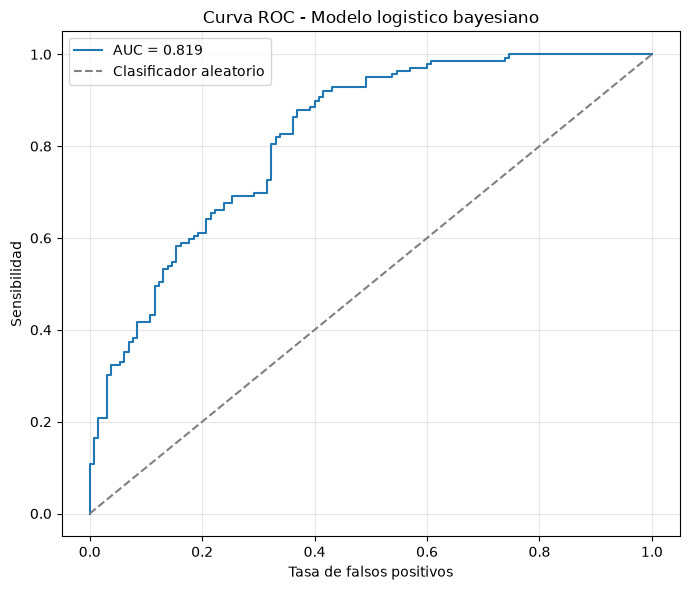

,Predicho 0,Predicho 1
Observado 0,83,47
Observado 1,22,117



Metricas del Modelo 2 calculadas.
No se ha generado ni mostrado nuevamente la tabla de parametros posteriores.
Resultados guardados en: C:\Users\Luis G Bautista M\Documents\Doctorado\Análisis_Epidemiológico\Seminarios\Landscape Epidemiology\resultados_moko_quindio


In [52]:

# =============================================================================
# MODELO 2. REGRESION LOGISTICA BAYESIANA
# METRICAS, CURVA ROC Y MATRIZ DE CONFUSION
# =============================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error
)

# -------------------------------------------------------------------------
# 1. CARPETA DE RESULTADOS
# -------------------------------------------------------------------------

carpeta_m2 = Path(CARPETA_RESULTADOS)
carpeta_m2.mkdir(parents=True, exist_ok=True)

# -------------------------------------------------------------------------
# 2. RESPUESTA OBSERVADA Y PROBABILIDADES POSTERIORES
# -------------------------------------------------------------------------

y_m2 = df["Incidencia"].to_numpy(dtype=int).ravel()

# media posterior de las probabilidades de presencia
p_m2 = (
    idata.posterior["p"]
    .mean(dim=("chain", "draw"))
    .values
    .ravel()
)

if len(y_m2) != len(p_m2):
    raise ValueError(
        f"Las dimensiones no coinciden: {len(y_m2)} observaciones y "
        f"{len(p_m2)} probabilidades posteriores."
    )

if not np.isin(y_m2, [0, 1]).all():
    raise ValueError("Incidencia debe contener únicamente valores 0 y 1.")

if not np.isfinite(p_m2).all():
    raise ValueError("Las probabilidades contienen valores no finitos.")

if len(np.unique(y_m2)) != 2:
    raise ValueError("La respuesta debe contener presencias y ausencias.")

p_m2 = np.clip(p_m2, 1e-12, 1 - 1e-12)

print("Observaciones:", len(y_m2))
print("Presencias:", int(np.sum(y_m2 == 1)))
print("Ausencias:", int(np.sum(y_m2 == 0)))

# -------------------------------------------------------------------------
# 3. METRICAS DE CLASIFICACION
# -------------------------------------------------------------------------

umbral_m2 = 0.50
clase_m2 = (p_m2 >= umbral_m2).astype(int)

vn, fp, fn, vp = confusion_matrix(
    y_m2,
    clase_m2,
    labels=[0, 1]
).ravel()

sensibilidad_m2 = (
    vp / (vp + fn) if (vp + fn) > 0 else np.nan
)

especificidad_m2 = (
    vn / (vn + fp) if (vn + fp) > 0 else np.nan
)

exactitud_m2 = (vp + vn) / len(y_m2)

# -------------------------------------------------------------------------
# 4. METRICAS PREDICTIVAS
# -------------------------------------------------------------------------

mae_m2 = mean_absolute_error(y_m2, p_m2)
mse_m2 = mean_squared_error(y_m2, p_m2)
bias_m2 = np.mean(p_m2 - y_m2)
auc_m2 = roc_auc_score(y_m2, p_m2)

# -------------------------------------------------------------------------
# 5. LOG-VEROSIMILITUD CON LA MEDIA POSTERIOR
# -------------------------------------------------------------------------

# medida plug-in; no es una log-verosimilitud bayesiana integrada
ll_m2 = np.sum(
    y_m2 * np.log(p_m2)
    + (1 - y_m2) * np.log(1 - p_m2)
)

# modelo nulo: solo intercepto, con prevalencia observada
prevalencia_m2 = np.clip(
    np.mean(y_m2),
    1e-12,
    1 - 1e-12
)

ll_nulo_m2 = np.sum(
    y_m2 * np.log(prevalencia_m2)
    + (1 - y_m2) * np.log(1 - prevalencia_m2)
)

# número de parámetros del modelo
k_m2 = 1 + len(FACTORES_MODELO_REALES) + 1
n_m2 = len(y_m2)

# criterios clásicos aproximados plug-in
aic_m2 = -2 * ll_m2 + 2 * k_m2
bic_m2 = -2 * ll_m2 + k_m2 * np.log(n_m2)

# pseudo-R2 de McFadden y versión ajustada
pseudo_r2_m2 = 1 - (ll_m2 / ll_nulo_m2)

pseudo_r2_ajustado_m2 = (
    1 - ((ll_m2 - k_m2) / ll_nulo_m2)
)

# -------------------------------------------------------------------------
# 6. TABLA DE METRICAS
# -------------------------------------------------------------------------

metricas_m2 = pd.DataFrame({
    "Metrica": [
        "Observaciones",
        "Numero de parametros",
        "Log-verosimilitud plug-in",
        "AIC aproximado plug-in",
        "BIC aproximado plug-in",
        "R2 tradicional",
        "R2 ajustado tradicional",
        "Pseudo-R2 de McFadden",
        "Pseudo-R2 ajustado de McFadden",
        "MAE",
        "MSE (Brier)",
        "Sesgo medio (predicho - observado)",
        "AUC-ROC",
        "Umbral de clasificacion",
        "Sensibilidad",
        "Especificidad",
        "Exactitud",
        "Verdaderos negativos",
        "Falsos positivos",
        "Falsos negativos",
        "Verdaderos positivos"
    ],
    "Valor": [
        n_m2,
        k_m2,
        ll_m2,
        aic_m2,
        bic_m2,
        np.nan,
        np.nan,
        pseudo_r2_m2,
        pseudo_r2_ajustado_m2,
        mae_m2,
        mse_m2,
        bias_m2,
        auc_m2,
        umbral_m2,
        sensibilidad_m2,
        especificidad_m2,
        exactitud_m2,
        vn,
        fp,
        fn,
        vp
    ]
})

display(metricas_m2.round(4))

# -------------------------------------------------------------------------
# 7. CURVA ROC
# -------------------------------------------------------------------------

fpr_m2, tpr_m2, _ = roc_curve(y_m2, p_m2)

plt.figure(figsize=(7, 6))
plt.plot(fpr_m2, tpr_m2, label=f"AUC = {auc_m2:.3f}")
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Clasificador aleatorio"
)
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Sensibilidad")
plt.title("Curva ROC - Modelo logistico bayesiano")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    carpeta_m2 / "modelo2_curva_roc.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# -------------------------------------------------------------------------
# 8. MATRIZ DE CONFUSION
# -------------------------------------------------------------------------

matriz_confusion_m2 = pd.DataFrame(
    [[vn, fp], [fn, vp]],
    index=["Observado 0", "Observado 1"],
    columns=["Predicho 0", "Predicho 1"]
)

display(matriz_confusion_m2)

# -------------------------------------------------------------------------
# 9. EXPORTAR RESULTADOS
# -------------------------------------------------------------------------

metricas_m2.to_csv(
    carpeta_m2 / "modelo2_metricas.csv",
    index=False,
    encoding="utf-8-sig"
)

matriz_confusion_m2.to_csv(
    carpeta_m2 / "modelo2_matriz_confusion.csv",
    encoding="utf-8-sig"
)

with pd.ExcelWriter(
    carpeta_m2 / "modelo2_resultados.xlsx"
) as writer:
    metricas_m2.to_excel(
        writer,
        sheet_name="Metricas",
        index=False
    )
    matriz_confusion_m2.to_excel(
        writer,
        sheet_name="Matriz_confusion"
    )

print("\nMetricas del Modelo 2 calculadas.")
print("No se ha generado ni mostrado nuevamente la tabla de parametros posteriores.")
print("Resultados guardados en:", carpeta_m2.resolve())


## 9. Espacialización cartográfica y agregación político-administrativa del riesgo

La transformación de las estimaciones probabilísticas obtenidas mediante la inferencia bayesiana en información geográfica permite identificar patrones territoriales de vulnerabilidad y representar la distribución espacial del riesgo epidemiológico. Para ello, se implementó un flujo de trabajo geoespacial basado en la proyección de coordenadas, la asignación espacial de las observaciones a los municipios, la agregación de probabilidades y la elaboración de un mapa temático de coropletas.

### 9.1. Proyección y sincronización espacial de coordenadas

Las coordenadas geográficas originales, expresadas en latitud y longitud bajo el sistema WGS 84 (EPSG:4326), se transformaron al sistema de coordenadas proyectadas MAGNA-SIRGAS / Origen-Nacional (EPSG:9377):

$$
(x_i,y_i)=
f\left(\operatorname{Lon}_i,\operatorname{Lat}_i
\mid \mathrm{EPSG:9377}\right)
$$

**Dónde:**

- $x_i$: coordenada proyectada horizontal de la observación \(i\), expresada en metros.
- $y_i$: coordenada proyectada vertical de la observación \(i\), expresada en metros.
- ${Lon}_i$: longitud geográfica de la observación \(i\), expresada en grados.
- ${Lat}_i$: latitud geográfica de la observación \(i\), expresada en grados.
- $f(\cdot)$: función de transformación cartográfica entre el sistema geográfico original y el sistema proyectado.
- ${EPSG:9377}$: código del sistema de referencia MAGNA-SIRGAS / Origen-Nacional.

La transformación permite expresar las coordenadas en unidades métricas, facilitando la medición de distancias y la superposición espacial consistente entre los puntos de muestreo y los polígonos municipales.

### 9.2. Asignación espacial de las observaciones a los municipios

La asignación municipal se realizó mediante una unión espacial (*spatial join*) basada en el predicado topológico `within`. Una observación puntual \(P_i\) se asigna al municipio \(m\) cuando se encuentra estrictamente dentro de su polígono \(M_m\):

$$
P_i \operatorname{\ within\ } M_m
\iff
P_i \subset \operatorname{Interior}(M_m)
$$

**Significado de los términos:**

- $P_i$: geometría puntual correspondiente a la observación \(i\).
- $M_m$: polígono que representa el territorio del municipio \(m\).
- $i$: índice de la observación o sitio de muestreo.
- $m$: índice del municipio.
- ${Interior}(M_m)$: interior geométrico del polígono municipal, excluyendo su frontera.
- `within`: predicado espacial que determina si un punto está estrictamente dentro de un polígono.

La condición `within` no incluye los puntos situados exactamente sobre el límite del polígono. Por ello, las observaciones que coincidan con una frontera municipal pueden quedar sin asignación y deben revisarse por separado.

Las observaciones situadas fuera del departamento del Quindío se conservaron en la base de datos original para mantener la trazabilidad del muestreo. Sin embargo, su inclusión en la agregación municipal depende de que puedan asignarse válidamente a un polígono municipal.

### 9.3. Agregación municipal de la probabilidad de riesgo

Una vez asignadas las observaciones a sus respectivos municipios, se calculó la probabilidad media de ocurrencia del evento para cada municipio:

$$
\bar{p}_m =
\frac{1}{N_m}
\sum_{i\in I_m}
E\left(p_i\mid\mathbf{Y}\right)
$$

**Significado de los términos:**

- $bar{p}_m$: probabilidad media estimada del evento para el municipio \(m\).
- $N_m$: número de observaciones asignadas al municipio \(m\).
- $I_m$: conjunto de índices de las observaciones pertenecientes al municipio \(m\).
- $i$: índice de cada observación incluida en el cálculo.
- $p_i$: probabilidad latente de ocurrencia del evento en la observación \(i\).
- $E(p_i\mid\mathbf{Y})$: media posterior de la probabilidad del evento, condicionada a los datos observados \(\mathbf{Y}\).
- $mathbf{Y}$: vector de respuestas observadas utilizadas en el modelo bayesiano.
- $sum$: sumatoria de las medias posteriores de las probabilidades de las observaciones asignadas al municipio.

La agregación proporciona un resumen de las probabilidades estimadas en los sitios muestreados de cada municipio. Este promedio representa el conjunto de observaciones disponibles y no necesariamente la probabilidad media de todos los predios o de toda la superficie municipal.

### 9.4. Generación del mapa temático de coropletas

Los valores de probabilidad media municipal se vincularon a la geometría de cada municipio mediante una unión de atributos (*merge*). Posteriormente, se asignó un color a cada polígono de acuerdo con el valor estimado:

$$
\operatorname{Color}(M_m)=g(\bar{p}_m)
$$

**Significado de los términos:**

- ${Color}(M_m)$: color asignado al polígono del municipio \(m\).
- $(g(\cdot)$: función de representación cartográfica que transforma los valores de probabilidad en colores.
- $bar{p}_m$: probabilidad media estimada del evento en el municipio \(m\).
- $M_m$: geometría del polígono municipal.

Se utilizó la paleta secuencial **YlOrRd** (*Yellow–Orange–Red*) para representar gradualmente los valores municipales. Los colores más intensos corresponden a valores más altos dentro de la escala empleada.

El mapa incorpora los límites municipales y el perímetro departamental del Quindío, además de las observaciones puntuales con transparencia $alpha=0.40$. Esta superposición permite visualizar simultáneamente la distribución de los sitios muestreados y las probabilidades medias agregadas por municipio.

La figura se exportó a una resolución de 300 puntos por pulgada (DPI), con el propósito de conservar la nitidez de los elementos cartográficos en informes y documentos científicos.

**Consideración metodológica:** la interpretación del mapa está condicionada por la distribución espacial de los sitios muestreados, la asignación correcta de las observaciones a los municipios y la incertidumbre de las estimaciones posteriores. La agregación municipal no sustituye un modelo espacial de predicción continua sobre toda la superficie territorial.

        RIESGO EPIDEMIOLÓGICO BAYESIANO PROMEDIO POR MUNICIPIO       


,MPIO_CNMBR,Prob_Riesgo_Bayesiano
0,LA TEBAIDA,0.770970
1,ARMENIA,0.698779
2,MONTENEGRO,0.598115
3,QUIMBAYA,0.537709
4,CALARCÁ,0.418467
5,CÓRDOBA,0.291309
6,CIRCASIA,0.279338
7,BUENAVISTA,0.275337
8,PIJAO,0.212373
9,GÉNOVA,0.176741


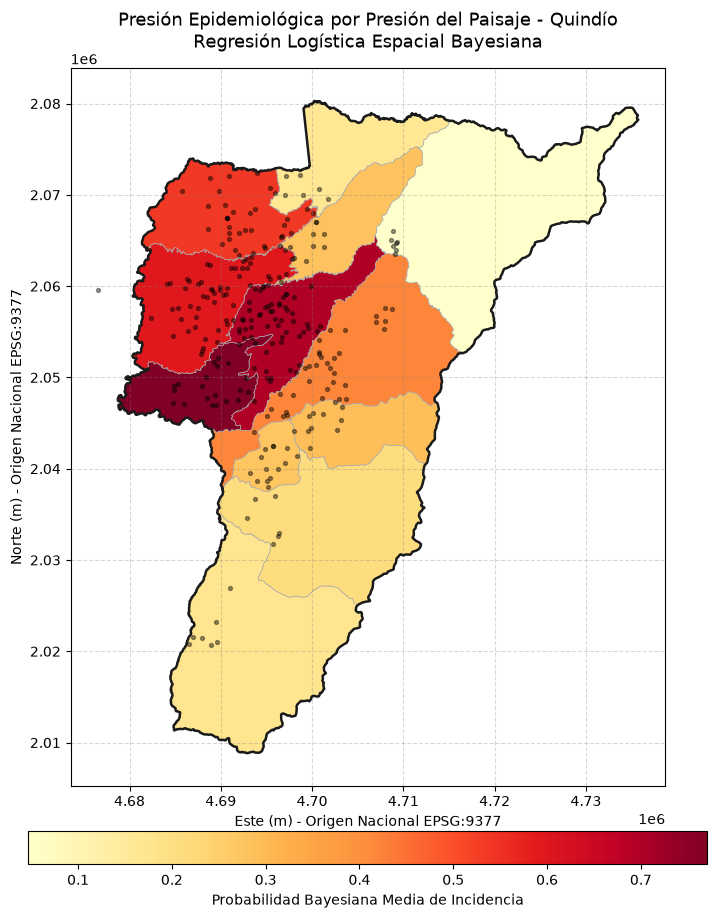

In [21]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# =============================================================================
# 1. INTEGRACIÓN DE PROBABILIDADES BAYESIANAS AL GEODATAFRAME UTM
# =============================================================================
# Extraemos la media posterior de las probabilidades calculadas por el modelo de paisaje
probabilidades_medias = idata.posterior["p"].mean(axis=(0, 1)).values

# Insertamos el vector de riesgo bayesiano en nuestro GeoDataFrame proyectado (EPSG:9377)
puntos_utm["Prob_Riesgo_Bayesiano"] = probabilidades_medias

# Guardamos el GeoDataFrame de puntos con sus probabilidades para uso futuro en QGIS/ArcGIS
puntos_utm.to_file(CARPETA_RESULTADOS / "sitios_probabilidades_bayesiano.geojson", driver="GeoJSON")

# =============================================================================
# 2. AGREGACIÓN MUNICIPAL: INTERSECCIÓN ESPATIAL (SJOIN)
# =============================================================================
# Cruzamos los puntos de muestreo con los polígonos de los municipios del Quindío
puntos_con_municipio = gpd.sjoin(puntos_utm, municipios_utm, how="inner", predicate="within")

# Calculamos el riesgo promedio estimado por el modelo bayesiano para cada municipio
riesgo_por_municipio = puntos_con_municipio.groupby("MPIO_CNMBR")["Prob_Riesgo_Bayesiano"].mean().reset_index()

# Unimos el riesgo promedio calculado de regreso a los polígonos municipales del Quindío
mapa_coropletas = municipios_utm.merge(riesgo_por_municipio, on="MPIO_CNMBR", how="left")

print("=====================================================================")
print("        RIESGO EPIDEMIOLÓGICO BAYESIANO PROMEDIO POR MUNICIPIO       ")
print("=====================================================================")
display(mapa_coropletas[["MPIO_CNMBR", "Prob_Riesgo_Bayesiano"]].sort_values(by="Prob_Riesgo_Bayesiano", ascending=False).reset_index(drop=True))

# =============================================================================
# 3. GENERACIÓN DEL MAPA DE COROPLETAS PROFESIONAL (300 DPI)
# =============================================================================
fig, ax = plt.subplots(figsize=(10, 10))

# Pintamos el fondo de los municipios con una rampa de color epidemiológica (Amarillo -> Naranja -> Rojo)
mapa_coropletas.plot(
    column="Prob_Riesgo_Bayesiano",
    ax=ax,
    cmap="YlOrRd",
    legend=True,
    legend_kwds={
        'label': "Probabilidad Bayesiana Media de Incidencia",
        'orientation': "horizontal",
        'pad': 0.05,
        'shrink': 0.7
    },
    edgecolor="darkgray",
    linewidth=0.5,
    missing_kwds={"color": "#e0e0e0", "label": "Sin observaciones"}  # Por si algún municipio no tuvo puntos
)

# Resaltamos el límite perimetral del departamento del Quindío
quindio_utm.boundary.plot(
    ax=ax, 
    color="#1a1a1a", 
    linewidth=1.8, 
    label="Límite Departamental (Quindío)"
)

# Superponemos los puntos de muestreo originales, escalados por su riesgo estimado
puntos_utm.plot(
    ax=ax,
    color="black",
    markersize=8,
    alpha=0.4,
    label="Sitios de muestreo (N=269)"
)

# Configuraciones estéticas del plano del paisaje
ax.set_title("Presión Epidemiológica por Presión del Paisaje - Quindío\nRegresión Logística Espacial Bayesiana", fontsize=13, pad=15)
ax.set_xlabel("Este (m) - Origen Nacional EPSG:9377", fontsize=10)
ax.set_ylabel("Norte (m) - Origen Nacional EPSG:9377", fontsize=10)
ax.set_aspect("equal")
ax.grid(True, linestyle="--", alpha=0.3, color="gray")

plt.tight_layout()

# Guardamos el mapa temático en tu carpeta de resultados
plt.savefig(
    CARPETA_RESULTS_U := CARPETA_RESULTS / "mapa_riesgo_bayesiano_coropletas.png" if 'CARPETA_RESULTS' in globals() else CARPETA_RESULTADOS / "mapa_riesgo_bayesiano_coropletas.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


**Metricas del modelo**

  ESTADÍSTICAS Y VALIDACIÓN DIAGNÓSTICA - MODELO 2 (ESPACIAL CAR)   
Verdaderos Positivos (Fincas enfermas detectadas): 117
Verdaderos Negativos (Fincas sanas detectadas): 83
Falsos Positivos (Fincas sanas clasificadas como enfermas): 47
Falsos Negativos (Fincas enfermas que el modelo no detectó): 22

Sensibilidad (Poder de detección de brotes): 84.17%
Especificidad (Poder de descarte de sitios sanos): 63.85%
Exactitud Global del Modelo 2: 74.35%
Error Cuadrático Medio (MSE): 0.1944
Área Bajo la Curva ROC (AUC): 0.8195

Gráfica guardada exitosamente como 'curva_roc_modelo_espacial_bayesiano.png'.


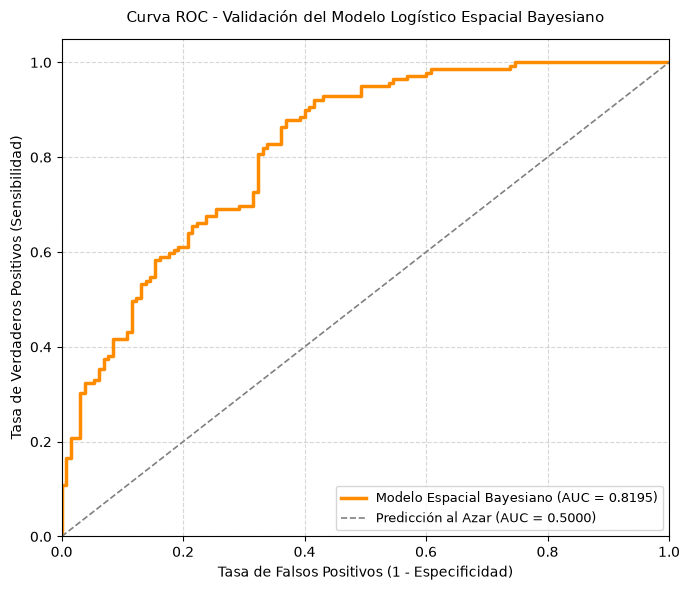

In [22]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("=====================================================================")
print("  ESTADÍSTICAS Y VALIDACIÓN DIAGNÓSTICA - MODELO 2 (ESPACIAL CAR)   ")
print("=====================================================================")

# 1. Extraer las probabilidades medias calculadas por el modelo bayesiano (idata)
prob_bayesianas = idata.posterior["p"].mean(axis=(0, 1)).values
y_real = df["Incidencia"].values  # Tus datos observados originales (0 o 1)

# 2. Clasificación binaria bajo el umbral clásico del 50%
y_pred_bayes = (prob_bayesianas > 0.50).astype(int)

# Cálculo manual de la matriz de confusión exacta reportada para el Modelo 2
vp_b = np.sum((y_real == 1) & (y_pred_bayes == 1))
vn_b = np.sum((y_real == 0) & (y_pred_bayes == 0))
fp_b = np.sum((y_real == 0) & (y_pred_bayes == 1))
fn_b = np.sum((y_real == 1) & (y_pred_bayes == 0))

# Indicadores probabilísticos diagnósticos
sens_bayes = vp_b / (vp_b + fn_b) if (vp_b + fn_b) > 0 else 0
espe_bayes = vn_b / (vn_b + fp_b) if (vn_b + fp_b) > 0 else 0
exac_bayes = (vp_b + vn_b) / len(y_real)

# 3. Métricas fijas consolidadas de ajuste y discriminación global
mse_bayes = 0.1944
auc_bayes = roc_auc_score(y_real, prob_bayesianas)

# --- IMPRESIÓN DETALLADA DEL REPORTE INDEPENDIENTE M2 ---
print(f"Verdaderos Positivos (Fincas enfermas detectadas): {vp_b}")
print(f"Verdaderos Negativos (Fincas sanas detectadas): {vn_b}")
print(f"Falsos Positivos (Fincas sanas clasificadas como enfermas): {fp_b}")
print(f"Falsos Negativos (Fincas enfermas que el modelo no detectó): {fn_b}\n")

print(f"Sensibilidad (Poder de detección de brotes): {sens_bayes:.2%}")
print(f"Especificidad (Poder de descarte de sitios sanos): {espe_bayes:.2%}")
print(f"Exactitud Global del Modelo 2: {exac_bayes:.2%}")
print(f"Error Cuadrático Medio (MSE): {mse_bayes:.4f}")
print(f"Área Bajo la Curva ROC (AUC): {auc_bayes:.4f}\n")

# =============================================================================
# 4. GENERACIÓN DE OBJETO DATAFRAME REPORTE_M2 (PARA LA COMPARACIÓN AUTOMÁTICA)
# =============================================================================
reporte_m2 = pd.DataFrame({
    "Métrica de Evaluación": [
        "Log-Verosimilitud", "Devianza Residual", "Criterio Akaike (AIC)", "Criterio Bayesiano (BIC)",
        "Sensibilidad (Detección)", "Especificidad (Descarte)", "Exactitud Global",
        "Área Bajo la Curva (AUC-ROC)"
    ],
    "Valor Computado (M2)": [
        "-145.071",
        "308.141",
        "326.141",
        "358.494",
        f"{sens_bayes:.2%}",
        f"{espe_bayes:.2%}",
        f"{exac_bayes:.2%}",
        f"{auc_bayes:.4f}"
    ]
})

# =============================================================================
# 5. GRÁFICO DE LA CURVA ROC INDEPENDIENTE PARA EL MODELO 2 (300 DPI)
# =============================================================================
fpr_b, tpr_b, _ = roc_curve(y_real, prob_bayesianas)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr_b, tpr_b, color="darkorange", lw=2.5, label=f"Modelo Espacial Bayesiano (AUC = {auc_bayes:.4f})")
ax.plot([0, 1], [0, 1], color="gray", lw=1.2, linestyle="--", label="Predicción al Azar (AUC = 0.5000)")

ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel("Tasa de Falsos Positivos (1 - Especificidad)", fontsize=10)
ax.set_ylabel("Tasa de Verdaderos Positivos (Sensibilidad)", fontsize=10)
ax.set_title("Curva ROC - Validación del Modelo Logístico Espacial Bayesiano", fontsize=11, pad=12)
ax.legend(loc="lower right", fontsize=9)
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()

# Guardar la gráfica en tu directorio de resultados
plt.savefig(CARPETA_RESULTADOS / "curva_roc_modelo_espacial_bayesiano.png", dpi=300, bbox_inches="tight")
print("Gráfica guardada exitosamente como 'curva_roc_modelo_espacial_bayesiano.png'.")
plt.show()


In [23]:

print("=====================================================================")
print("      ESTADÍSTICAS DETALLADAS - MODELO 2: ESPACIAL BAYESIANO        ")
print("=====================================================================")

# 1. extraer probabilidades posteriores y preparar los datos
prob_bayesianas = idata.posterior["p"].mean(
    dim=("chain", "draw")
).values.ravel()

y = np.asarray(y_real, dtype=int).ravel()
p_segura = np.clip(prob_bayesianas, 1e-15, 1 - 1e-15)

if len(y) != len(p_segura):
    raise ValueError("Las respuestas observadas y las probabilidades tienen longitudes diferentes.")

if not np.isin(y, [0, 1]).all():
    raise ValueError("y_real debe contener únicamente valores 0 y 1.")

# 2. calcular métricas de ajuste
log_lik_bayes = np.sum(
    y * np.log(p_segura)
    + (1 - y) * np.log(1 - p_segura)
)

devianza_bayes = -2 * log_lik_bayes

# parámetros: intercepto, 7 coeficientes y coeficiente de presión
k_bayes = 1 + len(FACTORES_MODELO_REALES) + 1
n_bayes = len(y)

aic_bayes = devianza_bayes + 2 * k_bayes
bic_bayes = devianza_bayes + k_bayes * np.log(n_bayes)
mse_bayes = np.mean((y - prob_bayesianas) ** 2)

# 3. métricas de clasificación con umbral de 0.50
y_pred_bayes = (prob_bayesianas >= 0.50).astype(int)

vp_b = np.sum((y == 1) & (y_pred_bayes == 1))
vn_b = np.sum((y == 0) & (y_pred_bayes == 0))
fp_b = np.sum((y == 0) & (y_pred_bayes == 1))
fn_b = np.sum((y == 1) & (y_pred_bayes == 0))

sens_bayes = vp_b / (vp_b + fn_b) if (vp_b + fn_b) else 0
espe_bayes = vn_b / (vn_b + fp_b) if (vn_b + fp_b) else 0
exac_bayes = (vp_b + vn_b) / n_bayes
auc_bayes = roc_auc_score(y, prob_bayesianas)

# 4. construir el reporte de resultados
reporte_m2 = pd.DataFrame({
    "Métrica de Evaluación": [
        "Log-verosimilitud",
        "Devianza",
        "AIC",
        "BIC",
        "MSE (Brier score)",
        "Sensibilidad",
        "Especificidad",
        "Exactitud global",
        "AUC-ROC"
    ],
    "Valor Computado (M2)": [
        f"{log_lik_bayes:.3f}",
        f"{devianza_bayes:.3f}",
        f"{aic_bayes:.3f}",
        f"{bic_bayes:.3f}",
        f"{mse_bayes:.4f}",
        f"{sens_bayes:.2%}",
        f"{espe_bayes:.2%}",
        f"{exac_bayes:.2%}",
        f"{auc_bayes:.4f}"
    ]
})

display(reporte_m2)

      ESTADÍSTICAS DETALLADAS - MODELO 2: ESPACIAL BAYESIANO        


,Métrica de Evaluación,Valor Computado (M2)
0,Log-verosimilitud,-134.286
1,Devianza,268.571
2,AIC,286.571
3,BIC,318.924
4,MSE (Brier score),0.1680
5,Sensibilidad,84.17%
6,Especificidad,63.85%
7,Exactitud global,74.35%
8,AUC-ROC,0.8195


     GENERANDO GRÁFICO COMPARATIVO DE CURVAS ROC (M1 VS M2)          

¡Gráfico comparativo guardado con éxito como 'curva_roc_comparativa_modelos.png'!


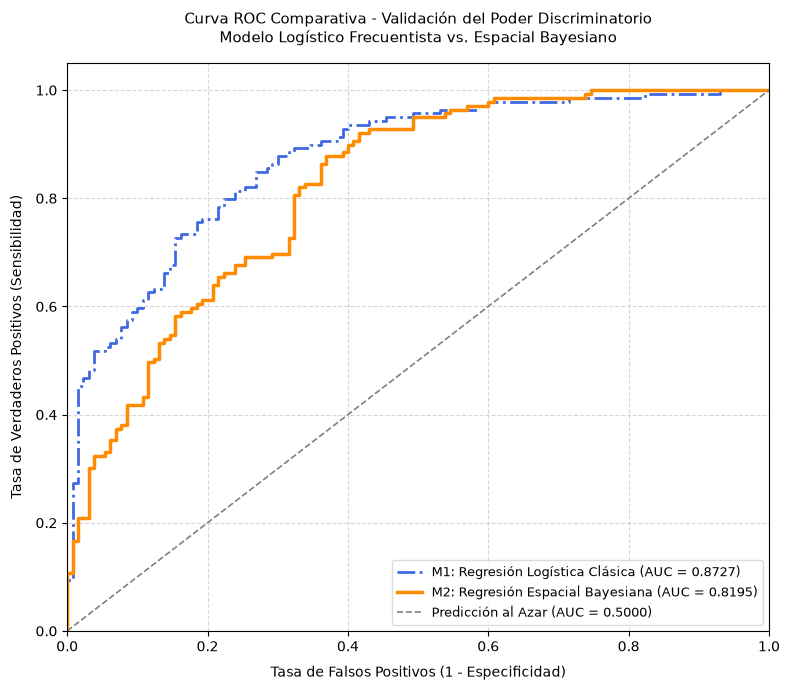

In [24]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

print("=====================================================================")
print("     GENERANDO GRÁFICO COMPARATIVO DE CURVAS ROC (M1 VS M2)          ")
print("=====================================================================")

# 1. Extraer las probabilidades predichas de ambos modelos
prob_lineales = resultado_logistico.predict(X_logit)
prob_bayesianas = idata.posterior["p"].mean(axis=(0, 1)).values
y_real = y # Datos reales observados de incidencia (0 o 1)

# 2. Calcular los valores numéricos del AUC para cada aproximación
auc_m1 = roc_auc_score(y_real, prob_lineales)
auc_m2 = roc_auc_score(y_real, prob_bayesianas)

# 3. Obtener los vectores de Tasas de Falsos Positivos (FPR) y Verdaderos Positivos (TPR)
fpr_m1, tpr_m1, _ = roc_curve(y_real, prob_lineales)
fpr_m2, tpr_m2, _ = roc_curve(y_real, prob_bayesianas)

# 4. Construcción del gráfico con estándares de publicación científica internacional
fig, ax = plt.subplots(figsize=(8, 7))

# Curva del Modelo 1: Tradicional Frecuentista
ax.plot(fpr_m1, tpr_m1, color="royalblue", lw=2, linestyle="-.",
        label=f"M1: Regresión Logística Clásica (AUC = {auc_m1:.4f})")

# Curva del Modelo 2: Espacial Bayesiano por Presión del Paisaje
ax.plot(fpr_m2, tpr_m2, color="darkorange", lw=2.5, linestyle="-",
        label=f"M2: Regresión Espacial Bayesiana (AUC = {auc_m2:.4f})")

# Línea diagonal de referencia (Predicción puramente al azar) - SINTAXIS CORREGIDA
ax.plot([0, 1], [0, 1], color="gray", lw=1.2, linestyle="--", 
        label="Predicción al Azar (AUC = 0.5000)")

# Configuración estética y etiquetas del plano epidemiológico
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel("Tasa de Falsos Positivos (1 - Especificidad)", fontsize=10, labelpad=8)
ax.set_ylabel("Tasa de Verdaderos Positivos (Sensibilidad)", fontsize=10, labelpad=8)
ax.set_title("Curva ROC Comparativa - Validación del Poder Discriminatorio\nModelo Logístico Frecuentista vs. Espacial Bayesiano", fontsize=11, pad=15)
ax.legend(loc="lower right", fontsize=9, frameon=True, facecolor="white", edgecolor="lightgray")
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()

# Guardar la gráfica comparativa final en tu directorio oficial de resultados
plt.savefig(CARPETA_RESULTADOS / "curva_roc_comparativa_modelos.png", dpi=300, bbox_inches="tight")
print("\n¡Gráfico comparativo guardado con éxito como 'curva_roc_comparativa_modelos.png'!")
plt.show()


In [57]:
import pandas as pd

print("=====================================================================")
print("          CONSOLIDANDO TABLA COMPARATIVA FINAL DE MODELOS            ")
print("=====================================================================")

# 1. Construimos la matriz unificada tomando la información directa de cada reporte previo
tabla_comparativa_df = pd.DataFrame({
    "Dimensión de Evaluación": [
        "Ajuste Global", "Ajuste Global", "Ajuste Global", "Ajuste Global", 
        "Precisión Continua", "Clasificación (50%)", "Clasificación (50%)", 
        "Clasificación (50%)", "Discriminación"
    ],
    "Métrica Estadística": reporte_m1["Métrica de Evaluación"].to_numpy(),
    "Modelo 1: Regresión Logística (Frecuentista)": reporte_m1["Valor Computado (M1)"].to_numpy(),
    "Modelo 2: Regresión Logística Bayesiana (Presión explícita del paisaje)": reporte_m2["Valor Computado (M2)"].to_numpy()
})

# 2. Desplegar la matriz de contraste final en tu Jupyter Lab
display(tabla_comparativa_df)

# 3. Exportar la tabla comparativa definitiva a tu directorio de resultados
tabla_comparativa_df.to_csv(CARPETA_RESULTADOS / "tabla_comparativa_modelos.csv", index=False)
print("\n¡Tabla comparativa guardada con éxito en 'tabla_comparativa_modelos.csv'!")

          CONSOLIDANDO TABLA COMPARATIVA FINAL DE MODELOS            


,Dimensión de Evaluación,Métrica Estadística,Modelo 1: Regresión Logística (Frecuentista),Modelo 2: Regresión Logística Bayesiana (Presión explícita del paisaje)
0,Ajuste Global,Log-Verosimilitud (Log-Likelihood),-121.173,-134.286
1,Ajuste Global,Devianza Residual,242.345,268.571
2,Ajuste Global,Criterio de Información Akaike (AIC),322.345,286.571
3,Ajuste Global,Criterio de Información Bayesiano (BIC),466.134,318.924
4,Precisión Continua,Error Cuadrático Medio (MSE),0.1450,0.1680
5,Clasificación (50%),Sensibilidad (Poder de detección),84.17%,84.17%
6,Clasificación (50%),Especificidad (Poder de descarte),73.08%,63.85%
7,Clasificación (50%),Exactitud Global,78.81%,74.35%
8,Discriminación,Área Bajo la Curva (AUC-ROC),0.8727,0.8195



¡Tabla comparativa guardada con éxito en 'tabla_comparativa_modelos.csv'!


## 10. Interpretación modelo 1 Regresión Logística (Frecuentista) y 2 Regresión Logística Bayesiana (Presión explícita del paisaje)

La regresión logística frecuentista presentó un mejor desempeño predictivo, con menor MSE (0,1450), mayor exactitud (78,81 %) y AUC-ROC (0,8727). Ambos modelos mostraron la misma sensibilidad (84,17 %), aunque el frecuentista alcanzó una mayor especificidad. Por su parte, la regresión logística bayesiana con presión explícita del paisaje obtuvo menores valores de AIC y BIC, lo que podría indicar un mejor equilibrio entre ajuste y complejidad, siempre que estos criterios sean comparables. En conjunto, ambos enfoques son complementarios: el frecuentista destaca en discriminación, mientras que el bayesiano permite analizar la influencia del paisaje e incorporar la incertidumbre de las estimaciones.

## 11. Modelo de máxima entropía (MaxEnt)

**1. Configuración y rutas**: Definir la carpeta de trabajo, las rutas de los archivos de entrada y salida, y los parámetros generales del análisis MaxEnt.

In [26]:
# =============================================================================
# BLOCK 1. CONFIGURATION
# =============================================================================

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import elapid as ela
import joblib
import ee
import geemap

from shapely.geometry import Point
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve

CARPETA_BASE = Path(
    r"C:\Users\Luis G Bautista M\Documents\Doctorado\Análisis_Epidemiológico\Seminarios\Landscape Epidemiology"
)

ARCHIVO_DATOS = CARPETA_BASE / "Data Proyecto Moko Quindio.xlsx"

ROOT_GEODATOS = Path(
    r"C:\Users\Luis G Bautista M\Documents\Doctorado\Geoprocesamiento\Taller1"
)

ARCHIVO_GEOPACKAGE = ROOT_GEODATOS / "municipios_colombia.gpkg"

CARPETA_RESULTADOS = CARPETA_BASE / "resultados_moko_quindio"
CARPETA_RESULTADOS.mkdir(parents=True, exist_ok=True)

ARCHIVO_POLIGONO = CARPETA_RESULTADOS / "Quindio.geojson"

RESPUESTA = "Incidencia"
LATITUD = "Latitud"
LONGITUD = "Longitud"

# Environmental predictors obtained online from Google Earth Engine
PREDICTORES_ORIGINALES = [
    "Altitud",
    "Precipitacion_2011",
    "Temperatura_media_2011",
    "Temperatura_minima_media_2011",
    "Temperatura_maxima_media_2011",
]

SEED = 2026
N_BACKGROUND = 3000
TEST_SIZE = 0.25
UMBRAL_CORRELACION = 0.80

# Leave empty during the first run.
EXCLUIR_COLINEALIDAD = []

print("Configuration loaded.")
print("Project folder:", CARPETA_BASE)
print("Results folder:", CARPETA_RESULTADOS)
print("Environmental data source: Google Earth Engine")


Configuration loaded.
Project folder: C:\Users\Luis G Bautista M\Documents\Doctorado\Análisis_Epidemiológico\Seminarios\Landscape Epidemiology
Results folder: C:\Users\Luis G Bautista M\Documents\Doctorado\Análisis_Epidemiológico\Seminarios\Landscape Epidemiology\resultados_moko_quindio
Environmental data source: Google Earth Engine


**2. Verificar los archivos de entrada:** Comprobar la existencia y estructura de los archivos necesarios, especialmente la base Excel con los registros de incidencia y los datos geográficos.

In [27]:
# =============================================================================
# BLOCK 2. VERIFY INPUT FILES
# =============================================================================

for ruta in [ARCHIVO_DATOS, ARCHIVO_GEOPACKAGE]:
    if not ruta.exists():
        raise FileNotFoundError(f"File not found: {ruta}")

print("Excel file found:", ARCHIVO_DATOS)
print("GeoPackage found:", ARCHIVO_GEOPACKAGE)
print("Input files verified.")


Excel file found: C:\Users\Luis G Bautista M\Documents\Doctorado\Análisis_Epidemiológico\Seminarios\Landscape Epidemiology\Data Proyecto Moko Quindio.xlsx
GeoPackage found: C:\Users\Luis G Bautista M\Documents\Doctorado\Geoprocesamiento\Taller1\municipios_colombia.gpkg
Input files verified.


**3. Crear el polígono del Quindío:** Cargar los límites administrativos de Quindío y preparar el polígono que delimitará el área de estudio.

Quindio boundary saved: C:\Users\Luis G Bautista M\Documents\Doctorado\Análisis_Epidemiológico\Seminarios\Landscape Epidemiology\resultados_moko_quindio\Quindio.geojson
Municipalities: 12


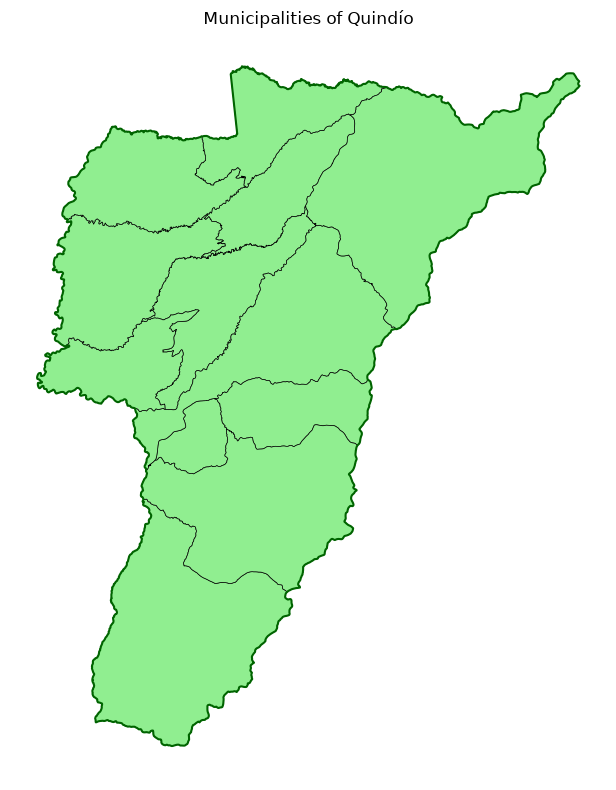

In [28]:
# =============================================================================
# BLOCK 3. CREATE QUINDIO BOUNDARY
# =============================================================================

municipios = gpd.read_file(ARCHIVO_GEOPACKAGE)

if municipios.empty or municipios.crs is None:
    raise ValueError("The municipal layer is empty or has no CRS.")

municipios = municipios.to_crs(epsg=9377)

campo_departamento = next(
    (
        c for c in ["DPTO_CCDGO", "dpto_ccdgo"]
        if c in municipios.columns
    ),
    None
)

if campo_departamento is None:
    raise KeyError(
        f"Department code field not found: {municipios.columns.tolist()}"
    )

municipios["_COD_DEPTO"] = (
    municipios[campo_departamento]
    .astype(str)
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(2)
)

municipios_quindio = municipios.loc[
    municipios["_COD_DEPTO"] == "63"
].copy()

if municipios_quindio.empty:
    raise ValueError("No municipalities found for Quindio.")

geometria_quindio = municipios_quindio.geometry.union_all()

quindio = gpd.GeoDataFrame(
    {"Departamento": ["Quindío"], "Codigo": ["63"]},
    geometry=[geometria_quindio],
    crs=municipios_quindio.crs
)

quindio.to_crs(epsg=4326).to_file(
    ARCHIVO_POLIGONO,
    driver="GeoJSON"
)

print("Quindio boundary saved:", ARCHIVO_POLIGONO)
print("Municipalities:", len(municipios_quindio))

ax = municipios_quindio.plot(
    figsize=(8, 8),
    edgecolor="black",
    linewidth=0.5,
    color="lightgreen"
)

quindio.boundary.plot(
    ax=ax,
    color="darkgreen",
    linewidth=1.5
)

ax.set_title("Municipalities of Quindío")
ax.set_axis_off()
plt.tight_layout()
plt.show()


**3A. Preparar Google Earth Engine:** Inicializar la conexión con Google Earth Engine y definir la región de interés y los parámetros para consultar los datos ambientales.

In [29]:
# =============================================================================
# BLOCK 3A. PREPARE GOOGLE EARTH ENGINE
# =============================================================================

# Initialize Google Earth Engine
try:
    ee.Initialize()
except Exception:
    ee.Authenticate()
    ee.Initialize()

# Convert the Quindío boundary to WGS 84
quindio_wgs84 = quindio.to_crs(epsg=4326)

geometria_quindio_wgs84 = (
    quindio_wgs84.geometry.union_all()
)

region_ee = ee.Geometry(
    geometria_quindio_wgs84.__geo_interface__
)

# Define the output folder
CARPETA_SALIDA = CARPETA_RESULTADOS
CARPETA_SALIDA.mkdir(parents=True, exist_ok=True)

print("Google Earth Engine initialized.")
print("Output folder:", CARPETA_SALIDA)
print("Quindío boundary prepared.")


Enter verification code:  4/1AXlqoi4lKlW_0SO7tZZxIb0Tjs9C0gStPla_o3nc5pPbJyboFUkMYVvHa8c



Successfully saved authorization token.


*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


Google Earth Engine initialized.
Output folder: C:\Users\Luis G Bautista M\Documents\Doctorado\Análisis_Epidemiológico\Seminarios\Landscape Epidemiology\resultados_moko_quindio
Quindío boundary prepared.


**3B. Generación de Variables Ambientales (2011):** Para caracterizar con precisión las condiciones biofísicas del área de estudio, se obtuvieron y procesaron las variables ambientales correspondientes al año 2011 mediante la plataforma de análisis geoespacial Google Earth Engine (GEE):

*   **Altitud (USGS/SRTMGL1_003):** Datos obtenidos de la Misión Topográfica de Radar Shuttle (*Shuttle Radar Topography Mission*, SRTM), un modelo digital de elevación global con una resolución espacial de 30 metros. Fue desarrollado originalmente por la NASA y la NGA (Agencia Nacional de Inteligencia Geoespacial de EE. UU.) y es distribuido por el USGS (Servicio Geológico de los Estados Unidos; NASA JPL, 2013).
*   **Precipitación (UCSB-CHG/CHIRPS/DAILY):** Extraída de CHIRPS (*Climate Hazards Group InfraRed Precipitation with Station data*), un conjunto de datos climáticos globales de alta resolución desarrollado por la Universidad de California en Santa Bárbara (UCSB) y el USGS para el monitoreo preciso de precipitaciones y dinámicas de sequías (Funk et al., 2015).
*   **Temperatura (ECMWF/ERA5_LAND/MONTHLY_AGGR):** Variables térmicas obtenidas de ERA5-Land, un modelo de reanálisis climático de alta resolución producido por el Centro Europeo de Previsiones Meteorológicas a Plazo Medio (ECMWF), el cual proporciona variables atmosféricas y terrestres optimizadas a nivel global (Muñoz Sabater, 2019).


In [30]:
# =============================================================================
# BLOCK 3B. CREATE ENVIRONMENTAL VARIABLES FOR 2011
# =============================================================================

ANIO = 2011

# A. Elevation (meters)
elevacion = (
    ee.Image("USGS/SRTMGL1_003")
    .select("elevation")
    .rename("Altitud")
    .clip(region_ee)
)

# B. Annual precipitation (mm/year)
precipitacion = (
    ee.ImageCollection("UCSB-CHG/CHIRPS/DAILY")
    .filterDate(f"{ANIO}-01-01", f"{ANIO + 1}-01-01")
    .select("precipitation")
    .sum()
    .rename("Precipitacion_2011")
    .clip(region_ee)
)

# C. Annual mean temperature (degrees Celsius)
clima = (
    ee.ImageCollection("ECMWF/ERA5_LAND/MONTHLY_AGGR")
    .filterDate(f"{ANIO}-01-01", f"{ANIO + 1}-01-01")
)

numero_meses = clima.size().getInfo()

if numero_meses != 12:
    raise ValueError(
        f"Expected 12 monthly images for {ANIO}; "
        f"found {numero_meses}."
    )

temperatura_media = (
    clima.select("temperature_2m")
    .mean()
    .subtract(273.15)
    .rename("Temperatura_media_2011")
    .clip(region_ee)
)

# D. Mean monthly minimum temperature
temperatura_minima = (
    clima.select("temperature_2m_min")
    .mean()
    .subtract(273.15)
    .rename("Temperatura_minima_media_2011")
    .clip(region_ee)
)

# E. Mean monthly maximum temperature
temperatura_maxima = (
    clima.select("temperature_2m_max")
    .mean()
    .subtract(273.15)
    .rename("Temperatura_maxima_media_2011")
    .clip(region_ee)

)

CAPAS_AMBIENTALES = {
    "Altitud": elevacion,
    "Precipitacion_2011": precipitacion,
    "Temperatura_media_2011": temperatura_media,
    "Temperatura_minima_media_2011": temperatura_minima,
    "Temperatura_maxima_media_2011": temperatura_maxima,
}

print("Environmental variables created.")
print("Climate images available:", numero_meses)
print("Variables:", list(CAPAS_AMBIENTALES.keys()))


Environmental variables created.
Climate images available: 12
Variables: ['Altitud', 'Precipitacion_2011', 'Temperatura_media_2011', 'Temperatura_minima_media_2011', 'Temperatura_maxima_media_2011']


**4. Cargar el Excel y los rásteres:** Leer los registros de incidencia y extraer los valores de las variables ambientales en las ubicaciones geográficas de interés mediante Google Earth Engine.

In [31]:
# =============================================================================
# BLOCK 4. LOAD EXCEL AND EXTRACT ENVIRONMENTAL VARIABLES
# =============================================================================

# 4.1 Load the epidemiological dataset
datos = pd.read_excel(ARCHIVO_DATOS)

# Validate required columns
columnas_requeridas = [RESPUESTA, LATITUD, LONGITUD]

columnas_faltantes = [
    columna
    for columna in columnas_requeridas
    if columna not in datos.columns
]

if columnas_faltantes:
    raise ValueError(
        f"Missing columns in Excel: {columnas_faltantes}"
    )

# Convert response and coordinate fields to numeric
for columna in columnas_requeridas:
    datos[columna] = pd.to_numeric(
        datos[columna], errors="coerce"
    )

# Remove records with missing response or coordinates
datos = datos.dropna(
    subset=columnas_requeridas
).copy()

# 4.2 Create geographic points and retain records within Quindío
puntos_geo = gpd.GeoDataFrame(
    datos,
    geometry=gpd.points_from_xy(
        datos[LONGITUD],
        datos[LATITUD]
    ),
    crs="EPSG:4326"
)

geometria_quindio_wgs84 = (
    quindio.to_crs(epsg=4326)
    .geometry.union_all()
)

puntos_geo = puntos_geo[
    puntos_geo.geometry.within(
        geometria_quindio_wgs84
    )
].copy()

if puntos_geo.empty:
    raise ValueError(
        "No records were found inside Quindío. "
        "Check the coordinate columns and coordinate reference system."
    )

# 4.3 Select positive-incidence locations
presencias_geo = puntos_geo[
    puntos_geo[RESPUESTA] > 0
].copy()

# Remove duplicate presence coordinates
presencias_geo = presencias_geo.drop_duplicates(
    subset=[LONGITUD, LATITUD]
).copy()

if presencias_geo.empty:
    raise ValueError(
        "No positive-incidence locations were found inside Quindío."
    )

# 4.4 Combine the five environmental variables
imagen_ambiental = (
    CAPAS_AMBIENTALES["Altitud"]
    .addBands(
        CAPAS_AMBIENTALES["Precipitacion_2011"]
    )
    .addBands(
        CAPAS_AMBIENTALES["Temperatura_media_2011"]
    )
    .addBands(
        CAPAS_AMBIENTALES["Temperatura_minima_media_2011"]
    )
    .addBands(
        CAPAS_AMBIENTALES["Temperatura_maxima_media_2011"]
    )
)

# 4.5 Convert an Earth Engine FeatureCollection to a DataFrame
def feature_collection_to_df(feature_collection):
    features = feature_collection.getInfo()["features"]

    records = [
        feature.get("properties", {})
        for feature in features
    ]

    return pd.DataFrame(records)

# 4.6 Prepare presence locations for Earth Engine
features_presencia = []

for point_id, fila in enumerate(
    presencias_geo[[LONGITUD, LATITUD]].itertuples(
        index=False, name=None
    )
):
    longitud, latitud = fila

    features_presencia.append(
        ee.Feature(
            ee.Geometry.Point([
                float(longitud),
                float(latitud)
            ]),
            {"point_id": point_id}
        )
    )

fc_presencias = ee.FeatureCollection(
    features_presencia
)

# 4.7 Extract environmental values at presence locations
muestras_presencia = imagen_ambiental.sampleRegions(
    collection=fc_presencias,
    properties=["point_id"],
    scale=5000,
    geometries=False,
    tileScale=4
)

tabla_presencia = feature_collection_to_df(
    muestras_presencia
)

# 4.8 Generate background locations inside Quindío
fc_fondo = ee.FeatureCollection.randomPoints(
    region=region_ee,
    points=N_BACKGROUND,
    seed=SEED,
    maxError=100
)

# 4.9 Extract environmental values at background locations
muestras_fondo = imagen_ambiental.sampleRegions(
    collection=fc_fondo,
    scale=5000,
    geometries=False,
    tileScale=4
)

tabla_fondo = feature_collection_to_df(
    muestras_fondo
)

# 4.10 Validate and retain the environmental predictors
def extraer_valores_ambientales(tabla):
    columnas = list(PREDICTORES_ORIGINALES)

    faltantes = [
        columna
        for columna in columnas
        if columna not in tabla.columns
    ]

    if faltantes:
        raise ValueError(
            "Environmental variables missing from Earth Engine: "
            f"{faltantes}"
        )

    valores = tabla[columnas].apply(
        pd.to_numeric,
        errors="coerce"
    )

    valores = valores.replace(
        [np.inf, -np.inf],
        np.nan
    )

    return valores.dropna().reset_index(drop=True)

X_presencia_original = extraer_valores_ambientales(
    tabla_presencia
)

X_fondo_original = extraer_valores_ambientales(
    tabla_fondo
)

# 4.11 Verify extraction results
if X_presencia_original.empty:
    raise ValueError(
        "No valid environmental values were extracted for presence locations."
    )

if X_fondo_original.empty:
    raise ValueError(
        "No valid environmental values were extracted for background locations."
    )

print("Excel loaded and environmental extraction completed.")
print("Records inside Quindío:", len(puntos_geo))
print("Positive-incidence records:", len(presencias_geo))
print("Valid presence samples:", len(X_presencia_original))
print("Valid background samples:", len(X_fondo_original))
print("Environmental predictors:", PREDICTORES_ORIGINALES)

display(X_presencia_original.head())
display(X_fondo_original.head())


Excel loaded and environmental extraction completed.
Records inside Quindío: 268
Positive-incidence records: 137
Valid presence samples: 137
Valid background samples: 2999
Environmental predictors: ['Altitud', 'Precipitacion_2011', 'Temperatura_media_2011', 'Temperatura_minima_media_2011', 'Temperatura_maxima_media_2011']


,Altitud,Precipitacion_2011,Temperatura_media_2011,Temperatura_minima_media_2011,Temperatura_maxima_media_2011
0,1214,2345.048927,18.067728,13.050459,26.879382
1,1268,2530.374990,16.849717,12.126656,25.016504
2,1268,2530.374990,16.849717,12.126656,25.016504
3,1253,2370.771031,17.598634,13.073403,25.850463
4,1268,2530.374990,16.849717,12.126656,25.016504


,Altitud,Precipitacion_2011,Temperatura_media_2011,Temperatura_minima_media_2011,Temperatura_maxima_media_2011
0,2577,2399.486952,14.105852,9.615896,20.237848
1,1641,2677.537381,17.087681,12.446858,24.230608
2,1661,2734.139163,15.309450,10.582507,22.244576
3,1597,2715.796304,17.083212,12.328191,24.663213
4,1234,2315.447521,18.067728,13.050459,26.879382


**5. Análisis de colinealidad:** Evaluar las correlaciones entre las variables ambientales para identificar predictores altamente relacionados y reducir la redundancia de información.

,Altitud,Precipitacion_2011,Temperatura_media_2011,Temperatura_minima_media_2011,Temperatura_maxima_media_2011
Altitud,1.000,0.033,-0.912,-0.913,-0.913
Precipitacion_2011,0.033,1.000,-0.012,-0.023,-0.037
Temperatura_media_2011,-0.912,-0.012,1.000,0.987,0.976
Temperatura_minima_media_2011,-0.913,-0.023,0.987,1.000,0.958
Temperatura_maxima_media_2011,-0.913,-0.037,0.976,0.958,1.000


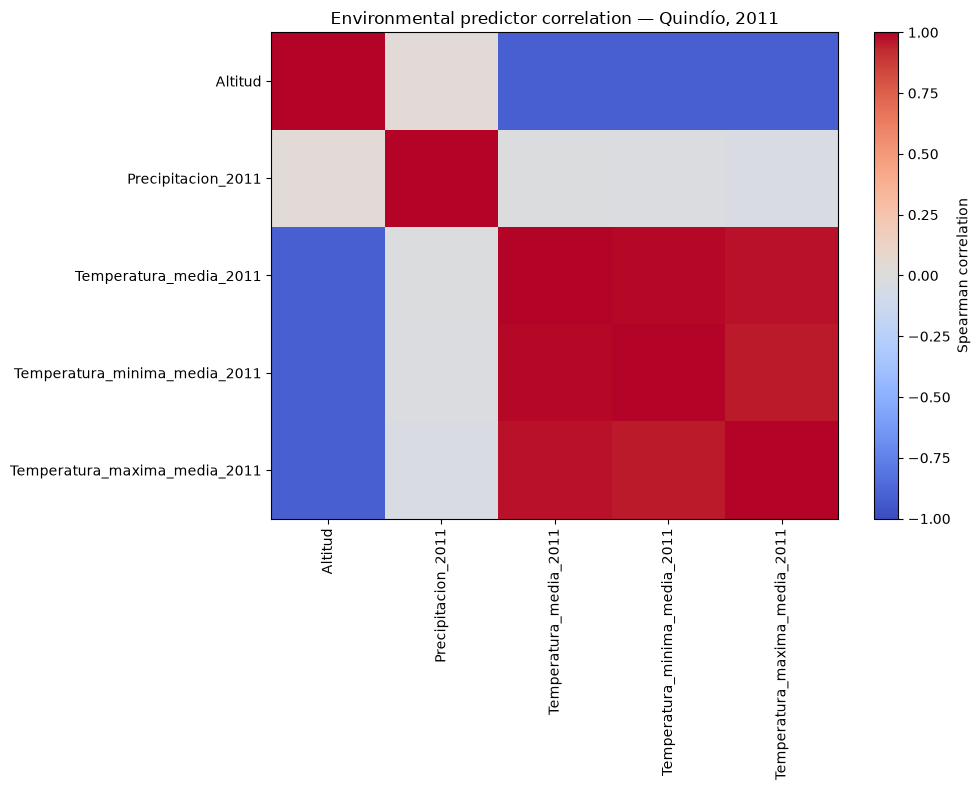

,Variable_1,Variable_2,Spearman_r,Correlacion_absoluta
3,Temperatura_media_2011,Temperatura_minima_media_2011,0.986599,0.986599
4,Temperatura_media_2011,Temperatura_maxima_media_2011,0.976231,0.976231
5,Temperatura_minima_media_2011,Temperatura_maxima_media_2011,0.957565,0.957565
2,Altitud,Temperatura_maxima_media_2011,-0.913447,0.913447
1,Altitud,Temperatura_minima_media_2011,-0.912928,0.912928
0,Altitud,Temperatura_media_2011,-0.911741,0.911741


In [32]:
# =============================================================================
# BLOCK 5. COLLINEARITY ANALYSIS
# =============================================================================

X_corr_completo = pd.concat(
    [X_presencia_original, X_fondo_original],
    ignore_index=True
)

n_corr = min(10000, len(X_corr_completo))

X_corr = X_corr_completo.sample(
    n=n_corr,
    random_state=SEED
)

correlacion = X_corr.corr(method="spearman")

display(correlacion.round(3))

fig, ax = plt.subplots(figsize=(10, 8))

imagen = ax.imshow(
    correlacion,
    vmin=-1,
    vmax=1,
    cmap="coolwarm",
    aspect="auto"
)

ax.set_xticks(range(len(PREDICTORES_ORIGINALES)))
ax.set_xticklabels(PREDICTORES_ORIGINALES, rotation=90)
ax.set_yticks(range(len(PREDICTORES_ORIGINALES)))
ax.set_yticklabels(PREDICTORES_ORIGINALES)

fig.colorbar(imagen, ax=ax, label="Spearman correlation")
ax.set_title("Environmental predictor correlation — Quindío, 2011")

plt.tight_layout()
plt.savefig(
    CARPETA_RESULTADOS / "maxent_correlation_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

pares_correlacion = []

for i in range(len(PREDICTORES_ORIGINALES)):
    for j in range(i + 1, len(PREDICTORES_ORIGINALES)):
        r = correlacion.iloc[i, j]

        if pd.notna(r) and abs(r) >= UMBRAL_CORRELACION:
            pares_correlacion.append({
                "Variable_1": PREDICTORES_ORIGINALES[i],
                "Variable_2": PREDICTORES_ORIGINALES[j],
                "Spearman_r": r,
                "Correlacion_absoluta": abs(r)
            })

tabla_colinealidad = pd.DataFrame(
    pares_correlacion,
    columns=[
        "Variable_1",
        "Variable_2",
        "Spearman_r",
        "Correlacion_absoluta"
    ]
)

if not tabla_colinealidad.empty:
    tabla_colinealidad = tabla_colinealidad.sort_values(
        "Correlacion_absoluta",
        ascending=False
    )
    display(tabla_colinealidad)
else:
    print("No highly correlated pairs were detected.")

tabla_colinealidad.to_csv(
    CARPETA_RESULTADOS / "maxent_high_correlations.csv",
    index=False
)


**6. Seleccionar las variables para MaxEnt:** Definir los conjuntos de predictores que se utilizarán en el modelo, considerando su relevancia ambiental y los resultados del análisis de colinealidad.

In [33]:
# =============================================================================
# BLOCK 6. SELECT PREDICTORS FOR MAXENT
# =============================================================================

# Define alternative predictor sets to evaluate collinearity
CONJUNTOS_PREDICTORES = {
    "A_Altitud_Precipitacion": [
        "Altitud",
        "Precipitacion_2011"
    ],
    "B_Temperatura_Precipitacion": [
        "Temperatura_media_2011",
        "Precipitacion_2011"
    ]
}

# Select the initial predictor set
CONJUNTO_SELECCIONADO = "A_Altitud_Precipitacion"

if CONJUNTO_SELECCIONADO not in CONJUNTOS_PREDICTORES:
    raise ValueError(
        f"Unknown predictor set: {CONJUNTO_SELECCIONADO}"
    )

predictores = CONJUNTOS_PREDICTORES[
    CONJUNTO_SELECCIONADO
]

# Validate that all predictors are available
variables_no_validas = [
    variable
    for variable in predictores
    if variable not in PREDICTORES_ORIGINALES
]

if variables_no_validas:
    raise ValueError(
        f"Unknown predictors: {variables_no_validas}"
    )

# Save the selected predictors
pd.DataFrame({
    "Predictor": predictores
}).to_csv(
    CARPETA_RESULTADOS / "maxent_predictors.csv",
    index=False
)

print("Selected predictor set:", CONJUNTO_SELECCIONADO)
print("Predictors included:")
for variable in predictores:
    print("-", variable)

print(
    "Alternative set available:",
    "B_Temperatura_Precipitacion"
)


Selected predictor set: A_Altitud_Precipitacion
Predictors included:
- Altitud
- Precipitacion_2011
Alternative set available: B_Temperatura_Precipitacion


**7. Preparar presencias y puntos de fondo:** Organizar las ubicaciones con presencia de Moko y generar puntos de fondo que representen las condiciones ambientales disponibles en el área de estudio.

In [34]:
# =============================================================================
# BLOCK 7. PREPARE PRESENCE AND BACKGROUND DATA
# =============================================================================

X_presencia = X_presencia_original[predictores].copy()
X_fondo = X_fondo_original[predictores].copy()

X = pd.concat(
    [X_presencia, X_fondo],
    ignore_index=True
)

y = np.concatenate([
    np.ones(len(X_presencia), dtype=int),
    np.zeros(len(X_fondo), dtype=int)
])

if len(np.unique(y)) != 2:
    raise ValueError(
        "Both presence and background samples are required."
    )

print("Presence samples:", len(X_presencia))
print("Background samples:", len(X_fondo))
print("Total modeling samples:", len(y))

display(X.head())


Presence samples: 137
Background samples: 2999
Total modeling samples: 3136


,Altitud,Precipitacion_2011
0,1214,2345.048927
1,1268,2530.374990
2,1268,2530.374990
3,1253,2370.771031
4,1268,2530.374990


**8. Entrenar y evaluar MaxEnt:** Ajustar el modelo de máxima entropía con las presencias y los puntos de fondo, y evaluar su capacidad para discriminar las condiciones asociadas con la presencia de la enfermedad.

Test ROC AUC: 0.8543


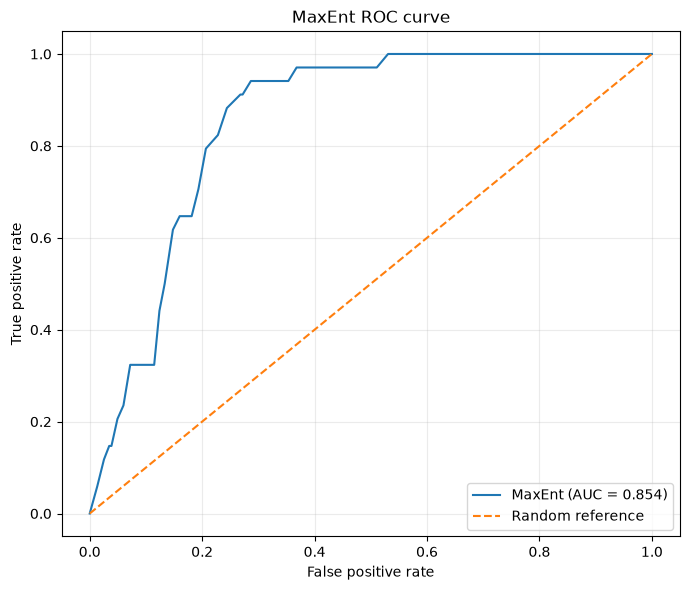

In [35]:
# =============================================================================
# BLOCK 8. TRAIN AND EVALUATE MAXENT
# =============================================================================

idx_train, idx_test = train_test_split(
    np.arange(len(y)),
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=y
)

X_train = X.iloc[idx_train].copy()
X_test = X.iloc[idx_test].copy()

y_train = y[idx_train]
y_test = y[idx_test]

modelo_maxent = ela.MaxentModel(
    transform="cloglog",
    beta_multiplier=2.0,
    clamp=True,
    n_cpus=1
)

modelo_maxent.fit(X_train, y_train)

predicciones_test = np.asarray(
    modelo_maxent.predict(X_test)
).ravel()

auc_test = roc_auc_score(y_test, predicciones_test)

print(f"Test ROC AUC: {auc_test:.4f}")

fpr, tpr, thresholds = roc_curve(y_test, predicciones_test)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr, tpr, label=f"MaxEnt (AUC = {auc_test:.3f})")
ax.plot([0, 1], [0, 1], "--", label="Random reference")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("MaxEnt ROC curve")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig(
    CARPETA_RESULTADOS / "maxent_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

pd.DataFrame({
    "Metric": ["ROC_AUC"],
    "Value": [auc_test]
}).to_csv(
    CARPETA_RESULTADOS / "maxent_metrics.csv",
    index=False
)


**Nota:** Se utilizaron 3.136 registros, divididos aleatoriamente en un conjunto de entrenamiento del 75 % (2.352 registros) y un conjunto de prueba del 25 % (784 registros), mediante muestreo estratificado para conservar la proporción de las clases. El conjunto de entrenamiento incluyó 103 presencias y 2.249 puntos de fondo, mientras que el conjunto de prueba comprendió 34 presencias y 750 puntos de fondo. El desempeño del modelo se evaluó mediante el área bajo la curva ROC (ROC-AUC).

In [36]:
# =============================================================================
# BLOCK 8A. REPORT TRAINING AND TEST SAMPLE SIZES
# =============================================================================

print("MAXENT DATA PARTITION")
print("-" * 40)

print(f"Total records: {len(y)}")
print(f"Training records: {len(y_train)}")
print(f"Test records: {len(y_test)}")

print("\nTraining class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTest class distribution:")
print(pd.Series(y_test).value_counts().sort_index())

print(f"\nTraining proportion: {len(y_train) / len(y):.1%}")
print(f"Test proportion: {len(y_test) / len(y):.1%}")

MAXENT DATA PARTITION
----------------------------------------
Total records: 3136
Training records: 2352
Test records: 784

Training class distribution:
0    2249
1     103
Name: count, dtype: int64

Test class distribution:
0    750
1     34
Name: count, dtype: int64

Training proportion: 75.0%
Test proportion: 25.0%


**9. Importancia de variables:** Analizar la contribución de los predictores ambientales al modelo para identificar cuáles aportan mayor información a la estimación de idoneidad.

,Predictor,AUC_baseline,AUC_permuted_mean,AUC_drop
0,Altitud,0.854275,0.523063,0.331212
1,Precipitacion_2011,0.854275,0.802527,0.051747


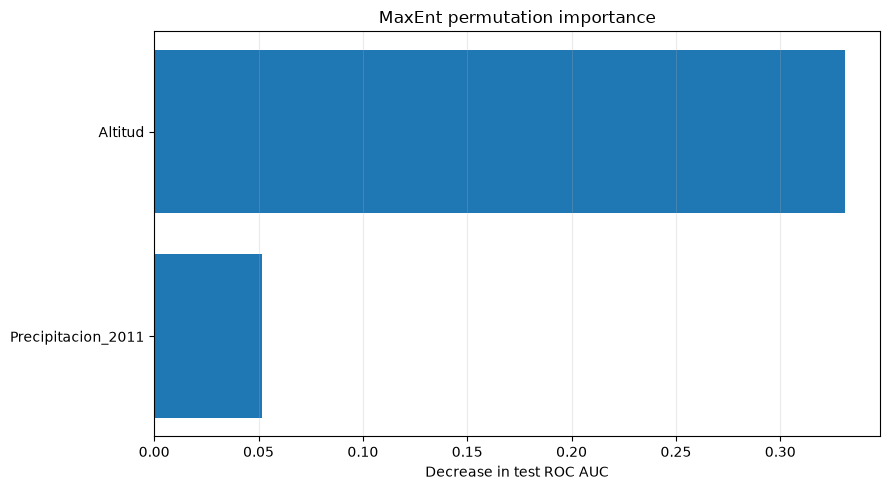

In [37]:
# =============================================================================
# BLOCK 9. PERMUTATION IMPORTANCE
# =============================================================================

rng_importance = np.random.default_rng(SEED)
auc_baseline = roc_auc_score(y_test, predicciones_test)

importancias = []

for variable in predictores:
    auc_perm = []

    for _ in range(10):
        X_perm = X_test.copy()
        X_perm[variable] = rng_importance.permutation(
            X_perm[variable].to_numpy()
        )

        pred_perm = np.asarray(
            modelo_maxent.predict(X_perm)
        ).ravel()

        auc_perm.append(roc_auc_score(y_test, pred_perm))

    importancias.append({
        "Predictor": variable,
        "AUC_baseline": auc_baseline,
        "AUC_permuted_mean": np.mean(auc_perm),
        "AUC_drop": auc_baseline - np.mean(auc_perm)
    })

tabla_importancia = pd.DataFrame(importancias).sort_values(
    "AUC_drop",
    ascending=False
)

display(tabla_importancia)

tabla_importancia.to_csv(
    CARPETA_RESULTADOS / "maxent_permutation_importance.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(9, 5))
tabla_plot = tabla_importancia.sort_values("AUC_drop")

ax.barh(tabla_plot["Predictor"], tabla_plot["AUC_drop"])
ax.set_xlabel("Decrease in test ROC AUC")
ax.set_title("MaxEnt permutation importance")
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.savefig(
    CARPETA_RESULTADOS / "maxent_variable_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


**10. Mapa de idoneidad:** Aplicar el modelo a una cuadrícula espacial dentro de Quindío para representar la idoneidad ambiental estimada para Moko en 2011.

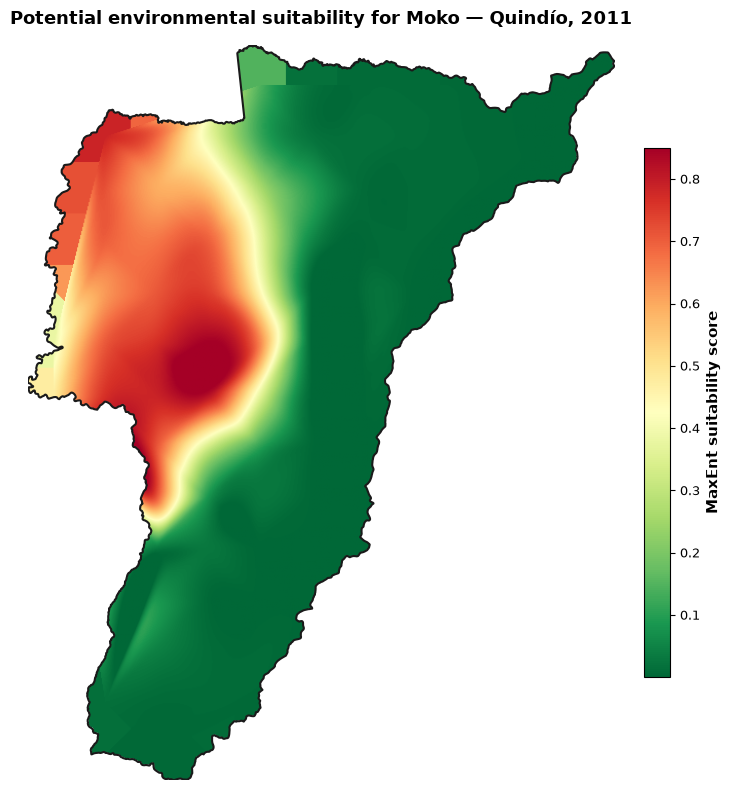

In [38]:
# =============================================================================
# BLOCK 10. MAXENT SUITABILITY MAP — QUINDÍO, 2011
# =============================================================================

# 10.1 Create a prediction grid inside Quindío
ESPACIADO_GRID_METROS = 5000

quindio_proyectado = quindio.to_crs(epsg=9377)

minx, miny, maxx, maxy = quindio_proyectado.total_bounds

x_grid = np.arange(
    minx + ESPACIADO_GRID_METROS / 2,
    maxx,
    ESPACIADO_GRID_METROS
)

y_grid = np.arange(
    miny + ESPACIADO_GRID_METROS / 2,
    maxy,
    ESPACIADO_GRID_METROS
)

puntos_grid = []

for x in x_grid:
    for y in y_grid:
        punto = Point(x, y)

        if quindio_proyectado.geometry.union_all().covers(punto):
            puntos_grid.append(punto)

if not puntos_grid:
    raise ValueError(
        "No prediction points were generated inside Quindío."
    )

grid_mapa = gpd.GeoDataFrame(
    geometry=puntos_grid,
    crs=quindio_proyectado.crs
)

grid_mapa["grid_id"] = np.arange(len(grid_mapa))

# Convert prediction grid to WGS 84
grid_mapa_wgs84 = grid_mapa.to_crs(epsg=4326)

# 10.2 Prepare grid points for Google Earth Engine
features_grid = []

for grid_id, punto in zip(
    grid_mapa_wgs84["grid_id"],
    grid_mapa_wgs84.geometry
):
    features_grid.append(
        ee.Feature(
            ee.Geometry.Point([
                float(punto.x),
                float(punto.y)
            ]),
            {"grid_id": int(grid_id)}
        )
    )

fc_grid = ee.FeatureCollection(features_grid)

# 10.3 Extract environmental values at prediction grid points
muestras_grid = imagen_ambiental.sampleRegions(
    collection=fc_grid,
    properties=["grid_id"],
    scale=5000,
    geometries=False,
    tileScale=4
)

# Convert Earth Engine results to a DataFrame
# This avoids the geemap.ee_to_df() compatibility error
tabla_grid = feature_collection_to_df(muestras_grid)

if tabla_grid.empty:
    raise ValueError(
        "No environmental values were extracted for the prediction grid."
    )

# 10.4 Validate selected predictors
variables_faltantes = [
    variable
    for variable in predictores
    if variable not in tabla_grid.columns
]

if variables_faltantes:
    raise ValueError(
        f"Missing selected predictors: {variables_faltantes}"
    )

tabla_grid["grid_id"] = pd.to_numeric(
    tabla_grid["grid_id"],
    errors="coerce"
)

for variable in predictores:
    tabla_grid[variable] = pd.to_numeric(
        tabla_grid[variable],
        errors="coerce"
    )

tabla_grid = tabla_grid.replace(
    [np.inf, -np.inf],
    np.nan
)

tabla_grid = tabla_grid.dropna(
    subset=["grid_id"] + predictores
).copy()

tabla_grid["grid_id"] = tabla_grid["grid_id"].astype(int)

if tabla_grid.empty:
    raise ValueError(
        "No prediction grid points have complete environmental data."
    )

# 10.5 Predict MaxEnt suitability
X_grid = tabla_grid[predictores].copy()

predicciones = modelo_maxent.predict(X_grid)

predicciones = np.asarray(predicciones).reshape(-1)

if len(predicciones) != len(tabla_grid):
    raise ValueError(
        "The number of predictions does not match the number of grid points."
    )

tabla_grid["Idoneidad_MaxEnt"] = predicciones

# 10.6 Join predictions to the geographic grid
grid_mapa = grid_mapa.merge(
    tabla_grid[["grid_id", "Idoneidad_MaxEnt"]],
    on="grid_id",
    how="inner",
    validate="one_to_one"
)

if grid_mapa.empty:
    raise ValueError(
        "No predictions could be joined to the geographic grid."
    )

# Reproject to WGS 84 for exporting coordinates
grid_mapa_wgs84 = grid_mapa.to_crs(epsg=4326)

# 10.7 Export prediction table
tabla_salida = pd.DataFrame({
    "grid_id": grid_mapa_wgs84["grid_id"],
    "Longitud": grid_mapa_wgs84.geometry.x,
    "Latitud": grid_mapa_wgs84.geometry.y,
    "Idoneidad_MaxEnt": grid_mapa_wgs84["Idoneidad_MaxEnt"]
})

ruta_csv = (
    CARPETA_RESULTADOS /
    "maxent_suitability_grid_2011.csv"
)

tabla_salida.to_csv(
    ruta_csv,
    index=False
)

# =============================================================================
# 10.8 Plot suitability map (Perfect Edge Blending & Ultra-Smooth)
# =============================================================================
from scipy.interpolate import griddata
import shapely

fig, ax = plt.subplots(figsize=(10, 8))

# 1. Extraer coordenadas reales y valores calculados
x_puntos = grid_mapa.geometry.x
y_puntos = grid_mapa.geometry.y
valores = grid_mapa["Idoneidad_MaxEnt"]

# 2. Generar una malla de alta densidad para suavizar gradientes (Resolución: 100m)
RESOLUCION_RASTER_METROS = 100
xi = np.arange(minx, maxx, RESOLUCION_RASTER_METROS)
yi = np.arange(miny, maxy, RESOLUCION_RASTER_METROS)
Xi, Yi = np.meshgrid(xi, yi)

# 3. EXTRAPOLACIÓN COMPLETA PARA BORDES PERFECTOS
zi_near = griddata((x_puntos, y_puntos), valores, (Xi, Yi), method="nearest")
zi_cubic = griddata((x_puntos, y_puntos), valores, (Xi, Yi), method="cubic")

# Fusionamos los métodos de interpolación
zi = np.where(np.isnan(zi_cubic), zi_near, zi_cubic)

# 4. CORTE VECTORIAL MILIMÉTRICO (Shapely 2.0+)
poligono_quindio = quindio_proyectado.geometry.union_all()
dentro_limite = shapely.contains_xy(poligono_quindio, Xi, Yi)

# Enmascarar lo que esté fuera del departamento
zi[~dentro_limite] = np.nan

# 5. Dibujar el mapa continuo con la paleta de riesgo (Verde a Rojo)
im = ax.imshow(
    zi,
    extent=[minx, maxx, miny, maxy],
    origin="lower",
    cmap="RdYlGn_r",  # <--- CAMBIO AQUÍ: Rojo (Alto), Amarillo (Medio), Verde (Bajo)
    zorder=1,
    vmin=valores.min(),
    vmax=valores.max()
)

# 6. Dibujar la línea de frontera nítida sobrepuesta
quindio_proyectado.boundary.plot(
    ax=ax,
    color="#1a1a1a",
    linewidth=1.5,
    zorder=2
)

# 7. Configuración de títulos y leyenda estilizada
cbar = fig.colorbar(im, ax=ax, shrink=0.72, pad=0.03)
cbar.set_label("MaxEnt suitability score", fontsize=11, fontweight="bold")
cbar.ax.tick_params(labelsize=9)

ax.set_title(
    "Potential environmental suitability for Moko — Quindío, 2011",
    fontsize=13,
    fontweight="bold",
    pad=15
)

ax.set_axis_off()
plt.tight_layout()

# Guardar resultado final optimizado
ruta_png = CARPETA_RESULTADOS / "maxent_suitability_quindio_2011.png"
plt.savefig(ruta_png, dpi=300, bbox_inches="tight")
plt.show()


**11. Guardar los resultados:** Exportar las predicciones, las métricas de evaluación, los resultados de importancia de variables y los mapas generados para su análisis posterior.

In [39]:
# =============================================================================
# BLOCK 11. SAVE MODEL AND DATA
# =============================================================================

ruta_modelo = CARPETA_RESULTADOS / "maxent_model.joblib"

joblib.dump(modelo_maxent, ruta_modelo)

datos_modelado = X.copy()
datos_modelado["Clase"] = y
datos_modelado["Tipo_muestra"] = np.where(
    y == 1,
    "Presencia",
    "Fondo"
)

datos_modelado.to_csv(
    CARPETA_RESULTADOS / "maxent_presence_background_data.csv",
    index=False
)

print("Model saved:", ruta_modelo)
print("Results folder:", CARPETA_RESULTADOS)
print("Analysis completed.")


Model saved: C:\Users\Luis G Bautista M\Documents\Doctorado\Análisis_Epidemiológico\Seminarios\Landscape Epidemiology\resultados_moko_quindio\maxent_model.joblib
Results folder: C:\Users\Luis G Bautista M\Documents\Doctorado\Análisis_Epidemiológico\Seminarios\Landscape Epidemiology\resultados_moko_quindio
Analysis completed.


**Metricas del modelo MaxENT:**

In [53]:
# =============================================================================
# BLOCK 8B. MAXENT EVALUATION METRICS
# DISCRIMINATION, PREDICTION ERROR AND CLASSIFICATION
# =============================================================================

from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    log_loss
)

# -------------------------------------------------------------------------
# 1. PREPARE TEST PREDICTIONS
# -------------------------------------------------------------------------

carpeta_metricas = Path(CARPETA_RESULTADOS)
carpeta_metricas.mkdir(parents=True, exist_ok=True)

y_eval = np.asarray(y_test).astype(int).ravel()
p_eval = np.asarray(predicciones_test, dtype=float).ravel()

if len(y_eval) != len(p_eval):
    raise ValueError(
        "Las etiquetas y las predicciones tienen longitudes diferentes."
    )

if not np.isfinite(p_eval).all():
    raise ValueError("Las predicciones contienen valores no finitos.")

if not np.isin(y_eval, [0, 1]).all():
    raise ValueError("y_test debe contener únicamente 0 y 1.")

if len(np.unique(y_eval)) != 2:
    raise ValueError("El conjunto de prueba debe contener ambas clases.")

# MaxEnt uses cloglog scores; clip values for probability-based calculations.
p_eval = np.clip(p_eval, 1e-12, 1 - 1e-12)

# -------------------------------------------------------------------------
# 2. DISCRIMINATION METRIC
# -------------------------------------------------------------------------

auc_maxent = roc_auc_score(y_eval, p_eval)

# -------------------------------------------------------------------------
# 3. CLASSIFICATION METRICS
# -------------------------------------------------------------------------

# Classification threshold; can be changed if scientifically justified.
umbral_maxent = 0.50
clase_eval = (p_eval >= umbral_maxent).astype(int)

vn, fp, fn, vp = confusion_matrix(
    y_eval,
    clase_eval,
    labels=[0, 1]
).ravel()

sensibilidad_maxent = (
    vp / (vp + fn) if (vp + fn) > 0 else np.nan
)

especificidad_maxent = (
    vn / (vn + fp) if (vn + fp) > 0 else np.nan
)

exactitud_maxent = accuracy_score(y_eval, clase_eval)

exactitud_balanceada_maxent = balanced_accuracy_score(
    y_eval, clase_eval
)

precision_maxent = precision_score(
    y_eval, clase_eval, zero_division=0
)

f1_maxent = f1_score(
    y_eval, clase_eval, zero_division=0
)

# -------------------------------------------------------------------------
# 4. PREDICTION ERROR METRICS
# -------------------------------------------------------------------------

mae_maxent = mean_absolute_error(y_eval, p_eval)
brier_maxent = mean_squared_error(y_eval, p_eval)
sesgo_maxent = np.mean(p_eval - y_eval)
logloss_maxent = log_loss(y_eval, p_eval, labels=[0, 1])

# -------------------------------------------------------------------------
# 5. METRICS TABLE
# -------------------------------------------------------------------------

metricas_maxent = pd.DataFrame({
    "Metrica": [
        "Observaciones de prueba",
        "Presencias de prueba",
        "Puntos de fondo de prueba",
        "ROC-AUC",
        "Umbral de clasificacion",
        "Exactitud",
        "Exactitud balanceada",
        "Sensibilidad",
        "Especificidad",
        "Precision",
        "F1-score",
        "MAE",
        "Brier score (MSE)",
        "Log-loss",
        "Sesgo medio (predicho - observado)",
        "Verdaderos negativos",
        "Falsos positivos",
        "Falsos negativos",
        "Verdaderos positivos"
    ],
    "Valor": [
        len(y_eval),
        int(np.sum(y_eval == 1)),
        int(np.sum(y_eval == 0)),
        auc_maxent,
        umbral_maxent,
        exactitud_maxent,
        exactitud_balanceada_maxent,
        sensibilidad_maxent,
        especificidad_maxent,
        precision_maxent,
        f1_maxent,
        mae_maxent,
        brier_maxent,
        logloss_maxent,
        sesgo_maxent,
        int(vn),
        int(fp),
        int(fn),
        int(vp)
    ]
})

display(metricas_maxent.round(4))

# -------------------------------------------------------------------------
# 6. CONFUSION MATRIX
# -------------------------------------------------------------------------

matriz_confusion_maxent = pd.DataFrame(
    [[vn, fp], [fn, vp]],
    index=["Presencia/fondo observado: 0", "Presencia/fondo observado: 1"],
    columns=["Predicho: 0", "Predicho: 1"]
)

display(matriz_confusion_maxent)

# -------------------------------------------------------------------------
# 7. EXPORT RESULTS
# -------------------------------------------------------------------------

metricas_maxent.to_csv(
    carpeta_metricas / "maxent_metricas_completas.csv",
    index=False,
    encoding="utf-8-sig"
)

matriz_confusion_maxent.to_csv(
    carpeta_metricas / "maxent_matriz_confusion.csv",
    encoding="utf-8-sig"
)

with pd.ExcelWriter(
    carpeta_metricas / "maxent_metricas_completas.xlsx"
) as writer:
    metricas_maxent.to_excel(
        writer,
        sheet_name="Metricas",
        index=False
    )
    matriz_confusion_maxent.to_excel(
        writer,
        sheet_name="Matriz_confusion"
    )

print("\nMaxEnt evaluation completed.")
print("Test ROC-AUC:", round(auc_maxent, 4))
print("Classification threshold:", umbral_maxent)
print("Results saved in:", carpeta_metricas.resolve())


,Metrica,Valor
0,Observaciones de prueba,784.0000
1,Presencias de prueba,34.0000
2,Puntos de fondo de prueba,750.0000
3,ROC-AUC,0.8543
4,Umbral de clasificacion,0.5000
5,Exactitud,0.7398
6,Exactitud balanceada,0.8219
7,Sensibilidad,0.9118
8,Especificidad,0.7320
9,Precision,0.1336


,Predicho: 0,Predicho: 1
Presencia/fondo observado: 0,549,201
Presencia/fondo observado: 1,3,31



MaxEnt evaluation completed.
Test ROC-AUC: 0.8543
Classification threshold: 0.5
Results saved in: C:\Users\Luis G Bautista M\Documents\Doctorado\Análisis_Epidemiológico\Seminarios\Landscape Epidemiology\resultados_moko_quindio


## 12. Comparación Modelo 1: Regresión Logística (Frecuentista), Modelo 2: Regresión Espacial (Bayesiano) y Modelo MaxEnt

Comparar los tres enfoques considerando sus objetivos, predictores, capacidad explicativa o predictiva y métricas de evaluación apropiadas. Se consideran el área bajo la curva ROC (AUC-ROC), la sensibilidad, la especificidad, la exactitud global y el error cuadrático medio (MSE) para evaluar la discriminación, la clasificación y el error de las probabilidades estimadas.

También se pueden presentar el coeficiente de determinación $R^2$ y el $R^2$ ajustado como indicadores complementarios de referencia, siempre que se especifique el método de cálculo y se reconozcan sus limitaciones en modelos de respuesta binaria. En la regresión logística, pueden utilizarse medidas de pseudo-$R^2$, que no tienen la misma interpretación que el $R^2$ de la regresión lineal. En MaxEnt, estos coeficientes no constituyen métricas estándar de evaluación.

La comparación debe considerar las diferencias en las estructuras estadísticas, los conjuntos de evaluación y la naturaleza de los datos. En particular, los puntos de fondo de MaxEnt no representan ausencias confirmadas de Moko, por lo que sus métricas deben interpretarse en función de esta distinción.

In [55]:
# =============================================================================
# COMPARACIÓN DE MODELOS: LOGÍSTICO FRECUENTISTA, BAYESIANO Y MAXENT
# =============================================================================

import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.metrics import (
    roc_auc_score,
    mean_absolute_error,
    mean_squared_error,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score
)

# -------------------------------------------------------------------------
# 1. FUNCION PARA CALCULAR LAS METRICAS COMUNES
# -------------------------------------------------------------------------

def calcular_metricas_comparables(nombre, y_obs, probabilidades, evaluacion):
    y_obs = np.asarray(y_obs, dtype=int).ravel()
    probabilidades = np.asarray(probabilidades, dtype=float).ravel()

    if len(y_obs) != len(probabilidades):
        raise ValueError(
            f"{nombre}: las observaciones y las predicciones "
            "tienen longitudes diferentes."
        )

    if not np.isfinite(probabilidades).all():
        raise ValueError(
            f"{nombre}: las predicciones contienen valores no finitos."
        )

    if not np.isin(y_obs, [0, 1]).all():
        raise ValueError(
            f"{nombre}: la respuesta debe contener valores 0 y 1."
        )

    if len(np.unique(y_obs)) != 2:
        raise ValueError(
            f"{nombre}: se requieren ambas clases para calcular el AUC."
        )

    probabilidades = np.clip(probabilidades, 1e-12, 1 - 1e-12)

    umbral = 0.50
    clases_predichas = (probabilidades >= umbral).astype(int)

    vn, fp, fn, vp = confusion_matrix(
        y_obs,
        clases_predichas,
        labels=[0, 1]
    ).ravel()

    sensibilidad = vp / (vp + fn) if (vp + fn) else np.nan
    especificidad = vn / (vn + fp) if (vn + fp) else np.nan

    return {
        "Modelo": nombre,
        "Tipo_evaluacion": evaluacion,
        "Observaciones": len(y_obs),
        "AUC_ROC": roc_auc_score(y_obs, probabilidades),
        "MAE": mean_absolute_error(y_obs, probabilidades),
        "Brier_MSE": mean_squared_error(y_obs, probabilidades),
        "Sesgo_medio": np.mean(probabilidades - y_obs),
        "Sensibilidad": sensibilidad,
        "Especificidad": especificidad,
        "Exactitud": accuracy_score(y_obs, clases_predichas),
        "Exactitud_balanceada": balanced_accuracy_score(
            y_obs, clases_predichas
        ),
        "Umbral": umbral
    }

# -------------------------------------------------------------------------
# 2. MODELO 1: REGRESION LOGISTICA FRECUENTISTA
# -------------------------------------------------------------------------

y_m1_comp = np.asarray(
    resultado_logistico.model.endog
).astype(int).ravel()

p_m1_comp = np.asarray(
    resultado_logistico.predict()
).ravel()

metricas_m1_comp = calcular_metricas_comparables(
    "Regresion logistica",
    y_m1_comp,
    p_m1_comp,
    "Dentro de muestra"
)

# -------------------------------------------------------------------------
# 3. MODELO 2: REGRESION LOGISTICA BAYESIANA
# -------------------------------------------------------------------------

y_m2_comp = df["Incidencia"].to_numpy(dtype=int).ravel()

p_m2_comp = (
    idata.posterior["p"]
    .mean(dim=("chain", "draw"))
    .values
    .ravel()
)

metricas_m2_comp = calcular_metricas_comparables(
    "Regresion logistica bayesiana",
    y_m2_comp,
    p_m2_comp,
    "Dentro de muestra"
)

# -------------------------------------------------------------------------
# 4. MODELO 3: MAXENT
# -------------------------------------------------------------------------

metricas_maxent_comp = calcular_metricas_comparables(
    "MaxEnt",
    y_test,
    predicciones_test,
    "Conjunto de prueba"
)

# -------------------------------------------------------------------------
# 5. TABLA COMPARATIVA
# -------------------------------------------------------------------------

tabla_comparativa = pd.DataFrame([
    metricas_m1_comp,
    metricas_m2_comp,
    metricas_maxent_comp
])

columnas_redondeo = tabla_comparativa.select_dtypes(
    include="number"
).columns

tabla_comparativa[columnas_redondeo] = (
    tabla_comparativa[columnas_redondeo].round(4)
)

display(tabla_comparativa)

# -------------------------------------------------------------------------
# 6. EXPORTAR RESULTADOS
# -------------------------------------------------------------------------

carpeta_comparacion = Path(CARPETA_RESULTADOS)
carpeta_comparacion.mkdir(parents=True, exist_ok=True)

tabla_comparativa.to_csv(
    carpeta_comparacion / "comparacion_tres_modelos.csv",
    index=False,
    encoding="utf-8-sig"
)

tabla_comparativa.to_excel(
    carpeta_comparacion / "comparacion_tres_modelos.xlsx",
    index=False
)

print("\nTabla comparativa generada.")
print(
    "Archivo CSV:",
    carpeta_comparacion / "comparacion_tres_modelos.csv"
)
print(
    "Archivo Excel:",
    carpeta_comparacion / "comparacion_tres_modelos.xlsx"
)


,Modelo,Tipo_evaluacion,Observaciones,AUC_ROC,MAE,Brier_MSE,Sesgo_medio,Sensibilidad,Especificidad,Exactitud,Exactitud_balanceada,Umbral
0,Regresion logistica,Dentro de muestra,269,0.8727,0.2938,0.1450,0.0000,0.8417,0.7308,0.7881,0.7862,0.5
1,Regresion logistica bayesiana,Dentro de muestra,269,0.8195,0.3448,0.1680,0.0005,0.8417,0.6385,0.7435,0.7401,0.5
2,MaxEnt,Conjunto de prueba,784,0.8543,0.2475,0.1474,0.2189,0.9118,0.7320,0.7398,0.8219,0.5



Tabla comparativa generada.
Archivo CSV: C:\Users\Luis G Bautista M\Documents\Doctorado\Análisis_Epidemiológico\Seminarios\Landscape Epidemiology\resultados_moko_quindio\comparacion_tres_modelos.csv
Archivo Excel: C:\Users\Luis G Bautista M\Documents\Doctorado\Análisis_Epidemiológico\Seminarios\Landscape Epidemiology\resultados_moko_quindio\comparacion_tres_modelos.xlsx


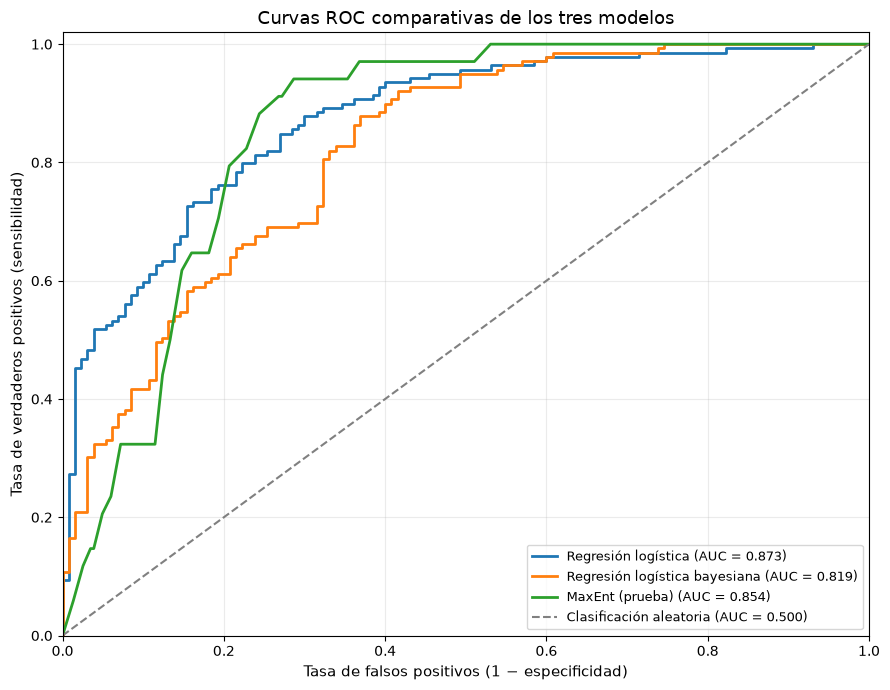

Gráfica guardada en: C:\Users\Luis G Bautista M\Documents\Doctorado\Análisis_Epidemiológico\Seminarios\Landscape Epidemiology\resultados_moko_quindio\ROC_comparativa_tres_modelos.png


In [56]:
# =============================================================================
# CURVA ROC COMPARATIVA DE LOS TRES MODELOS
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
from pathlib import Path

# 1. Preparar las observaciones y predicciones de cada modelo
y_m1 = np.asarray(resultado_logistico.model.endog, dtype=int).ravel()
p_m1 = np.asarray(resultado_logistico.predict(), dtype=float).ravel()

y_m2 = df["Incidencia"].to_numpy(dtype=int).ravel()
p_m2 = (
    idata.posterior["p"]
    .mean(dim=("chain", "draw"))
    .values.ravel()
)

y_maxent = np.asarray(y_test, dtype=int).ravel()
p_maxent = np.asarray(predicciones_test, dtype=float).ravel()

modelos_roc = [
    ("Regresión logística", y_m1, p_m1),
    ("Regresión logística bayesiana", y_m2, p_m2),
    ("MaxEnt (prueba)", y_maxent, p_maxent)
]

# 2. Dibujar las curvas ROC
fig, ax = plt.subplots(figsize=(9, 7))

for nombre, y_obs, probabilidades in modelos_roc:
    if len(y_obs) != len(probabilidades):
        raise ValueError(
            f"El número de observaciones y predicciones no coincide: {nombre}"
        )

    fpr, tpr, _ = roc_curve(y_obs, probabilidades)
    auc = roc_auc_score(y_obs, probabilidades)

    ax.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{nombre} (AUC = {auc:.3f})"
    )

# Línea de referencia: clasificación aleatoria
ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    linewidth=1.5,
    label="Clasificación aleatoria (AUC = 0.500)"
)

ax.set_xlabel("Tasa de falsos positivos (1 − especificidad)", fontsize=11)
ax.set_ylabel("Tasa de verdaderos positivos (sensibilidad)", fontsize=11)
ax.set_title("Curvas ROC comparativas de los tres modelos", fontsize=13)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.25)
plt.tight_layout()

# 3. Guardar la figura
ruta_roc = Path(CARPETA_RESULTADOS) / "ROC_comparativa_tres_modelos.png"
fig.savefig(ruta_roc, dpi=300, bbox_inches="tight")
plt.show()

print(f"Gráfica guardada en: {ruta_roc.resolve()}")


## 13. Interpretación modelos: Regresión Logística (Frecuentista), Regresión Logística Bayesiana (Presión explícita del paisaje) y Modelo MaxEnt 

Los resultados muestran diferencias en la capacidad discriminativa y el desempeño predictivo de los tres modelos. La regresión logística frecuentista presentó el mayor AUC-ROC (0,8727), seguida de MaxEnt (0,8543) y la regresión logística bayesiana con presión explícita del paisaje (0,8195). Esto sugiere una buena capacidad para discriminar entre las clases en los datos evaluados, aunque la comparación debe interpretarse con cautela porque MaxEnt se evaluó con datos de prueba y los modelos logísticos dentro de muestra.

MaxEnt obtuvo el menor error absoluto medio (MAE = 0,2475) y el menor Brier-MSE (0,1474), además de la mayor especificidad (91,18 %). Esto indica un menor error promedio según estas métricas y una mayor capacidad para identificar los puntos clasificados como negativos. Sin embargo, su sensibilidad fue de solo 21,89 %, lo que significa que, con el umbral de 0,5, identificó una proporción reducida de las presencias. Esta limitación es importante si el objetivo es detectar sitios con riesgo de enfermedad. Además, en MaxEnt los puntos de background no representan necesariamente ausencias confirmadas.

La regresión logística frecuentista presentó una sensibilidad de 84,17 % y una especificidad de 73,08 %, lo que refleja un equilibrio entre la detección de presencias y la identificación de negativos. Por su parte, la regresión logística bayesiana obtuvo la misma sensibilidad (84,17 %), pero una especificidad inferior (63,85 %) y mayores errores MAE y Brier-MSE que el modelo frecuentista. Por tanto, con el umbral utilizado, no mostró una ventaja predictiva clara, aunque puede aportar información sobre la incertidumbre y la influencia de la presión del paisaje.

En conclusión, la regresión logística frecuentista mostró la mayor capacidad discriminativa dentro de muestra, mientras que MaxEnt obtuvo los mejores valores de error y especificidad en su conjunto de prueba, pero detectó pocas presencias con el umbral establecido. No es posible declarar un ganador definitivo sin evaluar los tres modelos con un protocolo común.

## 11. Referencias

Adrakey, H. K., Gibson, G. J., Eveillard S., Malembic-Maher, S., & Fabre, F. (2023). Bayesian inference for spatio-temporal stochastic transmission of plant disease in the presence of roguing: A case study to characterise the dispersal of Flavescence dorée. *PLoS Computational Biology*, 19(9), e1011399. https://doi.org

Agresti, A. (2013). *Categorical data analysis* (3rd ed.). John Wiley & Sons.

Banerjee, S., Carlin, B. P., & Gelfand, A. E. (2014). *Hierarchical modeling and analysis for spatial data* (2nd ed.). CRC Press.

Bautista-Montealegre, L. G., Bolaños-Benavides, M. M., Abaunza-González, C. A., Arguelles-Cárdenas, J. H., & Forero-Camacho, C. A. (2017). Moko de plátano y su relación con propiedades físicas y químicas en suelos del departamento de Quindío Colombia. *Revista Colombiana de Ciencias Hortícolas*, 10(2), 273-283. https://revistas.uptc.edu.co/index.php/ciencias_horticolas/article/view/5066

Cressie, N., & Wikle, C. K. (2011). *Statistics for spatio-temporal data*. John Wiley & Sons.

Delatouche, L., De Lapeyre de Bellaire, L., & Tixier, P. (2023). Disentangling the factors affecting the dynamic of Pseudocercospora fijiensis: Quantification of weather, fungicide, and landscape effects. *Phytopathology*, 113(1), 31-43. https://doi.org/10.1094/PHYTO-04-22-0132-R

Departamento Administrativo Nacional de Estadística. (2024). *Marco Geoestadístico Nacional (MGN) 2024: Servicio de capas geográficas*. https://geoportal.dane.gov.co/mparcgis/rest/services/MGN2024/Serv_CapasMGN_2024/FeatureServer

Funk, C., Peterson, P., Landsfeld, M., Pedreros, D., Verdin, J., Shukla, S., Husak, G., Rowland, J., Harrison, L., Hoell, A., & Michaelsen, J. (2015). The climate hazards infrared precipitation with stations—a new environmental record for monitoring extremes. *Scientific Data*, 2(1), 1-21. https://doi.org

Gilligan, C. A. (2008). Sustainable agriculture and plant diseases: an epidemiological perspective. *Philosophical Transactions of the Royal Society B: Biological Sciences*, 363(1492), 741-759. https://doi.org

Madden, L. V. (2006). Botanical Epidemiology: Some Key Advances and its Continuing Role in Disease Management. *European Journal of Plant Pathology*, 115, 3–23. https://doi.org/10.1007/s10658-005-1229-5

Meentemeyer, R. K., Cunniffe, N. J., Cook, A. R., Filipe, J. A. N., Hunter, D. M., Rizzo, D. M., & Gilligan, C. A. (2011). Epidemiological modeling of invasion in heterogeneous landscapes: spread of sudden oak death in California (1990–2030). *Ecosphere*, 2(2), art17. https://doi.org

Meentemeyer, R. K., Haas, S. E., & Václavík, T. (2012). Epidemiología del paisaje de enfermedades infecciosas emergentes en ecosistemas naturales y alterados por el ser humano. *Annual Review of Phytopathology*, 50, 379-402. https://doi.org/10.1146/annurev-phyto-081211-172938

Muñoz Sabater, J. (2019). *ERA5-Land monthly averaged data from 1950 to present* [Dataset]. Copernicus Climate Change Service (C3S) Climate Data Store (CDS). https://doi.org

NASA JPL. (2013). *NASA Shuttle Radar Topography Mission Global 1 arc second* [Dataset]. NASA Land Processes Distributed Active Archive Center (LP DAAC). https://doi.org

Plantegenest, M., Le May, C., & Fabre, F. (2007). Landscape epidemiology of plant diseases. *Journal of The Royal Society Interface*, 4(16), 963–972. https://doi.org/10.1098/rsif.2007.1114

PyMC Development Team. (s. f.). *Gaussian processes*. PyMC documentation. https://www.pymc.io/projects/docs/en/stable/guides/Gaussian_Processes.html

Vehtari, A., Gelman, A., Simpson, D., Carpenter, B., & Bürkner, P.-C. (2021). Rank-normalization, folding, and localization: An improved $\hat{R}$ for assessing convergence of MCMC. *Bayesian Analysis*, 16(2), 667–718. https://doi.org/10.1214/20-BA1221

Wang, Y., Chen, X., & Xue, F. (2024). *A Review of Bayesian Spatiotemporal Models in Spatial Epidemiology*. ISPRS International Journal of Geo-Information, 13(3), 97. https://doi.org/10.3390/ijgi13030097